In [8]:
# ============================================================
# CELL 1: IMPORT REQUIRED LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 150)

print("All basic libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

All basic libraries imported successfully!
Pandas version: 3.0.6
NumPy version: 2.4.6


In [9]:
# ============================================================
# CELL 2: LOAD ORIGINAL EXCEL DATASET
# ============================================================

file_path = "Demand of last 2 years.xlsx"

# Check whether the file exists
if not os.path.exists(file_path):
    raise FileNotFoundError(
        f"File not found: {file_path}\n"
        "Place the Excel file in your project folder."
    )

# Read workbook sheet names
excel_file = pd.ExcelFile(file_path)

print("AVAILABLE EXCEL SHEETS:")
print(excel_file.sheet_names)

# Load the original training dataset
df = pd.read_excel(
    file_path,
    sheet_name="demand_training_data"
)

# Clean column names
df.columns = df.columns.astype(str).str.strip()

print("\nOriginal Excel dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

AVAILABLE EXCEL SHEETS:
['demand_training_data', 'data_dictionary', 'README', 'data_sources', 'quality_checks', 'Reference_Key_Spec', 'Product_Universe', 'Region_Week_Index', 'Backend_QA', 'Linked_Architecture']

Original Excel dataset loaded successfully!
Dataset shape: (27800, 44)

First 5 rows:


,demand_id,week_start_date,week_end_date,year,week_number,location_id,region_of_kolkata,demand_rank,product_id,product_name,category_name,brand,unit_size,weekday_weekend,weekday_units_sold,weekend_units_sold,units_sold,avg_selling_price_rs,promotion_flag,discount_pct,holiday_flag,festival_event,season,temperature_c,rainfall_mm,humidity_pct,weather_condition,stockout_flag,forecast_target_start,forecast_target_end,next_week_demand_target_units,data_source,recorded_at,region_week_key,region_product_week_key,assortment_size,rank_scope,rank_basis,selling_unit_workbook,selling_unit_sheet,selling_unit_source_row,selling_unit_lookup_hint,reference_layer,anchor_status
0,DEM-0000001,2024-01-01 00:00:00,2024-01-07 00:00:00,2024,1,KOL-LOC-001,Lake Gardens,1,DAI-005,Mother Dairy Curd,Dairy & Milk Products,Mother Dairy,500 g,Weekday,111,35,146,52.79,0,0,0,NaN,Winter,18.6,12.9,56.8,Clear/Partly Cloudy,0,2024-01-08 00:00:00,2024-01-14 00:00:00,152,SYNTHETIC_TRAINING | SUPPLIED_WEATHER | SUPPLI...,46279.694444,KOL-LOC-001_20240101,KOL-LOC-001_20240101_DAI-005,200,region-week over all 200 products,units_sold DESC; sales_value_rs DESC; product_...,Regional_Selling_Unit_40Regions_200Products_13...,W001_2024-01-01,3,'W001_2024-01-01'!A3,regional_selling_unit_reference,observed_top5_anchor
1,DEM-0000002,2024-01-01 00:00:00,2024-01-07 00:00:00,2024,1,KOL-LOC-001,Lake Gardens,2,TEA-009,Bru Instant Coffee,Tea & Coffee,Bru,100 g,Weekday,75,23,98,273.60,0,0,0,NaN,Winter,18.6,12.9,56.8,Clear/Partly Cloudy,0,2024-01-08 00:00:00,2024-01-14 00:00:00,110,SYNTHETIC_TRAINING | SUPPLIED_WEATHER | SUPPLI...,46279.694444,KOL-LOC-001_20240101,KOL-LOC-001_20240101_TEA-009,200,region-week over all 200 products,units_sold DESC; sales_value_rs DESC; product_...,Regional_Selling_Unit_40Regions_200Products_13...,W001_2024-01-01,4,'W001_2024-01-01'!A4,regional_selling_unit_reference,observed_top5_anchor
2,DEM-0000003,2024-01-01 00:00:00,2024-01-07 00:00:00,2024,1,KOL-LOC-001,Lake Gardens,3,TEA-002,Tata Tea Premium,Tea & Coffee,Tata Tea,500 g,Weekday,71,23,94,293.38,0,0,0,NaN,Winter,18.6,12.9,56.8,Clear/Partly Cloudy,0,2024-01-08 00:00:00,2024-01-14 00:00:00,97,SYNTHETIC_TRAINING | SUPPLIED_WEATHER | SUPPLI...,46279.694444,KOL-LOC-001_20240101,KOL-LOC-001_20240101_TEA-002,200,region-week over all 200 products,units_sold DESC; sales_value_rs DESC; product_...,Regional_Selling_Unit_40Regions_200Products_13...,W001_2024-01-01,5,'W001_2024-01-01'!A5,regional_selling_unit_reference,observed_top5_anchor
3,DEM-0000004,2024-01-01 00:00:00,2024-01-07 00:00:00,2024,1,KOL-LOC-001,Lake Gardens,4,BEV-007,Frooti Mango,Soft Drinks & Beverages,Parle Agro,500 ml,Weekday,66,20,86,38.36,0,0,0,NaN,Winter,18.6,12.9,56.8,Clear/Partly Cloudy,0,2024-01-08 00:00:00,2024-01-14 00:00:00,84,SYNTHETIC_TRAINING | SUPPLIED_WEATHER | SUPPLI...,46279.694444,KOL-LOC-001_20240101,KOL-LOC-001_20240101_BEV-007,200,region-week over all 200 products,units_sold DESC; sales_value_rs DESC; product_...,Regional_Selling_Unit_40Regions_200Products_13...,W001_2024-01-01,6,'W001_2024-01-01'!A6,regional_selling_unit_reference,observed_top5_anchor
4,DEM-0000005,2024-01-01 00:00:00,2024-01-07 00:00:00,2024,1,KOL-LOC-001,Lake Gardens,5,INS-008,Kellogg's Corn Flakes,Instant & Packaged Foods,Kellogg's,250 g,Weekday,62,21,83,78.95,0,0,0,NaN,Winter,18.6,12.9,56.8,Clear/Partly Cloudy,0,2024-01-08 00:00:00,2024-01-14 00:00:00,72,SYNTHETIC_TRAINING | SUPPLIED_WEATHER | SUPPLI...,46279.694444,KOL-LOC-001_20240101,KOL-LOC-001_20240101_INS-008,200,region-week over all 200 products,units_sold DESC; sales_value_rs DESC; product_...,Regional_Selling_Unit_40Regions_200Products_13...,W001_2024-01-01,7,'W001_2024-01-01'!A7,regional_selling_unit_reference,observed_top5_anchor


In [10]:
# ============================================================
# CELL 3: DATASET OVERVIEW
# ============================================================

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

# Dataset dimensions
print("\n1. DATASET SHAPE")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

# Column names
print("\n2. ALL COLUMN NAMES")

for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

# Data types
print("\n3. DATA TYPES")
display(df.dtypes.to_frame(name="Data Type"))

# First 5 records
print("\n4. FIRST 5 RECORDS")
display(df.head())

# Last 5 records
print("\n5. LAST 5 RECORDS")
display(df.tail())

# Dataset information
print("\n6. DATASET INFORMATION")
df.info()

print("\nCELL 3 COMPLETED SUCCESSFULLY!")

DATASET OVERVIEW

1. DATASET SHAPE
Total rows: 27800
Total columns: 44

2. ALL COLUMN NAMES
1. demand_id
2. week_start_date
3. week_end_date
4. year
5. week_number
6. location_id
7. region_of_kolkata
8. demand_rank
9. product_id
10. product_name
11. category_name
12. brand
13. unit_size
14. weekday_weekend
15. weekday_units_sold
16. weekend_units_sold
17. units_sold
18. avg_selling_price_rs
19. promotion_flag
20. discount_pct
21. holiday_flag
22. festival_event
23. season
24. temperature_c
25. rainfall_mm
26. humidity_pct
27. weather_condition
28. stockout_flag
29. forecast_target_start
30. forecast_target_end
31. next_week_demand_target_units
32. data_source
33. recorded_at
34. region_week_key
35. region_product_week_key
36. assortment_size
37. rank_scope
38. rank_basis
39. selling_unit_workbook
40. selling_unit_sheet
41. selling_unit_source_row
42. selling_unit_lookup_hint
43. reference_layer
44. anchor_status

3. DATA TYPES


,Data Type
demand_id,str
week_start_date,object
week_end_date,object
year,int64
week_number,int64
location_id,str
region_of_kolkata,str
demand_rank,int64
product_id,str
product_name,str



4. FIRST 5 RECORDS


,demand_id,week_start_date,week_end_date,year,week_number,location_id,region_of_kolkata,demand_rank,product_id,product_name,category_name,brand,unit_size,weekday_weekend,weekday_units_sold,weekend_units_sold,units_sold,avg_selling_price_rs,promotion_flag,discount_pct,holiday_flag,festival_event,season,temperature_c,rainfall_mm,humidity_pct,weather_condition,stockout_flag,forecast_target_start,forecast_target_end,next_week_demand_target_units,data_source,recorded_at,region_week_key,region_product_week_key,assortment_size,rank_scope,rank_basis,selling_unit_workbook,selling_unit_sheet,selling_unit_source_row,selling_unit_lookup_hint,reference_layer,anchor_status
0,DEM-0000001,2024-01-01 00:00:00,2024-01-07 00:00:00,2024,1,KOL-LOC-001,Lake Gardens,1,DAI-005,Mother Dairy Curd,Dairy & Milk Products,Mother Dairy,500 g,Weekday,111,35,146,52.79,0,0,0,NaN,Winter,18.6,12.9,56.8,Clear/Partly Cloudy,0,2024-01-08 00:00:00,2024-01-14 00:00:00,152,SYNTHETIC_TRAINING | SUPPLIED_WEATHER | SUPPLI...,46279.694444,KOL-LOC-001_20240101,KOL-LOC-001_20240101_DAI-005,200,region-week over all 200 products,units_sold DESC; sales_value_rs DESC; product_...,Regional_Selling_Unit_40Regions_200Products_13...,W001_2024-01-01,3,'W001_2024-01-01'!A3,regional_selling_unit_reference,observed_top5_anchor
1,DEM-0000002,2024-01-01 00:00:00,2024-01-07 00:00:00,2024,1,KOL-LOC-001,Lake Gardens,2,TEA-009,Bru Instant Coffee,Tea & Coffee,Bru,100 g,Weekday,75,23,98,273.60,0,0,0,NaN,Winter,18.6,12.9,56.8,Clear/Partly Cloudy,0,2024-01-08 00:00:00,2024-01-14 00:00:00,110,SYNTHETIC_TRAINING | SUPPLIED_WEATHER | SUPPLI...,46279.694444,KOL-LOC-001_20240101,KOL-LOC-001_20240101_TEA-009,200,region-week over all 200 products,units_sold DESC; sales_value_rs DESC; product_...,Regional_Selling_Unit_40Regions_200Products_13...,W001_2024-01-01,4,'W001_2024-01-01'!A4,regional_selling_unit_reference,observed_top5_anchor
2,DEM-0000003,2024-01-01 00:00:00,2024-01-07 00:00:00,2024,1,KOL-LOC-001,Lake Gardens,3,TEA-002,Tata Tea Premium,Tea & Coffee,Tata Tea,500 g,Weekday,71,23,94,293.38,0,0,0,NaN,Winter,18.6,12.9,56.8,Clear/Partly Cloudy,0,2024-01-08 00:00:00,2024-01-14 00:00:00,97,SYNTHETIC_TRAINING | SUPPLIED_WEATHER | SUPPLI...,46279.694444,KOL-LOC-001_20240101,KOL-LOC-001_20240101_TEA-002,200,region-week over all 200 products,units_sold DESC; sales_value_rs DESC; product_...,Regional_Selling_Unit_40Regions_200Products_13...,W001_2024-01-01,5,'W001_2024-01-01'!A5,regional_selling_unit_reference,observed_top5_anchor
3,DEM-0000004,2024-01-01 00:00:00,2024-01-07 00:00:00,2024,1,KOL-LOC-001,Lake Gardens,4,BEV-007,Frooti Mango,Soft Drinks & Beverages,Parle Agro,500 ml,Weekday,66,20,86,38.36,0,0,0,NaN,Winter,18.6,12.9,56.8,Clear/Partly Cloudy,0,2024-01-08 00:00:00,2024-01-14 00:00:00,84,SYNTHETIC_TRAINING | SUPPLIED_WEATHER | SUPPLI...,46279.694444,KOL-LOC-001_20240101,KOL-LOC-001_20240101_BEV-007,200,region-week over all 200 products,units_sold DESC; sales_value_rs DESC; product_...,Regional_Selling_Unit_40Regions_200Products_13...,W001_2024-01-01,6,'W001_2024-01-01'!A6,regional_selling_unit_reference,observed_top5_anchor
4,DEM-0000005,2024-01-01 00:00:00,2024-01-07 00:00:00,2024,1,KOL-LOC-001,Lake Gardens,5,INS-008,Kellogg's Corn Flakes,Instant & Packaged Foods,Kellogg's,250 g,Weekday,62,21,83,78.95,0,0,0,NaN,Winter,18.6,12.9,56.8,Clear/Partly Cloudy,0,2024-01-08 00:00:00,2024-01-14 00:00:00,72,SYNTHETIC_TRAINING | SUPPLIED_WEATHER | SUPPLI...,46279.694444,KOL-LOC-001_20240101,KOL-LOC-001_20240101_INS-008,200,region-week over all 200 products,units_sold DESC; sales_value_rs DESC; product_...,Regional_Selling_Unit_40Regions_200Products_13...,W001_2024-01-01,7,'W001_2024-01-01'!A7,regional_selling_unit_reference,observed_top5_anchor



5. LAST 5 RECORDS


,demand_id,week_start_date,week_end_date,year,week_number,location_id,region_of_kolkata,demand_rank,product_id,product_name,category_name,brand,unit_size,weekday_weekend,weekday_units_sold,weekend_units_sold,units_sold,avg_selling_price_rs,promotion_flag,discount_pct,holiday_flag,festival_event,season,temperature_c,rainfall_mm,humidity_pct,weather_condition,stockout_flag,forecast_target_start,forecast_target_end,next_week_demand_target_units,data_source,recorded_at,region_week_key,region_product_week_key,assortment_size,rank_scope,rank_basis,selling_unit_workbook,selling_unit_sheet,selling_unit_source_row,selling_unit_lookup_hint,reference_layer,anchor_status
27795,DEM-0027796,2026-08-23 00:00:00,2026-08-29 00:00:00,2026,139,KOL-LOC-040,Chak Garia,1,INS-009,Quaker Oats,Instant & Packaged Foods,Quaker,500 g,Weekday,59,20,79,161.11,0,0,0,NaN,Monsoon,29.9,27.1,91.8,Rain,0,2026-08-30 00:00:00,2026-09-05 00:00:00,70,SYNTHETIC_TRAINING,46279.445167,KOL-LOC-040_20260823,KOL-LOC-040_20260823_INS-009,200,region-week over all 200 products,units_sold DESC; sales_value_rs DESC; product_...,Regional_Selling_Unit_40Regions_200Products_13...,W139_2026-08-23,7803,'W139_2026-08-23'!A7803,regional_selling_unit_reference,observed_top5_anchor
27796,DEM-0027797,2026-08-23 00:00:00,2026-08-29 00:00:00,2026,139,KOL-LOC-040,Chak Garia,2,VEG-008,Cucumber,Fresh Vegetables,Fresho,500 g,Weekday,54,18,72,35.38,0,0,0,NaN,Monsoon,29.9,27.1,91.8,Rain,0,2026-08-30 00:00:00,2026-09-05 00:00:00,74,SYNTHETIC_TRAINING,46279.445167,KOL-LOC-040_20260823,KOL-LOC-040_20260823_VEG-008,200,region-week over all 200 products,units_sold DESC; sales_value_rs DESC; product_...,Regional_Selling_Unit_40Regions_200Products_13...,W139_2026-08-23,7804,'W139_2026-08-23'!A7804,regional_selling_unit_reference,observed_top5_anchor
27797,DEM-0027798,2026-08-23 00:00:00,2026-08-29 00:00:00,2026,139,KOL-LOC-040,Chak Garia,3,INS-004,MTR Ready-to-Eat Upma,Instant & Packaged Foods,MTR,100 g,Weekday,75,25,100,33.38,0,0,0,NaN,Monsoon,29.9,27.1,91.8,Rain,0,2026-08-30 00:00:00,2026-09-05 00:00:00,90,SYNTHETIC_TRAINING,46279.445167,KOL-LOC-040_20260823,KOL-LOC-040_20260823_INS-004,200,region-week over all 200 products,units_sold DESC; sales_value_rs DESC; product_...,Regional_Selling_Unit_40Regions_200Products_13...,W139_2026-08-23,7805,'W139_2026-08-23'!A7805,regional_selling_unit_reference,observed_top5_anchor
27798,DEM-0027799,2026-08-23 00:00:00,2026-08-29 00:00:00,2026,139,KOL-LOC-040,Chak Garia,4,SNK-009,Uncle Chipps Plain Salted,Chips & Namkeen,Uncle Chipps,400 g,Weekday,52,25,77,140.99,0,0,0,NaN,Monsoon,29.9,27.1,91.8,Rain,0,2026-08-30 00:00:00,2026-09-05 00:00:00,70,SYNTHETIC_TRAINING,46279.445167,KOL-LOC-040_20260823,KOL-LOC-040_20260823_SNK-009,200,region-week over all 200 products,units_sold DESC; sales_value_rs DESC; product_...,Regional_Selling_Unit_40Regions_200Products_13...,W139_2026-08-23,7806,'W139_2026-08-23'!A7806,regional_selling_unit_reference,observed_top5_anchor
27799,DEM-0027800,2026-08-23 00:00:00,2026-08-29 00:00:00,2026,139,KOL-LOC-040,Chak Garia,5,INS-001,Maggi 2-Minute Noodles,Instant & Packaged Foods,Nestlé,250 g,Weekday,75,25,100,48.75,0,0,0,NaN,Monsoon,29.9,27.1,91.8,Rain,0,2026-08-30 00:00:00,2026-09-05 00:00:00,98,SYNTHETIC_TRAINING,46279.445167,KOL-LOC-040_20260823,KOL-LOC-040_20260823_INS-001,200,region-week over all 200 products,units_sold DESC; sales_value_rs DESC; product_...,Regional_Selling_Unit_40Regions_200Products_13...,W139_2026-08-23,7807,'W139_2026-08-23'!A7807,regional_selling_unit_reference,observed_top5_anchor



6. DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 27800 entries, 0 to 27799
Data columns (total 44 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   demand_id                      27800 non-null  str    
 1   week_start_date                27800 non-null  object 
 2   week_end_date                  27800 non-null  object 
 3   year                           27800 non-null  int64  
 4   week_number                    27800 non-null  int64  
 5   location_id                    27800 non-null  str    
 6   region_of_kolkata              27800 non-null  str    
 7   demand_rank                    27800 non-null  int64  
 8   product_id                     27800 non-null  str    
 9   product_name                   27800 non-null  str    
 10  category_name                  27800 non-null  str    
 11  brand                          27800 non-null  str    
 12  unit_size                      27

In [11]:
# ============================================================
# CELL 4: NUMERICAL AND CATEGORICAL COLUMNS
# ============================================================

# Clean column names
df.columns = df.columns.astype(str).str.strip()

# Identify numerical columns
numerical_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("NUMERICAL COLUMNS")
print("-" * 50)

for col in numerical_columns:
    print(col)

print("\nTotal numerical columns:", len(numerical_columns))

print("\nCATEGORICAL COLUMNS")
print("-" * 50)

for col in categorical_columns:
    print(col)

print("\nTotal categorical columns:", len(categorical_columns))

print("\nCELL 4 COMPLETED SUCCESSFULLY!")

NUMERICAL COLUMNS
--------------------------------------------------
year
week_number
demand_rank
weekday_units_sold
weekend_units_sold
units_sold
avg_selling_price_rs
promotion_flag
discount_pct
holiday_flag
temperature_c
rainfall_mm
humidity_pct
stockout_flag
next_week_demand_target_units
recorded_at
assortment_size
selling_unit_source_row

Total numerical columns: 18

CATEGORICAL COLUMNS
--------------------------------------------------
demand_id
week_start_date
week_end_date
location_id
region_of_kolkata
product_id
product_name
category_name
brand
unit_size
weekday_weekend
festival_event
season
weather_condition
forecast_target_start
forecast_target_end
data_source
region_week_key
region_product_week_key
rank_scope
rank_basis
selling_unit_workbook
selling_unit_sheet
selling_unit_lookup_hint
reference_layer
anchor_status

Total categorical columns: 26

CELL 4 COMPLETED SUCCESSFULLY!


In [12]:
# ============================================================
# CELL 5: DATE COLUMN IDENTIFICATION AND INSPECTION
# ============================================================

print("=" * 60)
print("CELL 5: DATE COLUMN INSPECTION")
print("=" * 60)

# Identify columns containing date in their names
date_columns = [
    col for col in df.columns
    if "date" in col.lower()
]

print("\n1. DATE COLUMNS FOUND")
print("-" * 50)

for col in date_columns:
    print(col)

# Inspect date values and data types
print("\n2. DATE COLUMN DETAILS")
print("-" * 50)

for col in date_columns:

    print(f"\nColumn: {col}")
    print("Original data type:", df[col].dtype)

    display(df[col].head())

# Check date range of week_start_date
print("\n3. MAIN DATE RANGE")
print("-" * 50)

if "week_start_date" in df.columns:

    date_values = pd.to_datetime(
        df["week_start_date"],
        errors="coerce"
    )

    print("Earliest week:", date_values.min())
    print("Latest week:", date_values.max())

    print("Invalid date values:", date_values.isna().sum())

else:
    print("week_start_date column not found!")

print("\nCELL 5 COMPLETED SUCCESSFULLY!")

CELL 5: DATE COLUMN INSPECTION

1. DATE COLUMNS FOUND
--------------------------------------------------
week_start_date
week_end_date

2. DATE COLUMN DETAILS
--------------------------------------------------

Column: week_start_date
Original data type: object


0    2024-01-01 00:00:00
1    2024-01-01 00:00:00
2    2024-01-01 00:00:00
3    2024-01-01 00:00:00
4    2024-01-01 00:00:00
Name: week_start_date, dtype: object


Column: week_end_date
Original data type: object


0    2024-01-07 00:00:00
1    2024-01-07 00:00:00
2    2024-01-07 00:00:00
3    2024-01-07 00:00:00
4    2024-01-07 00:00:00
Name: week_end_date, dtype: object


3. MAIN DATE RANGE
--------------------------------------------------
Earliest week: 1970-01-01 00:00:00.000045292
Latest week: 2026-08-23 00:00:00
Invalid date values: 0

CELL 5 COMPLETED SUCCESSFULLY!


In [13]:
# ============================================================
# CELL 6: MISSING VALUE ANALYSIS
# ============================================================

print("=" * 60)
print("CELL 6: MISSING VALUE ANALYSIS")
print("=" * 60)

# Calculate missing values
missing_values = df.isnull().sum()

# Calculate missing percentage
missing_percentage = (
    df.isnull().mean() * 100
).round(2)

# Create report
missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": missing_percentage
})

# Sort from highest to lowest
missing_report = missing_report.sort_values(
    by="Missing Values",
    ascending=False
)

# Display report
print("\nMISSING VALUE REPORT")
display(missing_report)

# Display only columns with missing values
print("\nCOLUMNS WITH MISSING VALUES")
display(
    missing_report[
        missing_report["Missing Values"] > 0
    ]
)

# Total missing values
print("\nTOTAL MISSING VALUES:", df.isnull().sum().sum())

# Total columns containing missing values
print(
    "COLUMNS WITH MISSING DATA:",
    (df.isnull().sum() > 0).sum()
)

print("\nCELL 6 COMPLETED SUCCESSFULLY!")

CELL 6: MISSING VALUE ANALYSIS

MISSING VALUE REPORT


,Missing Values,Missing Percentage (%)
festival_event,21800,78.42
demand_id,0,0.00
week_end_date,0,0.00
week_start_date,0,0.00
week_number,0,0.00
location_id,0,0.00
region_of_kolkata,0,0.00
demand_rank,0,0.00
product_id,0,0.00
product_name,0,0.00



COLUMNS WITH MISSING VALUES


,Missing Values,Missing Percentage (%)
festival_event,21800,78.42



TOTAL MISSING VALUES: 21800
COLUMNS WITH MISSING DATA: 1

CELL 6 COMPLETED SUCCESSFULLY!


In [17]:
# ============================================================
# STEP 2.1: NUMERICAL DATA QUALITY CHECK
# ============================================================

print("=" * 60)
print("NUMERICAL DATA QUALITY CHECK")
print("=" * 60)

columns_to_check = [
    "units_sold",
    "weekday_units_sold",
    "weekend_units_sold",
    "avg_selling_price_rs",
    "discount_pct",
    "temperature_c",
    "rainfall_mm",
    "humidity_pct",
    "next_week_demand_target_units"
]

for col in columns_to_check:

    if col in df.columns:

        print(f"\nColumn: {col}")
        print("Minimum:", df[col].min())
        print("Maximum:", df[col].max())
        print("Negative values:", (df[col] < 0).sum())

# Specific checks
print("\n" + "=" * 60)
print("INVALID VALUE COUNTS")
print("=" * 60)

print("Zero demand:", (df["units_sold"] == 0).sum())
print("Negative demand:", (df["units_sold"] < 0).sum())
print("Zero selling price:", (df["avg_selling_price_rs"] == 0).sum())
print("Negative selling price:", (df["avg_selling_price_rs"] < 0).sum())

print(
    "Discount below 0:",
    (df["discount_pct"] < 0).sum()
)

print(
    "Discount above 100:",
    (df["discount_pct"] > 100).sum()
)

print("\nSTEP 2.1 COMPLETED!")

NUMERICAL DATA QUALITY CHECK

Column: units_sold
Minimum: 38
Maximum: 325
Negative values: 0

Column: weekday_units_sold
Minimum: 26
Maximum: 238
Negative values: 0

Column: weekend_units_sold
Minimum: 11
Maximum: 104
Negative values: 0

Column: avg_selling_price_rs
Minimum: 8.76
Maximum: 2541.41
Negative values: 0

Column: discount_pct
Minimum: 0
Maximum: 20
Negative values: 0

Column: temperature_c
Minimum: 15.3
Maximum: 37.0
Negative values: 0

Column: rainfall_mm
Minimum: 0.0
Maximum: 132.5
Negative values: 0

Column: humidity_pct
Minimum: 48.0
Maximum: 93.7
Negative values: 0

Column: next_week_demand_target_units
Minimum: 30
Maximum: 514
Negative values: 0

INVALID VALUE COUNTS
Zero demand: 0
Negative demand: 0
Zero selling price: 0
Negative selling price: 0
Discount below 0: 0
Discount above 100: 0

STEP 2.1 COMPLETED!


In [18]:
# ============================================================
# STEP 3.1: NUMERICAL STATISTICAL SUMMARY
# ============================================================

print("=" * 60)
print("NUMERICAL STATISTICAL SUMMARY")
print("=" * 60)

# Select numerical columns
numerical_df = df.select_dtypes(include=["number"])

# Calculate descriptive statistics
summary = numerical_df.describe().T

# Add median
summary["median"] = numerical_df.median()

# Display results
display(summary.round(2))

print("\nTotal numerical columns:", len(numerical_df.columns))
print("Statistical summary completed successfully!")

NUMERICAL STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max,median
year,27800.0,2024.86,0.78,2024.00,2024.00,2025.00,2025.00,2026.00,2025.00
week_number,27800.0,70.00,40.13,1.00,35.00,70.00,105.00,139.00,70.00
demand_rank,27800.0,3.00,1.41,1.00,2.00,3.00,4.00,5.00,3.00
weekday_units_sold,27800.0,85.75,26.51,26.00,66.00,80.00,102.00,238.00,80.00
weekend_units_sold,27800.0,33.02,12.28,11.00,24.00,30.00,40.00,104.00,30.00
units_sold,27800.0,118.77,37.61,38.00,91.00,111.00,142.00,325.00,111.00
avg_selling_price_rs,27800.0,144.10,270.38,8.76,33.70,65.28,151.52,2541.41,65.28
promotion_flag,27800.0,0.19,0.39,0.00,0.00,0.00,0.00,1.00,0.00
discount_pct,27800.0,2.11,4.85,0.00,0.00,0.00,0.00,20.00,0.00
holiday_flag,27800.0,0.22,0.41,0.00,0.00,0.00,0.00,1.00,0.00



Total numerical columns: 18
Statistical summary completed successfully!


DEMAND DISTRIBUTION ANALYSIS

Demand Statistics
Mean: 118.77
Median: 111.0
Minimum: 38
Maximum: 325
Standard Deviation: 37.61


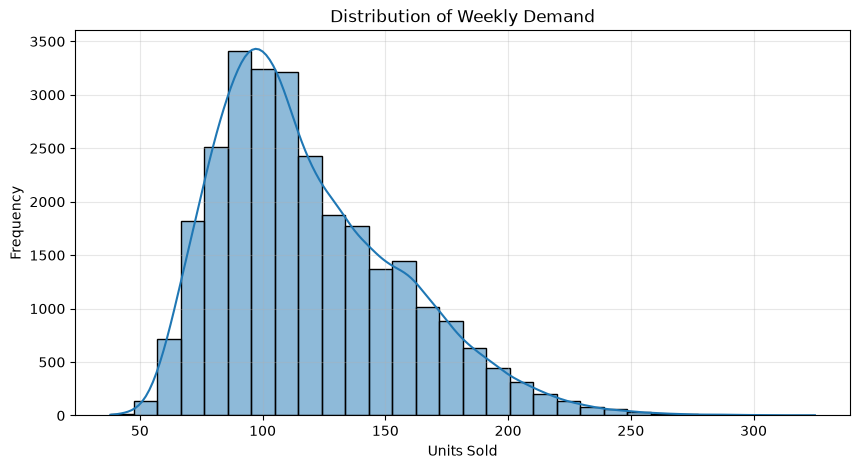

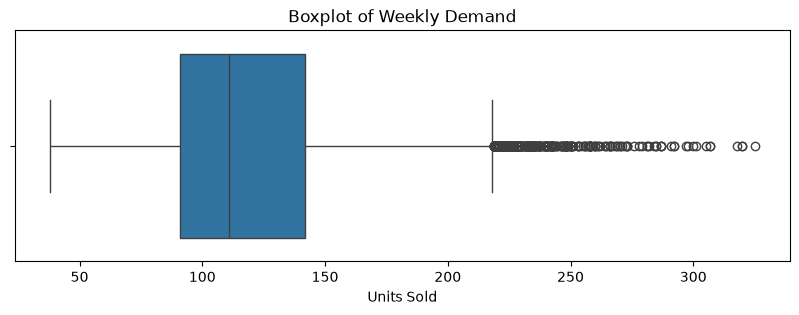


Demand distribution analysis completed!


In [19]:
# ============================================================
# STEP 3.2: DEMAND DISTRIBUTION ANALYSIS
# ============================================================

print("=" * 60)
print("DEMAND DISTRIBUTION ANALYSIS")
print("=" * 60)

# Target variable
target = df["units_sold"].dropna()

# Statistical information
print("\nDemand Statistics")

print("Mean:", round(target.mean(), 2))
print("Median:", round(target.median(), 2))
print("Minimum:", target.min())
print("Maximum:", target.max())
print("Standard Deviation:", round(target.std(), 2))

# Histogram with KDE
plt.figure(figsize=(10, 5))

sns.histplot(
    data=target,
    bins=30,
    kde=True
)

plt.title("Distribution of Weekly Demand")
plt.xlabel("Units Sold")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.show()

# Boxplot
plt.figure(figsize=(10, 3))

sns.boxplot(x=target)

plt.title("Boxplot of Weekly Demand")
plt.xlabel("Units Sold")

plt.show()

print("\nDemand distribution analysis completed!")

In [24]:
df = pd.read_excel(
    file_path,
    sheet_name="demand_training_data"
)

df.columns = df.columns.astype(str).str.strip()

print("Original values and their Python types:")

for value in df["week_start_date"].head(10):
    print(repr(value), type(value))

Original values and their Python types:
datetime.datetime(2024, 1, 1, 0, 0) <class 'datetime.datetime'>
datetime.datetime(2024, 1, 1, 0, 0) <class 'datetime.datetime'>
datetime.datetime(2024, 1, 1, 0, 0) <class 'datetime.datetime'>
datetime.datetime(2024, 1, 1, 0, 0) <class 'datetime.datetime'>
datetime.datetime(2024, 1, 1, 0, 0) <class 'datetime.datetime'>
datetime.datetime(2024, 1, 1, 0, 0) <class 'datetime.datetime'>
datetime.datetime(2024, 1, 1, 0, 0) <class 'datetime.datetime'>
datetime.datetime(2024, 1, 1, 0, 0) <class 'datetime.datetime'>
45292 <class 'int'>
45292 <class 'int'>


In [25]:
# STEP 3.3 - CELL 10C
# Convert mixed Excel dates correctly

from datetime import datetime, date
import numbers

def fix_excel_date(value):

    if pd.isna(value):
        return pd.NaT

    # If already a date, keep it
    if isinstance(value, (datetime, date, pd.Timestamp)):
        return pd.Timestamp(value)

    # If Excel serial number, convert it
    if isinstance(value, numbers.Number):
        return (
            pd.Timestamp("1899-12-30")
            + pd.to_timedelta(value, unit="D")
        )

    # Otherwise, try normal date conversion
    return pd.to_datetime(value, errors="coerce")


df["week_start_date"] = df["week_start_date"].apply(fix_excel_date)

# Verify conversion
print("DATE CONVERSION RESULTS")
print("Data type:", df["week_start_date"].dtype)
print("First date:", df["week_start_date"].min())
print("Last date:", df["week_start_date"].max())
print("Missing dates:", df["week_start_date"].isna().sum())

display(df[["week_start_date"]].head(10))

DATE CONVERSION RESULTS
Data type: datetime64[us]
First date: 2024-01-01 00:00:00
Last date: 2026-08-23 00:00:00
Missing dates: 0


,week_start_date
0,2024-01-01
1,2024-01-01
2,2024-01-01
3,2024-01-01
4,2024-01-01
5,2024-01-01
6,2024-01-01
7,2024-01-01
8,2024-01-01
9,2024-01-01


In [26]:
# STEP 3.3 - CELL 10D
# Aggregate total demand by week

weekly_demand = (
    df.groupby("week_start_date")["units_sold"]
    .sum()
    .reset_index()
    .sort_values("week_start_date")
)

print("WEEKLY DEMAND DATA")

display(weekly_demand.head(10))

print("\nTotal weekly records:", len(weekly_demand))

print(
    "\nTotal demand across all records:",
    weekly_demand["units_sold"].sum()
)

WEEKLY DEMAND DATA


,week_start_date,units_sold
0,2024-01-01,20547
1,2024-01-07,20415
2,2024-01-14,20446
3,2024-01-21,20349
4,2024-01-28,20322
5,2024-02-04,19812
6,2024-02-11,20601
7,2024-02-18,19883
8,2024-02-25,19418
9,2024-03-03,26220



Total weekly records: 139

Total demand across all records: 3301771


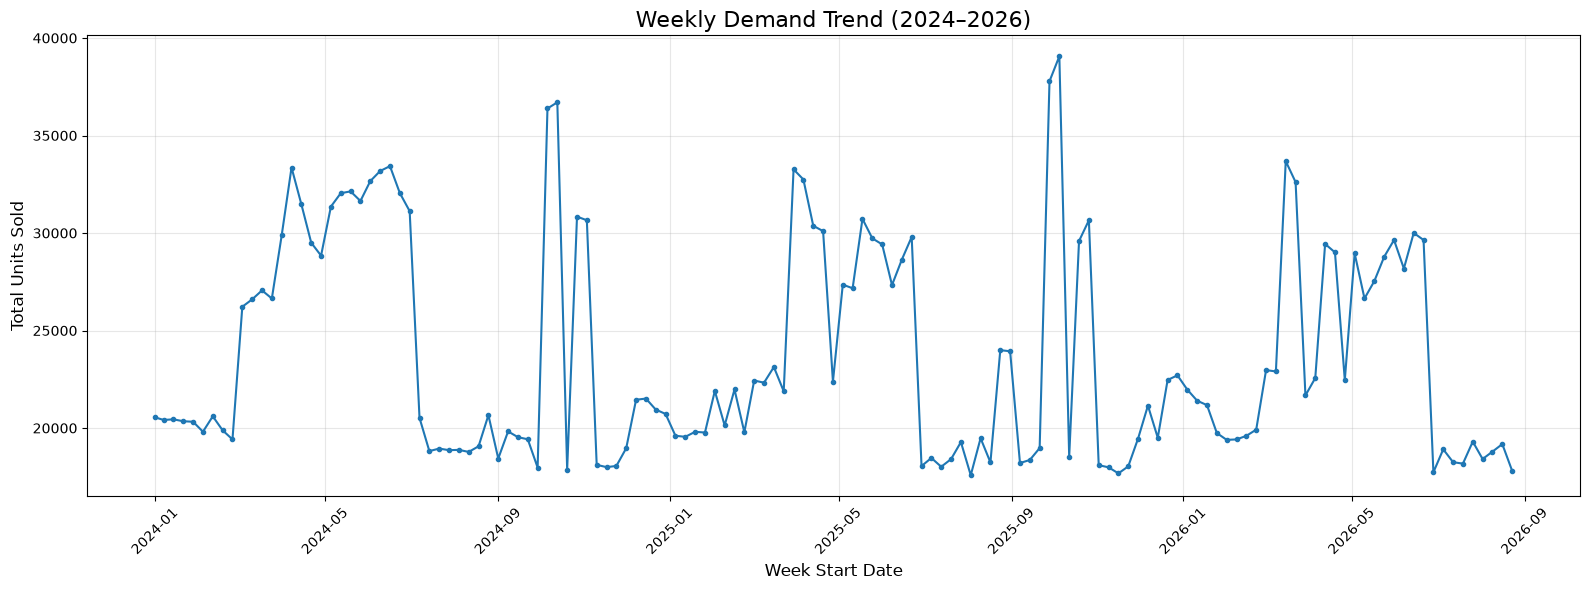

Weekly demand trend graph generated successfully!


In [27]:
# STEP 3.3 - CELL 10E
# Weekly Demand Trend Visualization

plt.figure(figsize=(16, 6))

plt.plot(
    weekly_demand["week_start_date"],
    weekly_demand["units_sold"],
    marker="o",
    markersize=3,
    linewidth=1.5
)

plt.title("Weekly Demand Trend (2024–2026)", fontsize=16)
plt.xlabel("Week Start Date", fontsize=12)
plt.ylabel("Total Units Sold", fontsize=12)

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Weekly demand trend graph generated successfully!")

In [28]:
# STEP 3.4 - CELL 11
# REGION-WISE DEMAND ANALYSIS

region_demand = (
    df.groupby("region_of_kolkata")["units_sold"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("REGION-WISE DEMAND SUMMARY")

display(region_demand)

print("\nTotal regions:", len(region_demand))
print("\nHighest demand region:")
display(region_demand.head(1))

print("\nLowest demand region:")
display(region_demand.tail(1))

REGION-WISE DEMAND SUMMARY


,region_of_kolkata,units_sold
0,Salt Lake,96661
1,Ballygunge,95821
2,Jadavpur,94968
3,Gariahat,94752
4,Park Street,94587
5,Esplanade,94387
6,Sector V,94210
7,New Town,93635
8,Rajarhat,86138
9,Lake Town,85903



Total regions: 40

Highest demand region:


,region_of_kolkata,units_sold
0,Salt Lake,96661



Lowest demand region:


,region_of_kolkata,units_sold
39,Behala,74910


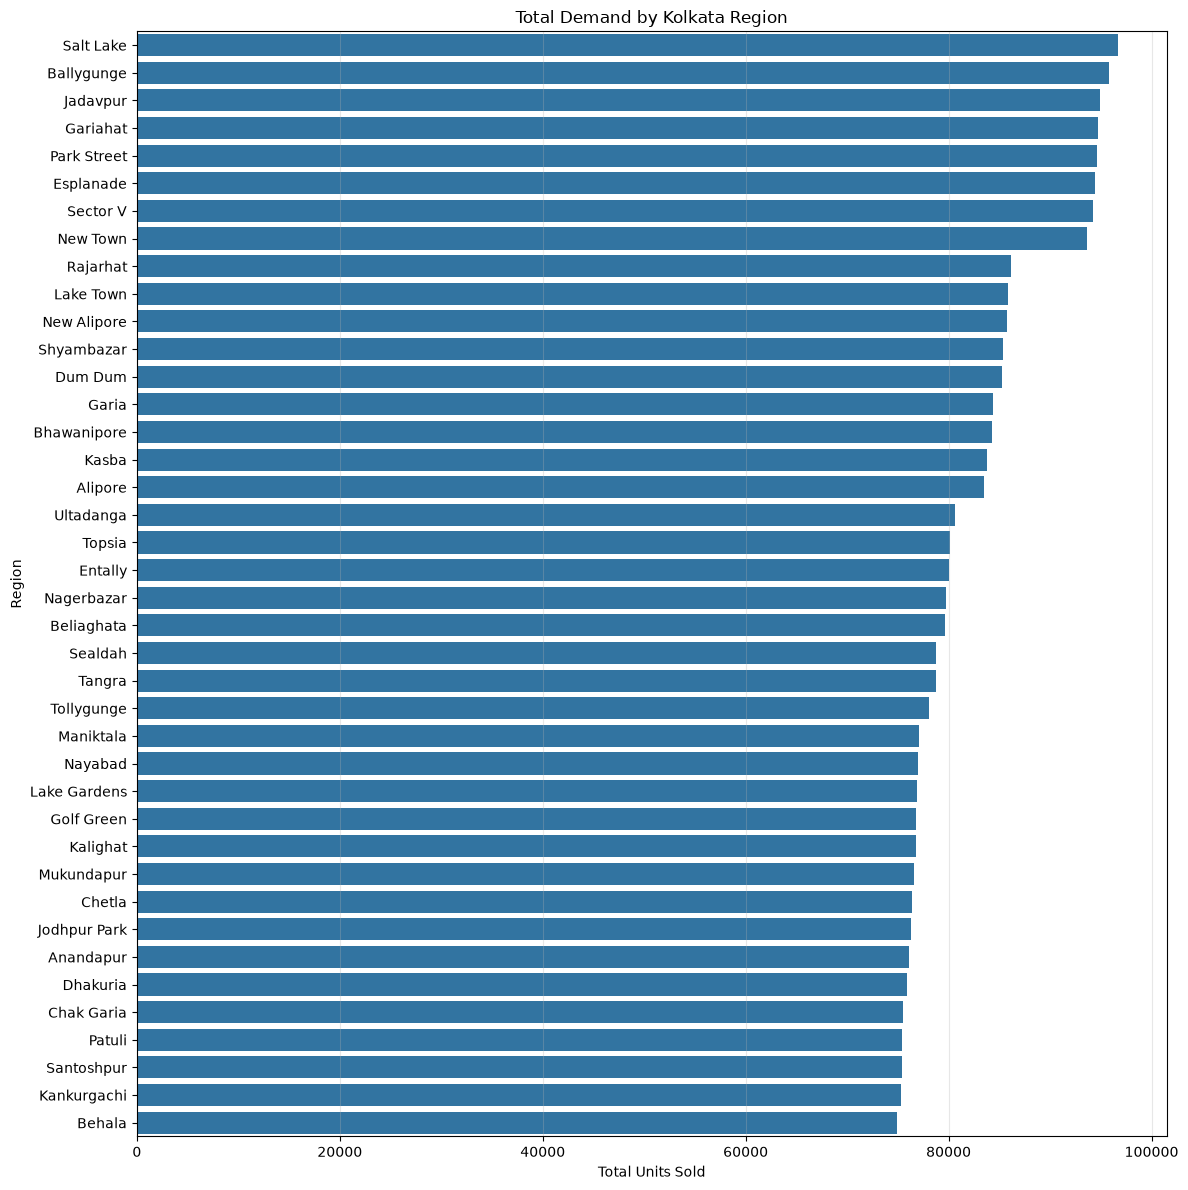

Region-wise demand graph generated successfully!


In [29]:
# STEP 3.4 - CELL 12
# VISUALIZE REGION-WISE DEMAND

plt.figure(figsize=(12, 12))

sns.barplot(
    data=region_demand,
    x="units_sold",
    y="region_of_kolkata"
)

plt.title("Total Demand by Kolkata Region")
plt.xlabel("Total Units Sold")
plt.ylabel("Region")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("Region-wise demand graph generated successfully!")

In [30]:
# STEP 3.5 - CELL 13
# PRODUCT-WISE DEMAND ANALYSIS

product_demand = (
    df.groupby(["product_id", "product_name"])["units_sold"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("PRODUCT-WISE DEMAND SUMMARY")

display(product_demand)

print("\nTotal unique products:",
      product_demand["product_id"].nunique())

print("\nTop 10 highest-demand products:")
display(product_demand.head(10))

print("\nTop 10 lowest-demand products:")
display(product_demand.tail(10))

PRODUCT-WISE DEMAND SUMMARY


,product_id,product_name,units_sold
0,BEV-004,Limca,393640
1,BEV-007,Frooti Mango,388735
2,BEV-006,Maaza Mango,275308
3,INS-001,Maggi 2-Minute Noodles,189402
4,INS-009,Quaker Oats,178594
5,BEV-001,Coca-Cola,148530
6,TEA-002,Tata Tea Premium,147922
7,INS-008,Kellogg's Corn Flakes,145612
8,TEA-009,Bru Instant Coffee,131304
9,TEA-001,Tata Tea Gold,131273



Total unique products: 53

Top 10 highest-demand products:


,product_id,product_name,units_sold
0,BEV-004,Limca,393640
1,BEV-007,Frooti Mango,388735
2,BEV-006,Maaza Mango,275308
3,INS-001,Maggi 2-Minute Noodles,189402
4,INS-009,Quaker Oats,178594
5,BEV-001,Coca-Cola,148530
6,TEA-002,Tata Tea Premium,147922
7,INS-008,Kellogg's Corn Flakes,145612
8,TEA-009,Bru Instant Coffee,131304
9,TEA-001,Tata Tea Gold,131273



Top 10 lowest-demand products:


,product_id,product_name,units_sold
43,INS-010,Ching's Schezwan Noodles,577
44,SNK-008,Bikaji Bikaneri Bhujia,551
45,VEG-003,Onion,541
46,SNK-006,Haldiram's Aloo Bhujia,458
47,ICE-001,Amul Vanilla Ice Cream,343
48,SNK-002,Lay's Magic Masala,329
49,INS-006,Tata Sampann Poha,288
50,BAK-004,Harvest Gold White Bread,267
51,VEG-010,Brinjal,254
52,FRT-007,Pomegranate,202


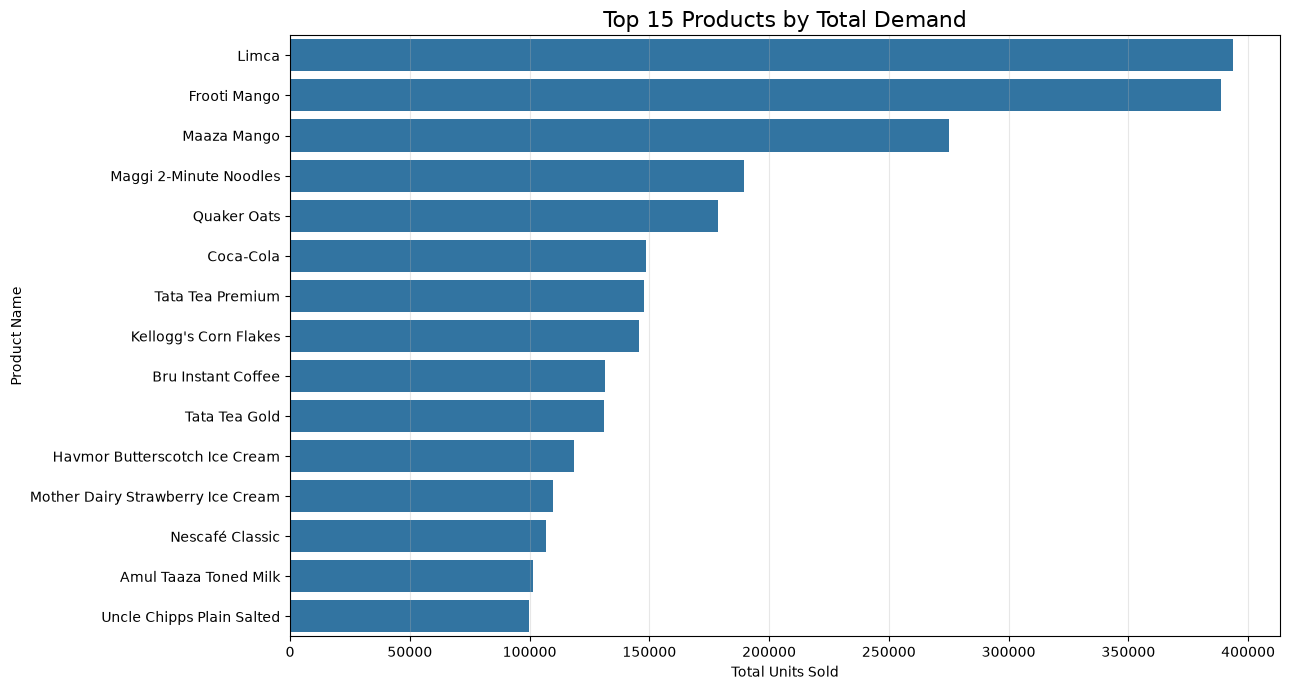

Product-wise demand visualization completed!


In [31]:
# STEP 3.5 - CELL 14
# VISUALIZE TOP 15 PRODUCTS BY DEMAND

top_15_products = product_demand.head(15).copy()

plt.figure(figsize=(13, 7))

sns.barplot(
    data=top_15_products,
    x="units_sold",
    y="product_name"
)

plt.title("Top 15 Products by Total Demand", fontsize=16)
plt.xlabel("Total Units Sold")
plt.ylabel("Product Name")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

print("Product-wise demand visualization completed!")

In [32]:
# STEP 3.6 - CELL 15
# CATEGORY-WISE DEMAND ANALYSIS

category_demand = (
    df.groupby("category_name")["units_sold"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("CATEGORY-WISE DEMAND SUMMARY")

display(category_demand)

print("\nTotal unique categories:",
      category_demand["category_name"].nunique())

print("\nHighest-demand category:")
display(category_demand.head(1))

print("\nLowest-demand category:")
display(category_demand.tail(1))

CATEGORY-WISE DEMAND SUMMARY


,category_name,units_sold
0,Soft Drinks & Beverages,1310439
1,Tea & Coffee,656187
2,Instant & Packaged Foods,569919
3,Ice Cream & Frozen Desserts,377301
4,Chips & Namkeen,215120
5,Dairy & Milk Products,112214
6,Fresh Vegetables,47105
7,Biscuits & Cookies,11245
8,Bread & Bakery,2039
9,Fresh Fruits,202



Total unique categories: 10

Highest-demand category:


,category_name,units_sold
0,Soft Drinks & Beverages,1310439



Lowest-demand category:


,category_name,units_sold
9,Fresh Fruits,202


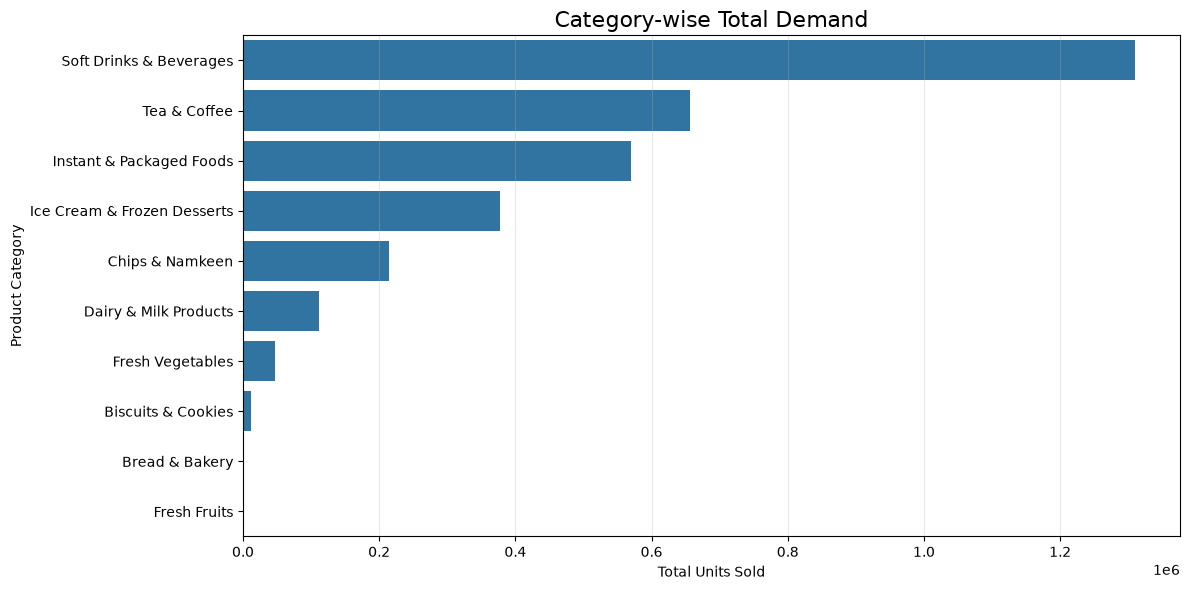

Category-wise demand visualization completed!


In [33]:
# STEP 3.6 - CELL 16
# VISUALIZE CATEGORY-WISE DEMAND

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_demand,
    x="units_sold",
    y="category_name"
)

plt.title("Category-wise Total Demand", fontsize=16)
plt.xlabel("Total Units Sold")
plt.ylabel("Product Category")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

print("Category-wise demand visualization completed!")

In [34]:
# STEP 3.7 - CELL 17
# SEASONAL DEMAND ANALYSIS

seasonal_demand = (
    df.groupby("season")["units_sold"]
    .agg(["sum", "mean", "count"])
    .reset_index()
    .sort_values("sum", ascending=False)
)

seasonal_demand.columns = [
    "season",
    "total_demand",
    "average_demand",
    "number_of_records"
]

print("SEASONAL DEMAND SUMMARY")

display(seasonal_demand)

print("\nTotal seasons:", seasonal_demand["season"].nunique())

print("\nHighest-demand season:")
display(seasonal_demand.head(1))

print("\nLowest-demand season:")
display(seasonal_demand.tail(1))

SEASONAL DEMAND SUMMARY


,season,total_demand,average_demand,number_of_records
3,Summer,784945,145.360185,5400
2,Spring,735514,136.206296,5400
4,Winter,696351,102.404559,6800
1,Monsoon,669259,98.420441,6800
0,Autumn,415702,122.265294,3400



Total seasons: 5

Highest-demand season:


,season,total_demand,average_demand,number_of_records
3,Summer,784945,145.360185,5400



Lowest-demand season:


,season,total_demand,average_demand,number_of_records
0,Autumn,415702,122.265294,3400


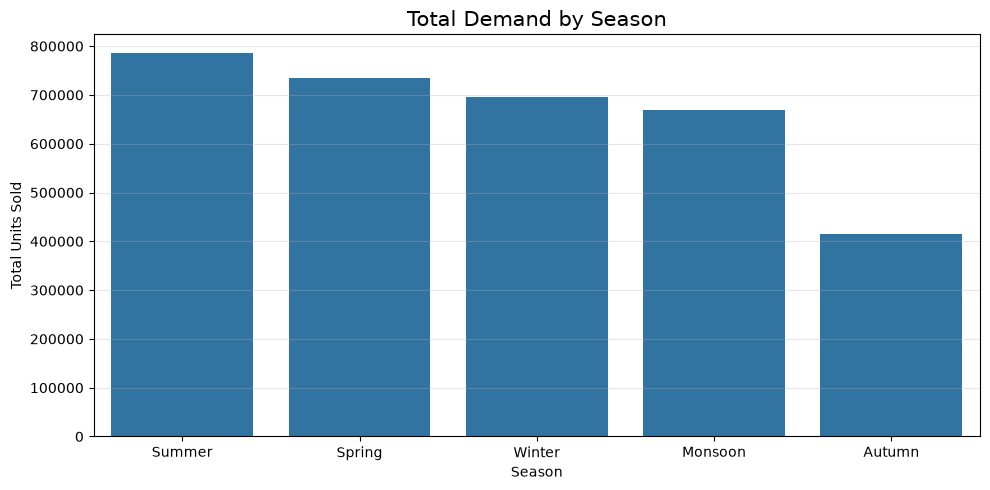

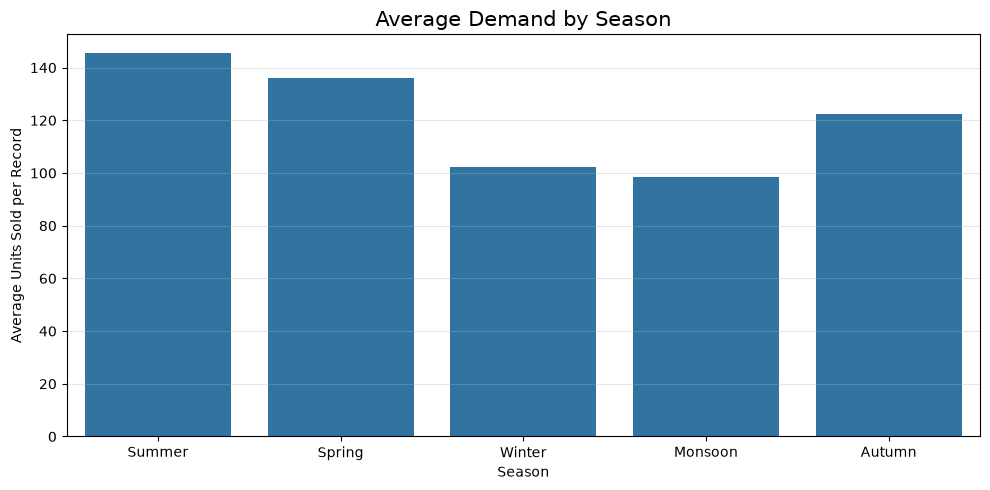

Seasonal demand visualizations completed!


In [35]:
# STEP 3.7 - CELL 18
# VISUALIZE SEASONAL DEMAND

plt.figure(figsize=(10, 5))

sns.barplot(
    data=seasonal_demand,
    x="season",
    y="total_demand"
)

plt.title("Total Demand by Season", fontsize=15)
plt.xlabel("Season")
plt.ylabel("Total Units Sold")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))

sns.barplot(
    data=seasonal_demand,
    x="season",
    y="average_demand"
)

plt.title("Average Demand by Season", fontsize=15)
plt.xlabel("Season")
plt.ylabel("Average Units Sold per Record")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Seasonal demand visualizations completed!")

In [36]:
# STEP 3.8 - CELL 19
# PROMOTION AND HOLIDAY IMPACT ANALYSIS

impact_analysis = (
    df.groupby(["promotion_flag", "holiday_flag"])["units_sold"]
    .agg(["count", "mean", "sum"])
    .reset_index()
)

impact_analysis.columns = [
    "promotion_flag",
    "holiday_flag",
    "number_of_records",
    "average_demand",
    "total_demand"
]

print("PROMOTION AND HOLIDAY IMPACT SUMMARY")

display(impact_analysis)

print("\nPROMOTION IMPACT:")
display(
    df.groupby("promotion_flag")["units_sold"]
    .agg(["count", "mean", "median", "sum"])
    .reset_index()
)

print("\nHOLIDAY IMPACT:")
display(
    df.groupby("holiday_flag")["units_sold"]
    .agg(["count", "mean", "median", "sum"])
    .reset_index()
)

PROMOTION AND HOLIDAY IMPACT SUMMARY


,promotion_flag,holiday_flag,number_of_records,average_demand,total_demand
0,0,0,17798,111.972469,1992886
1,0,1,4752,129.136364,613656
2,1,0,4002,126.128436,504766
3,1,1,1248,152.614583,190463



PROMOTION IMPACT:


,promotion_flag,count,mean,median,sum
0,0,22550,115.589446,108.0,2606542
1,1,5250,132.424571,124.0,695229



HOLIDAY IMPACT:


,holiday_flag,count,mean,median,sum
0,0,21800,114.571193,107.0,2497652
1,1,6000,134.019833,126.0,804119


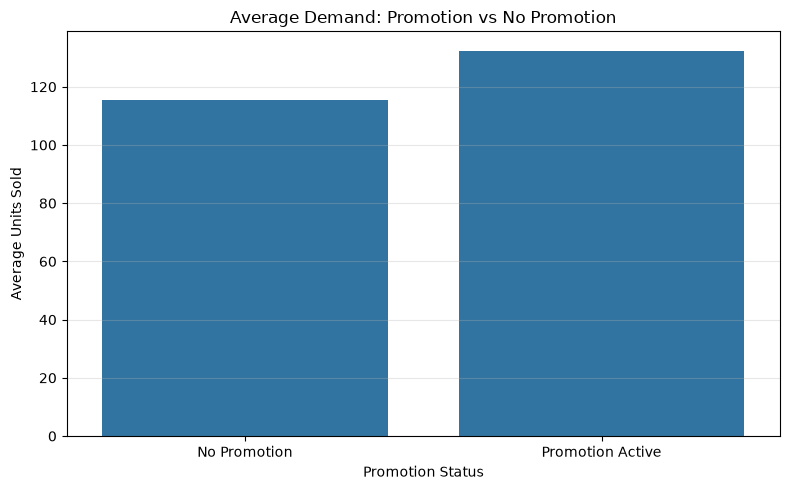

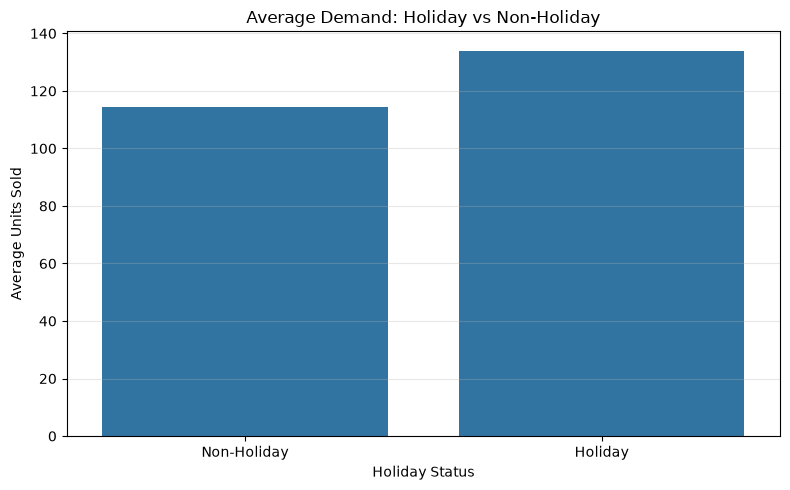

Promotion and holiday visualizations completed!


In [37]:
# STEP 3.8 - CELL 20
# PROMOTION AND HOLIDAY IMPACT VISUALIZATION

# 1. Promotion impact
promotion_demand = (
    df.groupby("promotion_flag")["units_sold"]
    .mean()
    .reset_index()
)

promotion_demand["promotion_status"] = promotion_demand[
    "promotion_flag"
].map({
    0: "No Promotion",
    1: "Promotion Active"
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=promotion_demand,
    x="promotion_status",
    y="units_sold"
)

plt.title("Average Demand: Promotion vs No Promotion")
plt.xlabel("Promotion Status")
plt.ylabel("Average Units Sold")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# 2. Holiday impact
holiday_demand = (
    df.groupby("holiday_flag")["units_sold"]
    .mean()
    .reset_index()
)

holiday_demand["holiday_status"] = holiday_demand[
    "holiday_flag"
].map({
    0: "Non-Holiday",
    1: "Holiday"
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=holiday_demand,
    x="holiday_status",
    y="units_sold"
)

plt.title("Average Demand: Holiday vs Non-Holiday")
plt.xlabel("Holiday Status")
plt.ylabel("Average Units Sold")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Promotion and holiday visualizations completed!")

In [38]:
# STEP 3.9 - CELL 21
# WEATHER IMPACT ANALYSIS

weather_analysis = (
    df.groupby("weather_condition")["units_sold"]
    .agg(["count", "mean", "median", "sum"])
    .reset_index()
    .sort_values("mean", ascending=False)
)

print("DEMAND BY WEATHER CONDITION")

display(weather_analysis)


# Numerical weather feature analysis
weather_features = [
    "temperature_c",
    "rainfall_mm",
    "humidity_pct"
]

weather_summary = df[weather_features + ["units_sold"]].describe().T

print("\nWEATHER AND DEMAND STATISTICAL SUMMARY")

display(weather_summary)


# Correlation between weather and demand
weather_correlation = (
    df[weather_features + ["units_sold"]]
    .corr(numeric_only=True)["units_sold"]
    .drop("units_sold")
    .sort_values(ascending=False)
)

print("\nWEATHER FEATURE CORRELATION WITH DEMAND")

display(weather_correlation)

DEMAND BY WEATHER CONDITION


,weather_condition,count,mean,median,sum
0,Clear/Partly Cloudy,20400,126.796373,121.0,2586646
2,Heavy Rain,2400,100.258333,98.0,240620
1,Cloudy,1600,96.258750,96.0,154014
3,Rain,3400,94.262059,91.0,320491



WEATHER AND DEMAND STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
temperature_c,27800.0,28.287770,5.014321,15.3,26.0,29.7,31.8,37.0
rainfall_mm,27800.0,20.308633,26.023519,0.0,6.2,11.2,19.9,132.5
humidity_pct,27800.0,70.267626,10.988309,48.0,62.9,68.9,78.6,93.7
units_sold,27800.0,118.768741,37.610565,38.0,91.0,111.0,142.0,325.0



WEATHER FEATURE CORRELATION WITH DEMAND


temperature_c    0.297477
humidity_pct    -0.175131
rainfall_mm     -0.208703
Name: units_sold, dtype: float64

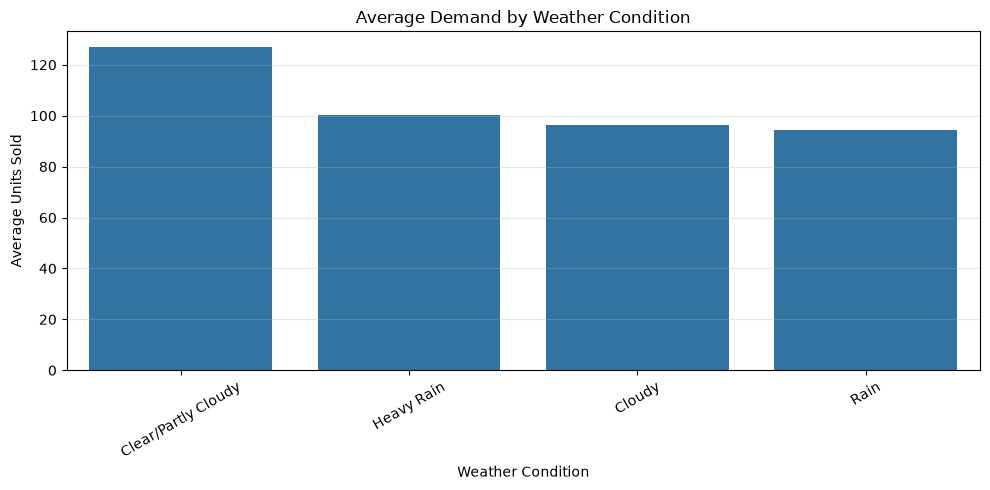

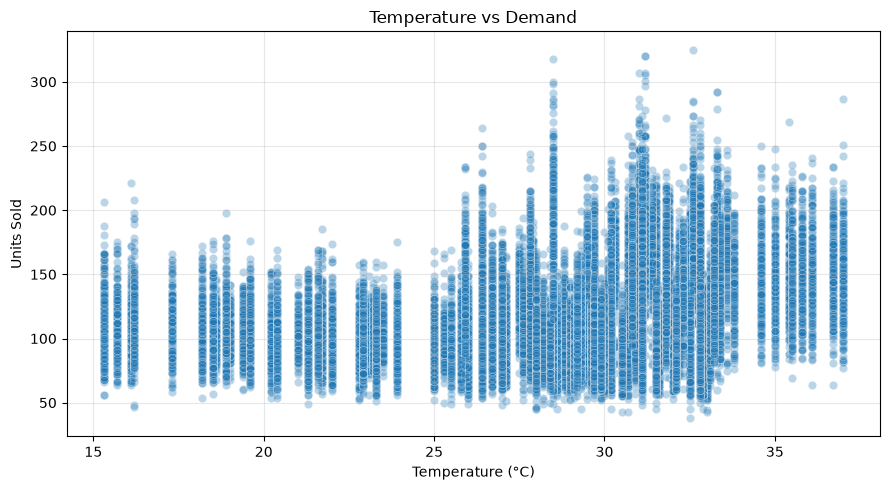

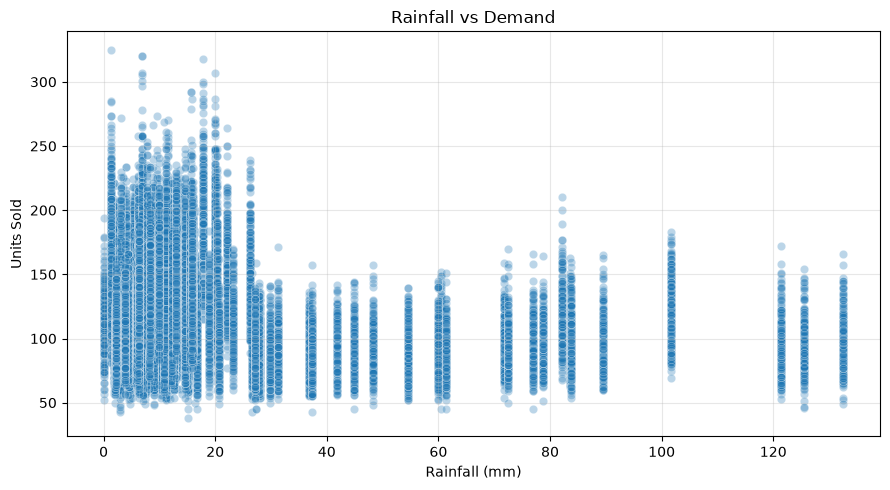

Weather impact visualizations completed!


In [39]:
# STEP 3.9 - CELL 22
# WEATHER IMPACT VISUALIZATION

# 1. Demand by weather condition
plt.figure(figsize=(10, 5))

sns.barplot(
    data=weather_analysis,
    x="weather_condition",
    y="mean"
)

plt.title("Average Demand by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# 2. Temperature vs demand
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="temperature_c",
    y="units_sold",
    alpha=0.3
)

plt.title("Temperature vs Demand")
plt.xlabel("Temperature (°C)")
plt.ylabel("Units Sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 3. Rainfall vs demand
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="rainfall_mm",
    y="units_sold",
    alpha=0.3
)

plt.title("Rainfall vs Demand")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Units Sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Weather impact visualizations completed!")

In [40]:
# STEP 3.10 - CELL 23
# FEATURE CORRELATION ANALYSIS

# Select numerical columns
numeric_df = df.select_dtypes(include=["number"])

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

print("CORRELATION WITH DEMAND (units_sold)")

demand_correlation = (
    correlation_matrix["units_sold"]
    .sort_values(ascending=False)
)

display(demand_correlation.to_frame("correlation"))

print("\nComplete correlation matrix:")
display(correlation_matrix.round(2))

print("\nCorrelation analysis completed!")

CORRELATION WITH DEMAND (units_sold)


,correlation
units_sold,1.000000
weekday_units_sold,0.986268
weekend_units_sold,0.934261
next_week_demand_target_units,0.907819
temperature_c,0.297477
holiday_flag,0.212739
discount_pct,0.188021
promotion_flag,0.175195
recorded_at,0.119292
selling_unit_source_row,-0.004121



Complete correlation matrix:


,year,week_number,demand_rank,weekday_units_sold,weekend_units_sold,units_sold,avg_selling_price_rs,promotion_flag,discount_pct,holiday_flag,temperature_c,rainfall_mm,humidity_pct,stockout_flag,next_week_demand_target_units,recorded_at,assortment_size,selling_unit_source_row
year,1.00,0.94,-0.00,-0.12,0.10,-0.05,0.01,-0.02,0.00,-0.04,0.10,0.18,-0.01,0.01,-0.06,-0.64,NaN,-0.00
week_number,0.94,1.00,-0.00,-0.15,0.08,-0.08,-0.02,-0.01,0.01,0.01,0.16,0.27,0.09,0.01,-0.07,-0.75,NaN,-0.00
demand_rank,-0.00,-0.00,1.00,-0.25,-0.20,-0.24,-0.00,-0.03,-0.02,-0.00,0.00,-0.00,0.00,0.02,-0.21,0.00,NaN,0.00
weekday_units_sold,-0.12,-0.15,-0.25,1.00,0.86,0.99,-0.18,0.18,0.19,0.20,0.23,-0.21,-0.18,-0.10,0.89,0.20,NaN,-0.00
weekend_units_sold,0.10,0.08,-0.20,0.86,1.00,0.93,-0.24,0.15,0.17,0.21,0.40,-0.18,-0.15,-0.08,0.86,-0.07,NaN,-0.00
units_sold,-0.05,-0.08,-0.24,0.99,0.93,1.00,-0.21,0.18,0.19,0.21,0.30,-0.21,-0.18,-0.10,0.91,0.12,NaN,-0.00
avg_selling_price_rs,0.01,-0.02,-0.00,-0.18,-0.24,-0.21,1.00,-0.01,-0.01,-0.05,-0.32,-0.10,-0.18,-0.00,-0.20,-0.01,NaN,-0.00
promotion_flag,-0.02,-0.01,-0.03,0.18,0.15,0.18,-0.01,1.00,0.90,0.03,0.01,-0.01,-0.01,0.01,0.16,0.00,NaN,-0.00
discount_pct,0.00,0.01,-0.02,0.19,0.17,0.19,-0.01,0.90,1.00,0.03,0.02,-0.00,-0.00,0.00,0.17,-0.03,NaN,-0.00
holiday_flag,-0.04,0.01,-0.00,0.20,0.21,0.21,-0.05,0.03,0.03,1.00,0.07,0.02,0.10,-0.01,0.27,-0.10,NaN,0.00



Correlation analysis completed!


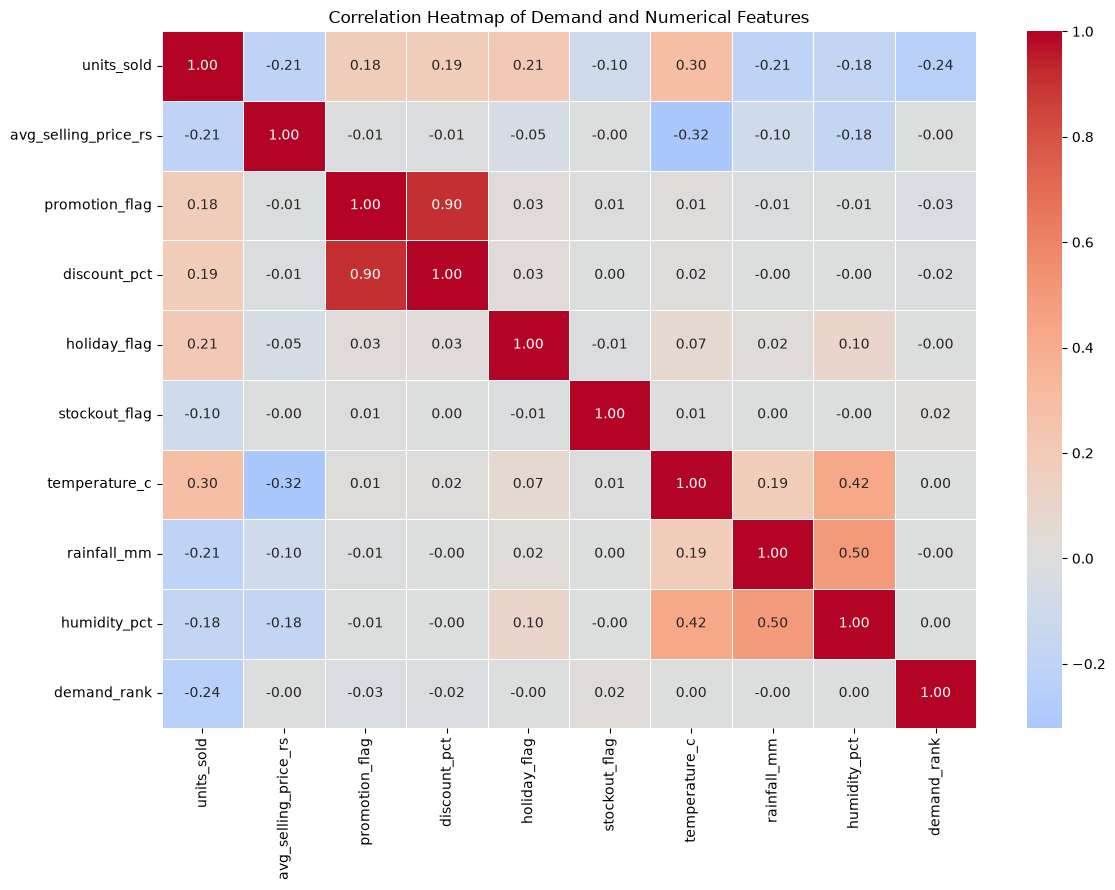

Correlation heatmap generated successfully!


In [41]:
# STEP 3.10 - CELL 24
# CORRELATION HEATMAP FOR TFT FEATURE ANALYSIS

correlation_columns = [
    "units_sold",
    "avg_selling_price_rs",
    "promotion_flag",
    "discount_pct",
    "holiday_flag",
    "stockout_flag",
    "temperature_c",
    "rainfall_mm",
    "humidity_pct",
    "demand_rank"
]

# Keep only columns available in the dataset
correlation_columns = [
    col for col in correlation_columns if col in df.columns
]

correlation_data = df[correlation_columns].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap of Demand and Numerical Features")
plt.tight_layout()
plt.show()

print("Correlation heatmap generated successfully!")

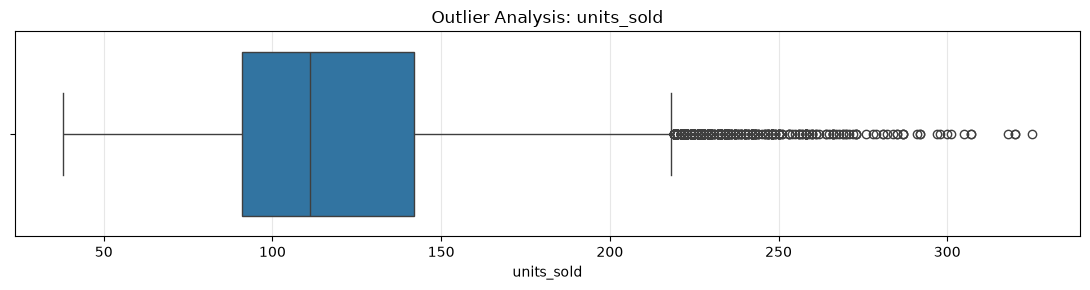

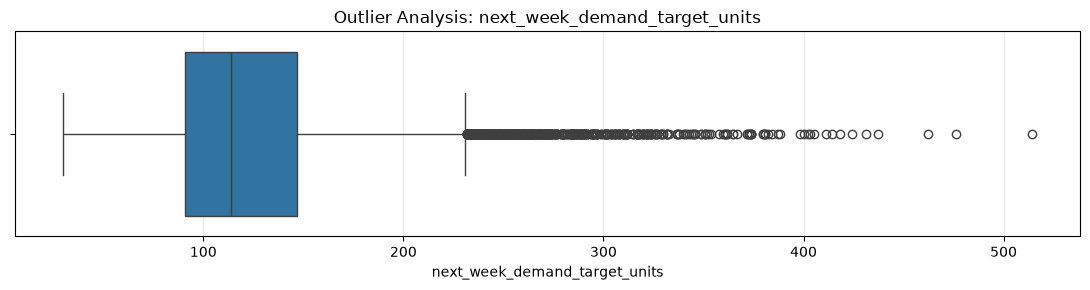

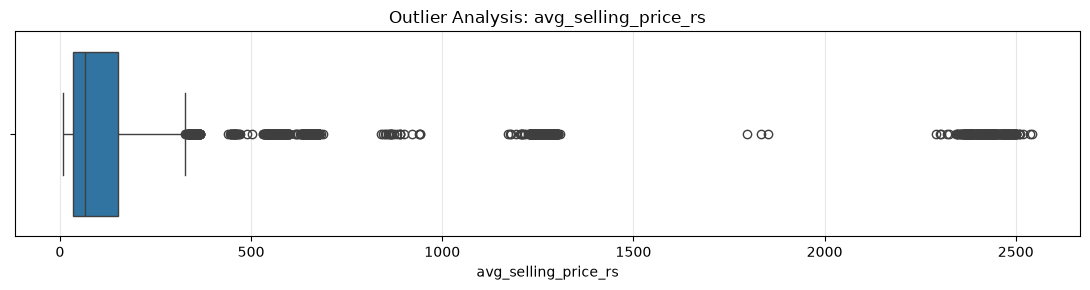

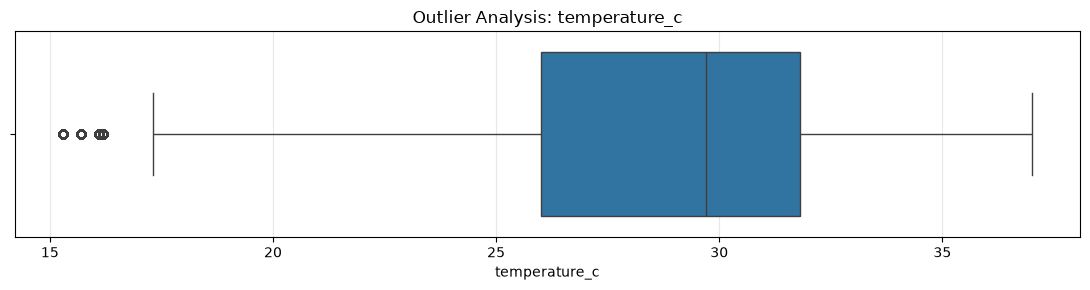

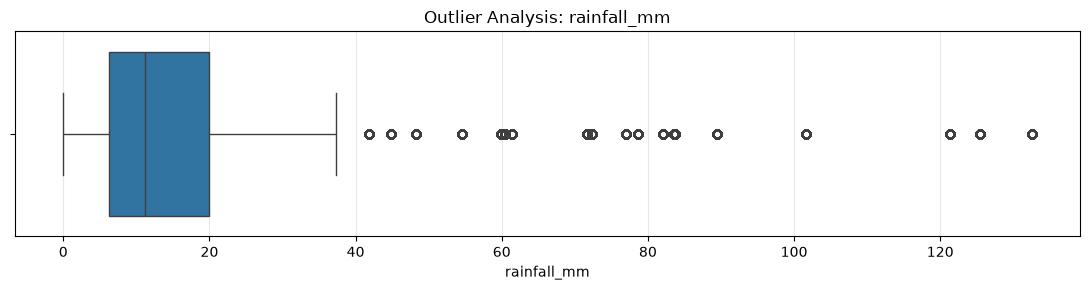

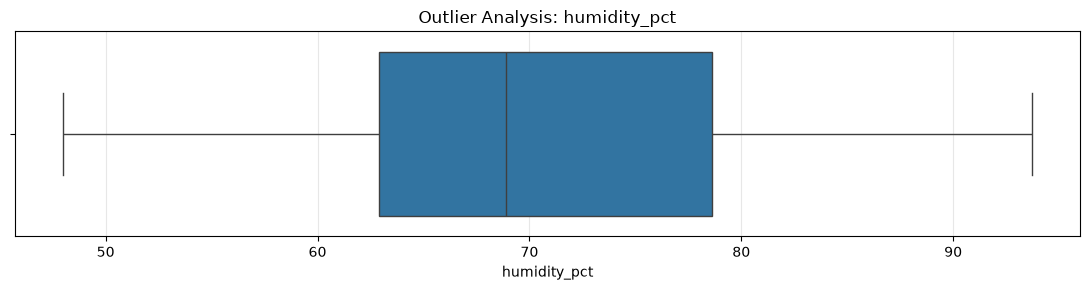

Outlier visualization completed!


In [42]:
# STEP 3.11 - CELL 25
# OUTLIER VISUALIZATION USING BOXPLOTS

outlier_columns = [
    "units_sold",
    "next_week_demand_target_units",
    "avg_selling_price_rs",
    "temperature_c",
    "rainfall_mm",
    "humidity_pct"
]

for column in outlier_columns:

    plt.figure(figsize=(11, 3))

    sns.boxplot(x=df[column])

    plt.title(f"Outlier Analysis: {column}")
    plt.xlabel(column)
    plt.grid(axis="x", alpha=0.3)

    plt.tight_layout()
    plt.show()

print("Outlier visualization completed!")

In [43]:
# STEP 3.11 - CELL 26
# NUMERICAL OUTLIER DETECTION USING IQR

outlier_columns = [
    "units_sold",
    "next_week_demand_target_units",
    "avg_selling_price_rs",
    "temperature_c",
    "rainfall_mm",
    "humidity_pct"
]

outlier_results = []

for column in outlier_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    outlier_results.append({
        "feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "lower_limit": lower_limit,
        "upper_limit": upper_limit,
        "outlier_count": len(outliers),
        "outlier_percentage": (
            len(outliers) / len(df)
        ) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

print("IQR OUTLIER DETECTION SUMMARY")

display(outlier_summary.round(2))

print("Outlier detection completed!")

IQR OUTLIER DETECTION SUMMARY


,feature,Q1,Q3,IQR,lower_limit,upper_limit,outlier_count,outlier_percentage
0,units_sold,91.0,142.00,51.00,14.50,218.50,368,1.32
1,next_week_demand_target_units,91.0,147.00,56.00,7.00,231.00,698,2.51
2,avg_selling_price_rs,33.7,151.52,117.82,-143.03,328.25,2121,7.63
3,temperature_c,26.0,31.80,5.80,17.30,40.50,1000,3.60
4,rainfall_mm,6.2,19.90,13.70,-14.35,40.45,3800,13.67
5,humidity_pct,62.9,78.60,15.70,39.35,102.15,0,0.00


Outlier detection completed!


In [44]:
# STEP 3.12 - CELL 27
# FINAL EDA SUMMARY

print("=" * 60)
print("FINAL EXPLORATORY DATA ANALYSIS SUMMARY")
print("=" * 60)

print("\n1. DATASET INFORMATION")
print("Total records:", len(df))
print("Total columns:", len(df.columns))
print("Unique regions:", df["region_of_kolkata"].nunique())
print("Unique observed products:", df["product_id"].nunique())
print("Unique categories:", df["category_name"].nunique())

print("\n2. DEMAND STATISTICS")
print("Average demand:", round(df["units_sold"].mean(), 2))
print("Median demand:", df["units_sold"].median())
print("Minimum demand:", df["units_sold"].min())
print("Maximum demand:", df["units_sold"].max())
print("Demand standard deviation:", round(df["units_sold"].std(), 2))

print("\n3. TIME INFORMATION")
print("First week:", df["week_start_date"].min())
print("Last week:", df["week_start_date"].max())
print("Unique weekly periods:", df["week_start_date"].nunique())

print("\n4. HIGHEST-DEMAND REGION")
print(region_demand.iloc[0]["region_of_kolkata"])
print("Total demand:", region_demand.iloc[0]["units_sold"])

print("\n5. HIGHEST-DEMAND PRODUCT")
print(product_demand.iloc[0]["product_name"])
print("Total demand:", product_demand.iloc[0]["units_sold"])

print("\n6. HIGHEST-DEMAND CATEGORY")
print(category_demand.iloc[0]["category_name"])
print("Total demand:", category_demand.iloc[0]["units_sold"])

print("\n7. MISSING VALUES")
print("Total missing values:", df.isnull().sum().sum())

print("\n" + "=" * 60)
print("EDA SUMMARY COMPLETED")
print("=" * 60)

FINAL EXPLORATORY DATA ANALYSIS SUMMARY

1. DATASET INFORMATION
Total records: 27800
Total columns: 44
Unique regions: 40
Unique observed products: 53
Unique categories: 10

2. DEMAND STATISTICS
Average demand: 118.77
Median demand: 111.0
Minimum demand: 38
Maximum demand: 325
Demand standard deviation: 37.61

3. TIME INFORMATION
First week: 2024-01-01 00:00:00
Last week: 2026-08-23 00:00:00
Unique weekly periods: 139

4. HIGHEST-DEMAND REGION
Salt Lake
Total demand: 96661

5. HIGHEST-DEMAND PRODUCT
Limca
Total demand: 393640

6. HIGHEST-DEMAND CATEGORY
Soft Drinks & Beverages
Total demand: 1310439

7. MISSING VALUES
Total missing values: 21800

EDA SUMMARY COMPLETED


In [45]:
# STEP 4.1 - CELL 28
# CREATE A SAFE WORKING COPY

# Keep original dataset unchanged
df_clean = df.copy()

# Check dataset dimensions
print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

# Check whether both datasets have identical values
print(
    "Both datasets initially identical:",
    df.equals(df_clean)
)

print("\nWorking copy created successfully!")

Original dataset shape: (27800, 44)
Working dataset shape: (27800, 44)
Both datasets initially identical: True

Working copy created successfully!


In [46]:
# STEP 4.2 - CELL 29
# INSPECT DATA TYPES

print("DATASET INFORMATION")

df_clean.info()

print("\nCOLUMN DATA TYPES")

display(
    pd.DataFrame({
        "column_name": df_clean.columns,
        "data_type": df_clean.dtypes.astype(str).values,
        "missing_values": df_clean.isnull().sum().values,
        "unique_values": df_clean.nunique().values
    })
)

print("\nData type inspection completed!")

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 27800 entries, 0 to 27799
Data columns (total 44 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   demand_id                      27800 non-null  str           
 1   week_start_date                27800 non-null  datetime64[us]
 2   week_end_date                  27800 non-null  object        
 3   year                           27800 non-null  int64         
 4   week_number                    27800 non-null  int64         
 5   location_id                    27800 non-null  str           
 6   region_of_kolkata              27800 non-null  str           
 7   demand_rank                    27800 non-null  int64         
 8   product_id                     27800 non-null  str           
 9   product_name                   27800 non-null  str           
 10  category_name                  27800 non-null  str           
 11  brand 

,column_name,data_type,missing_values,unique_values
0,demand_id,str,0,27800
1,week_start_date,datetime64[us],0,139
2,week_end_date,object,0,144
3,year,int64,0,3
4,week_number,int64,0,139
5,location_id,str,0,40
6,region_of_kolkata,str,0,40
7,demand_rank,int64,0,5
8,product_id,str,0,53
9,product_name,str,0,53



Data type inspection completed!


In [47]:
# STEP 4.2 - CELL 30
# STANDARDIZE DATE COLUMNS

from datetime import datetime, date
import numbers

def fix_excel_date(value):

    if pd.isna(value):
        return pd.NaT

    if isinstance(value, (datetime, date, pd.Timestamp)):
        return pd.Timestamp(value)

    if isinstance(value, numbers.Number):
        return (
            pd.Timestamp("1899-12-30")
            + pd.to_timedelta(value, unit="D")
        )

    return pd.to_datetime(value, errors="coerce")


date_columns = [
    "week_start_date",
    "week_end_date",
    "forecast_target_start",
    "forecast_target_end"
]

for column in date_columns:
    df_clean[column] = df_clean[column].apply(fix_excel_date)

print("DATE COLUMN VALIDATION")

for column in date_columns:
    print(f"\n{column}")
    print("Data type:", df_clean[column].dtype)
    print("Missing dates:", df_clean[column].isna().sum())
    print("Minimum date:", df_clean[column].min())
    print("Maximum date:", df_clean[column].max())

print("\nDate standardization completed!")

DATE COLUMN VALIDATION

week_start_date
Data type: datetime64[us]
Missing dates: 0
Minimum date: 2024-01-01 00:00:00
Maximum date: 2026-08-23 00:00:00

week_end_date
Data type: datetime64[us]
Missing dates: 0
Minimum date: 2024-01-07 00:00:00
Maximum date: 2026-08-29 00:00:00

forecast_target_start
Data type: datetime64[us]
Missing dates: 0
Minimum date: 2024-01-08 00:00:00
Maximum date: 2026-08-30 00:00:00

forecast_target_end
Data type: datetime64[us]
Missing dates: 0
Minimum date: 2024-01-14 00:00:00
Maximum date: 2026-09-05 00:00:00

Date standardization completed!


In [48]:
# STEP 4.3 - CELL 31
# MISSING VALUE ANALYSIS

missing_summary = pd.DataFrame({
    "missing_count": df_clean.isnull().sum(),
    "missing_percentage": (
        df_clean.isnull().sum() / len(df_clean)
    ) * 100
})

missing_summary = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_percentage", ascending=False)
)

print("MISSING VALUE SUMMARY")

if missing_summary.empty:
    print("No missing values found!")
else:
    display(missing_summary.round(2))

print("\nTotal missing cells:", df_clean.isnull().sum().sum())
print("Total columns with missing values:", len(missing_summary))

MISSING VALUE SUMMARY


,missing_count,missing_percentage
festival_event,21800,78.42



Total missing cells: 21800
Total columns with missing values: 1


In [49]:
# STEP 4.3 - CELL 32
# INSPECT FESTIVAL EVENT VALUES

print("Festival event value counts:")

display(
    df_clean["festival_event"]
    .value_counts(dropna=False)
    .to_frame(name="count")
)

print("\nUnique festival events (excluding missing values):")

print(df_clean["festival_event"].dropna().unique())

Festival event value counts:


,count
festival_event,
NaN,21800
Saraswati Puja,600
Eid-Ul-Fitr,600
Poila Boishakh / Bengali New Year,600
Rath Yatra,600
Janmashtami,400
Ganesh Chaturthi,400
Durga Puja | Durga Puja / Dashami,400
Lakshmi Puja,400



Unique festival events (excluding missing values):
<StringArray>
[                     'Saraswati Puja',                         'Eid-Ul-Fitr',   'Poila Boishakh / Bengali New Year',
                          'Rath Yatra',                         'Janmashtami',                    'Ganesh Chaturthi',
   'Durga Puja | Durga Puja / Dashami',                        'Lakshmi Puja',                  'Kali Puja / Diwali',
                          'Chhat Puja',                           'Christmas',                     'Doljatra / Holi',
                    'Vishwakarma Puja',                          'Durga Puja', 'Kali Puja / Diwali | Bhratridwitiya']
Length: 15, dtype: str


In [50]:
# STEP 4.3 - CELL 33
# COMPARE FESTIVAL EVENTS WITH HOLIDAY FLAG

festival_holiday_check = pd.crosstab(
    df_clean["holiday_flag"],
    df_clean["festival_event"].isna(),
    margins=True
)

festival_holiday_check.columns = [
    "Festival Recorded",
    "Festival Missing",
    "Total"
]

festival_holiday_check.index = [
    "Non-Holiday",
    "Holiday",
    "Total"
]

print("Festival event vs Holiday flag:")
display(festival_holiday_check)

print("\nHoliday flag distribution:")
display(df_clean["holiday_flag"].value_counts(dropna=False))

Festival event vs Holiday flag:


,Festival Recorded,Festival Missing,Total
Non-Holiday,0,21800,21800
Holiday,6000,0,6000
Total,6000,21800,27800



Holiday flag distribution:


holiday_flag
0    21800
1     6000
Name: count, dtype: int64

In [51]:
# STEP 4.3 - CELL 34
# HANDLE MISSING FESTIVAL EVENTS

# Fill missing festival values
df_clean["festival_event"] = (
    df_clean["festival_event"].fillna("No Festival")
)

# Verify the result
print("Missing values after treatment:")
print(df_clean["festival_event"].isnull().sum())

print("\nFestival event distribution after treatment:")
display(
    df_clean["festival_event"]
    .value_counts()
    .to_frame(name="count")
)

print("\nTotal dataset shape:", df_clean.shape)

Missing values after treatment:
0

Festival event distribution after treatment:


,count
festival_event,
No Festival,21800
Saraswati Puja,600
Eid-Ul-Fitr,600
Poila Boishakh / Bengali New Year,600
Rath Yatra,600
Janmashtami,400
Ganesh Chaturthi,400
Durga Puja | Durga Puja / Dashami,400
Lakshmi Puja,400



Total dataset shape: (27800, 44)


In [52]:
# STEP 4.4 - CELL 35
# DUPLICATE RECORD CHECKING

# 1. Check complete duplicate rows
exact_duplicates = df_clean.duplicated().sum()

# 2. Check duplicate demand IDs
duplicate_demand_ids = df_clean["demand_id"].duplicated().sum()

# 3. Check duplicate region-product-week keys
duplicate_series_keys = (
    df_clean["region_product_week_key"].duplicated().sum()
)

print("DUPLICATE RECORD ANALYSIS")
print("-" * 40)

print("Exact duplicate rows:", exact_duplicates)
print("Duplicate demand IDs:", duplicate_demand_ids)
print("Duplicate region-product-week keys:", duplicate_series_keys)

print("\nDataset shape:", df_clean.shape)

DUPLICATE RECORD ANALYSIS
----------------------------------------
Exact duplicate rows: 0
Duplicate demand IDs: 0
Duplicate region-product-week keys: 0

Dataset shape: (27800, 44)


In [53]:
# STEP 4.5 - CELL 36
# DATE VALIDATION

print("DATE VALIDATION REPORT")
print("-" * 45)

# 1. Check missing dates
for column in [
    "week_start_date",
    "week_end_date",
    "forecast_target_start",
    "forecast_target_end"
]:
    print(f"{column} missing:", df_clean[column].isna().sum())

# 2. Check date range
print("\nFirst week:", df_clean["week_start_date"].min())
print("Last week:", df_clean["week_start_date"].max())

# 3. Check unique weekly periods
unique_weeks = (
    df_clean["week_start_date"]
    .drop_duplicates()
    .sort_values()
)

print("\nTotal unique weeks:", len(unique_weeks))

# 4. Check weekly gaps
week_gaps = unique_weeks.diff().dropna().value_counts().sort_index()

print("\nDifference between consecutive weeks:")
display(week_gaps.to_frame(name="count"))

# 5. Check duration of weekly periods
df_clean["period_duration_days"] = (
    df_clean["week_end_date"] - df_clean["week_start_date"]
).dt.days + 1

print("\nWeekly period duration:")
display(
    df_clean["period_duration_days"]
    .value_counts()
    .sort_index()
    .to_frame(name="count")
)

DATE VALIDATION REPORT
---------------------------------------------
week_start_date missing: 0
week_end_date missing: 0
forecast_target_start missing: 0
forecast_target_end missing: 0

First week: 2024-01-01 00:00:00
Last week: 2026-08-23 00:00:00

Total unique weeks: 139

Difference between consecutive weeks:


,count
week_start_date,
6 days,1
7 days,137



Weekly period duration:


,count
period_duration_days,
7,27800


In [54]:
# STEP 4.5 - CELL 37
# INVESTIGATE WEEKLY DATE ALIGNMENT

weekly_dates = (
    df_clean[
        ["week_start_date", "week_end_date",
         "forecast_target_start", "forecast_target_end"]
    ]
    .drop_duplicates()
    .sort_values("week_start_date")
    .reset_index(drop=True)
)

# Compare each week's dates with the next week
weekly_dates["next_week_start"] = (
    weekly_dates["week_start_date"].shift(-1)
)

weekly_dates["start_date_gap"] = (
    weekly_dates["next_week_start"]
    - weekly_dates["week_start_date"]
).dt.days

weekly_dates["days_between_periods"] = (
    weekly_dates["next_week_start"]
    - weekly_dates["week_end_date"]
).dt.days

# Show irregular start-date intervals
print("IRREGULAR WEEKLY DATE INTERVALS")

display(
    weekly_dates[
        weekly_dates["start_date_gap"] != 7
    ]
)

# Check forecast target alignment
weekly_dates["expected_target_start"] = (
    weekly_dates["week_end_date"]
    + pd.Timedelta(days=1)
)

print("\nFORECAST TARGET ALIGNMENT CHECK")

print(
    "Mismatched forecast target start dates:",
    (
        weekly_dates["forecast_target_start"]
        != weekly_dates["expected_target_start"]
    ).sum()
)

# Display first five weekly periods
print("\nFIRST FIVE WEEKLY PERIODS")

display(weekly_dates.head())

IRREGULAR WEEKLY DATE INTERVALS


,week_start_date,week_end_date,forecast_target_start,forecast_target_end,next_week_start,start_date_gap,days_between_periods
0,2024-01-01,2024-01-07,2024-01-08,2024-01-14,2024-01-07,6.0,0.0
138,2026-08-23,2026-08-29,2026-08-30,2026-09-05,NaT,NaN,NaN



FORECAST TARGET ALIGNMENT CHECK
Mismatched forecast target start dates: 0

FIRST FIVE WEEKLY PERIODS


,week_start_date,week_end_date,forecast_target_start,forecast_target_end,next_week_start,start_date_gap,days_between_periods,expected_target_start
0,2024-01-01,2024-01-07,2024-01-08,2024-01-14,2024-01-07,6.0,0.0,2024-01-08
1,2024-01-07,2024-01-13,2024-01-14,2024-01-20,2024-01-14,7.0,1.0,2024-01-14
2,2024-01-14,2024-01-20,2024-01-21,2024-01-27,2024-01-21,7.0,1.0,2024-01-21
3,2024-01-21,2024-01-27,2024-01-28,2024-02-03,2024-01-28,7.0,1.0,2024-01-28
4,2024-01-28,2024-02-03,2024-02-04,2024-02-10,2024-02-04,7.0,1.0,2024-02-04


In [55]:
# STEP 4.5 - CELL 38
# INSPECT THE FIRST THREE WEEKLY PERIODS

first_three_weeks = (
    df_clean[
        df_clean["week_start_date"].isin(
            weekly_dates["week_start_date"].head(3)
        )
    ]
    .groupby("week_start_date")
    .agg(
        week_end=("week_end_date", "first"),
        total_records=("demand_id", "count"),
        unique_regions=("location_id", "nunique"),
        unique_products=("product_id", "nunique"),
        total_demand=("units_sold", "sum"),
        target_start=("forecast_target_start", "first"),
        target_end=("forecast_target_end", "first")
    )
    .reset_index()
)

print("FIRST THREE WEEKLY PERIODS - DETAILED CHECK")

display(first_three_weeks)

print("\nCheck whether any records have an unexpected period duration:")

display(
    df_clean[
        df_clean["week_start_date"].isin(
            weekly_dates["week_start_date"].head(3)
        )
    ][
        [
            "week_start_date",
            "week_end_date",
            "forecast_target_start",
            "forecast_target_end"
        ]
    ]
    .drop_duplicates()
    .sort_values("week_start_date")
)

FIRST THREE WEEKLY PERIODS - DETAILED CHECK


,week_start_date,week_end,total_records,unique_regions,unique_products,total_demand,target_start,target_end
0,2024-01-01,2024-01-07,200,40,18,20547,2024-01-08,2024-01-14
1,2024-01-07,2024-01-13,200,40,27,20415,2024-01-14,2024-01-20
2,2024-01-14,2024-01-20,200,40,21,20446,2024-01-21,2024-01-27



Check whether any records have an unexpected period duration:


,week_start_date,week_end_date,forecast_target_start,forecast_target_end
0,2024-01-01,2024-01-07,2024-01-08,2024-01-14
200,2024-01-07,2024-01-13,2024-01-14,2024-01-20
400,2024-01-14,2024-01-20,2024-01-21,2024-01-27


In [56]:
# STEP 4.5 - CELL 39
# INSPECT ORIGINAL WORKBOOK DOCUMENTATION

readme_df = pd.read_excel(
    file_path,
    sheet_name="README",
    header=None
)

dictionary_df = pd.read_excel(
    file_path,
    sheet_name="data_dictionary"
)

print("========== README ==========")
display(readme_df)

print("\n========== DATA DICTIONARY COLUMNS ==========")
print(dictionary_df.columns.tolist())

print("\n========== DATE-RELATED DOCUMENTATION ==========")

date_terms = [
    "week_start_date",
    "week_end_date",
    "forecast_target_start",
    "forecast_target_end"
]

for term in date_terms:
    print(f"\nDocumentation for: {term}")

    matching_rows = dictionary_df[
        dictionary_df.astype(str)
        .apply(
            lambda row: row.str.contains(
                term,
                case=False,
                regex=False
            ).any(),
            axis=1
        )
    ]

    display(matching_rows)

========== README ==========


,0,1
0,item,definition
1,item,definition
2,Coverage,139 weekly windows × 40 Kolkata regions × 5 de...
3,Date range,2024-01-01 to 2026-08-29
4,Weekly convention,"Sunday-Saturday, matching the original workboo..."
5,Locations,All 40 original Kolkata regions retained
6,Products,Original Sep-2024 to Aug-2026 rows retained; J...
7,Weather,Jan-Aug 2024 filled from the supplied Kolkata ...
8,Festivals,2024-2025 supplied festival calendar applied; ...
9,2026 researched dates,Saraswati Puja 23-Jan; Doljatra/Holi 04-Mar; E...



========== DATA DICTIONARY COLUMNS ==========
['field', 'type', 'meaning', 'model_role']

========== DATE-RELATED DOCUMENTATION ==========

Documentation for: week_start_date


,field,type,meaning,model_role
1,week_start_date / week_end_date,date,Seven-day historical demand window,time



Documentation for: week_end_date


,field,type,meaning,model_role
1,week_start_date / week_end_date,date,Seven-day historical demand window,time



Documentation for: forecast_target_start


,field,type,meaning,model_role
16,forecast_target_start / forecast_target_end,date,Next-week horizon,forecast horizon



Documentation for: forecast_target_end


,field,type,meaning,model_role
16,forecast_target_start / forecast_target_end,date,Next-week horizon,forecast horizon


In [57]:
# STEP 4.5 - CELL 40
# VERIFY DOCUMENTED WEEKLY CALENDAR

print("========== COMPLETE README DEFINITIONS ==========")

for _, row in readme_df.iterrows():
    print(f"{row.iloc[0]}: {row.iloc[1]}")

print("\n========== ALL DATE/TIME-RELATED DATA DICTIONARY ROWS ==========")

date_dictionary = dictionary_df[
    dictionary_df.astype(str)
    .apply(
        lambda row: row.str.contains(
            "date|week|forecast|time",
            case=False,
            regex=True
        ).any(),
        axis=1
    )
]

display(date_dictionary)

print("\n========== WEEKDAY VERIFICATION ==========")

calendar_check = weekly_dates.head(3).copy()

for column in [
    "week_start_date",
    "week_end_date",
    "forecast_target_start",
    "forecast_target_end"
]:
    calendar_check[column + "_weekday"] = (
        calendar_check[column].dt.day_name()
    )

display(calendar_check)

========== COMPLETE README DEFINITIONS ==========
item: definition
item: definition
Coverage: 139 weekly windows × 40 Kolkata regions × 5 demanded products = 27,800 records
Date range: 2024-01-01 to 2026-08-29
Weekly convention: Sunday-Saturday, matching the original workbook; opening window is 1-Jan-2024 to 6-Jan-2024
Locations: All 40 original Kolkata regions retained
Products: Original Sep-2024 to Aug-2026 rows retained; Jan-Aug 2024 generated from observed product/location/season patterns
Weather: Jan-Aug 2024 filled from the supplied Kolkata weekly weather anchor file; later original weather values retained
Festivals: 2024-2025 supplied festival calendar applied; missing 2026 Jan-Aug festival dates researched and added
2026 researched dates: Saraswati Puja 23-Jan; Doljatra/Holi 04-Mar; Eid-Ul-Fitr 21-Mar; Poila Boishakh 15-Apr; Rath Yatra 16-Jul
Demand factors: Product/location baseline, season, temperature/weather, festival uplift, promotions/discounts, stockouts and controlled n

,field,type,meaning,model_role
1,week_start_date / week_end_date,date,Seven-day historical demand window,time
2,year / week_number,integer,Calendar position of the weekly record,time/seasonality
4,demand_rank,integer,Rank 1-5 among five demanded products for that...,demand priority
7,weekday_weekend,string,Demand pattern across weekdays/weekends,calendar feature
8,weekday_units_sold / weekend_units_sold,integer,Observed quantity split by day type,demand history
9,units_sold,integer,Observed weekly sales/demand quantity,main historical target
16,forecast_target_start / forecast_target_end,date,Next-week horizon,forecast horizon
17,next_week_demand_target_units,integer,Supervised future label; do not use as input f...,future target



========== WEEKDAY VERIFICATION ==========


,week_start_date,week_end_date,forecast_target_start,forecast_target_end,next_week_start,start_date_gap,days_between_periods,expected_target_start,week_start_date_weekday,week_end_date_weekday,forecast_target_start_weekday,forecast_target_end_weekday
0,2024-01-01,2024-01-07,2024-01-08,2024-01-14,2024-01-07,6.0,0.0,2024-01-08,Monday,Sunday,Monday,Sunday
1,2024-01-07,2024-01-13,2024-01-14,2024-01-20,2024-01-14,7.0,1.0,2024-01-14,Sunday,Saturday,Sunday,Saturday
2,2024-01-14,2024-01-20,2024-01-21,2024-01-27,2024-01-21,7.0,1.0,2024-01-21,Sunday,Saturday,Sunday,Saturday


In [58]:
# STEP 4.6 - CELL 41
# VALIDATE TFT TARGET VARIABLES

target_columns = [
    "units_sold",
    "next_week_demand_target_units"
]

for column in target_columns:

    print("\n" + "=" * 50)
    print("TARGET:", column)
    print("=" * 50)

    print("Data type:", df_clean[column].dtype)
    print("Missing values:", df_clean[column].isna().sum())
    print("Zero values:", (df_clean[column] == 0).sum())
    print("Negative values:", (df_clean[column] < 0).sum())

    print("\nStatistical summary:")
    display(df_clean[column].describe())

print("\nTotal dataset shape:", df_clean.shape)


TARGET: units_sold
Data type: int64
Missing values: 0
Zero values: 0
Negative values: 0

Statistical summary:


count    27800.000000
mean       118.768741
std         37.610565
min         38.000000
25%         91.000000
50%        111.000000
75%        142.000000
max        325.000000
Name: units_sold, dtype: float64


TARGET: next_week_demand_target_units
Data type: int64
Missing values: 0
Zero values: 0
Negative values: 0

Statistical summary:


count    27800.000000
mean       123.234317
std         45.294374
min         30.000000
25%         91.000000
50%        114.000000
75%        147.000000
max        514.000000
Name: next_week_demand_target_units, dtype: float64


Total dataset shape: (27800, 45)


In [59]:
# STEP 4.7 - CELL 42
# OUTLIER DETECTION FOR MAIN TFT TARGET

Q1 = df_clean["units_sold"].quantile(0.25)
Q3 = df_clean["units_sold"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outlier_mask = (
    (df_clean["units_sold"] < lower_limit) |
    (df_clean["units_sold"] > upper_limit)
)

outlier_count = outlier_mask.sum()

print("TARGET OUTLIER ANALYSIS")
print("-" * 40)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

print("\nOutlier count:", outlier_count)

print("Outlier percentage:", round(
    outlier_count / len(df_clean) * 100, 2
), "%")

print("\nOutlier demand statistics:")
display(df_clean.loc[outlier_mask, "units_sold"].describe())

TARGET OUTLIER ANALYSIS
----------------------------------------
Q1: 91.0
Q3: 142.0
IQR: 51.0
Lower limit: 14.5
Upper limit: 218.5

Outlier count: 368
Outlier percentage: 1.32 %

Outlier demand statistics:


count    368.000000
mean     239.440217
std       20.487298
min      219.000000
25%      225.000000
50%      233.000000
75%      248.000000
max      325.000000
Name: units_sold, dtype: float64

In [60]:
# STEP 4.7 - CELL 43
# INVESTIGATE HIGH-DEMAND OUTLIERS

# Create a temporary outlier indicator
df_clean["is_demand_outlier"] = outlier_mask

print("OUTLIER VS NORMAL DEMAND")
display(
    df_clean.groupby("is_demand_outlier")["units_sold"]
    .agg(["count", "mean", "median", "min", "max"])
)

# Compare outliers with business factors
business_factors = [
    "holiday_flag",
    "promotion_flag",
    "stockout_flag",
    "season"
]

for column in business_factors:

    print(f"\n========== {column.upper()} ==========")

    comparison = (
        df_clean.groupby(
            ["is_demand_outlier", column],
            observed=True
        )["units_sold"]
        .agg(["count", "mean", "median"])
        .reset_index()
    )

    display(comparison)

# Festival comparison
print("\n========== FESTIVAL EVENT ==========")

festival_comparison = (
    df_clean.groupby(
        ["is_demand_outlier", "festival_event"],
        observed=True
    )["units_sold"]
    .agg(["count", "mean"])
    .reset_index()
)

display(
    festival_comparison[
        festival_comparison["is_demand_outlier"] == True
    ].sort_values("count", ascending=False)
)

OUTLIER VS NORMAL DEMAND


,count,mean,median,min,max
is_demand_outlier,,,,,
False,27432,117.149934,110.0,38,218
True,368,239.440217,233.0,219,325



========== HOLIDAY_FLAG ==========


,is_demand_outlier,holiday_flag,count,mean,median
0,False,0,21707,114.063758,107.0
1,False,1,5725,128.851528,123.0
2,True,0,93,233.010753,228.0
3,True,1,275,241.614545,235.0



========== PROMOTION_FLAG ==========


,is_demand_outlier,promotion_flag,count,mean,median
0,False,0,22367,114.620646,107.0
1,False,1,5065,128.319250,122.0
2,True,0,183,234.000000,229.0
3,True,1,185,244.821622,237.0


... (2 outputs left out)


========== SEASON ==========


,is_demand_outlier,season,count,mean,median
0,False,Autumn,3240,116.295988,106.5
1,False,Monsoon,6744,97.220492,95.0
2,False,Spring,5308,134.456669,133.0
3,False,Summer,5341,144.425576,147.0
4,False,Winter,6799,102.387116,101.0
5,True,Autumn,160,243.143750,237.0
6,True,Monsoon,56,242.928571,230.0
7,True,Spring,92,237.152174,234.0
8,True,Summer,59,229.966102,226.0
9,True,Winter,1,221.000000,221.0



========== FESTIVAL EVENT ==========


,is_demand_outlier,festival_event,count,mean
21,True,Lakshmi Puja,99,243.868687
17,True,Durga Puja | Durga Puja / Dashami,97,243.329897
22,True,No Festival,93,233.010753
18,True,Eid-Ul-Fitr,43,238.186047
23,True,Poila Boishakh / Bengali New Year,14,231.571429
16,True,Chhat Puja,11,233.090909
19,True,Kali Puja / Diwali,6,244.166667
20,True,Kali Puja / Diwali | Bhratridwitiya,3,244.000000
24,True,Rath Yatra,2,226.500000


In [61]:
# STEP 4.7 - CELL 44
# COMPLETE OUTLIER INVESTIGATION

print("========== STOCKOUT COMPARISON ==========")

display(
    df_clean.groupby(
        ["is_demand_outlier", "stockout_flag"]
    )["units_sold"]
    .agg(["count", "mean", "median"])
)

print("\n========== SEASON COMPARISON ==========")

display(
    df_clean.groupby(
        ["is_demand_outlier", "season"],
        observed=True
    )["units_sold"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

print("\n========== FESTIVAL COMPARISON ==========")

display(
    df_clean.groupby(
        ["is_demand_outlier", "festival_event"],
        observed=True
    )["units_sold"]
    .agg(["count", "mean"])
    .reset_index()
    .query("is_demand_outlier == True")
    .sort_values("count", ascending=False)
)

========== STOCKOUT COMPARISON ==========


count        mean  median
is_demand_outlier stockout_flag                           
False             0              26809  117.684360   110.0
                  1                623   94.152488    88.0
True              0                368  239.440217   233.0


========== SEASON COMPARISON ==========


,is_demand_outlier,season,count,mean,median
0,False,Autumn,3240,116.295988,106.5
1,False,Monsoon,6744,97.220492,95.0
2,False,Spring,5308,134.456669,133.0
3,False,Summer,5341,144.425576,147.0
4,False,Winter,6799,102.387116,101.0
5,True,Autumn,160,243.143750,237.0
6,True,Monsoon,56,242.928571,230.0
7,True,Spring,92,237.152174,234.0
8,True,Summer,59,229.966102,226.0
9,True,Winter,1,221.000000,221.0



========== FESTIVAL COMPARISON ==========


,is_demand_outlier,festival_event,count,mean
21,True,Lakshmi Puja,99,243.868687
17,True,Durga Puja | Durga Puja / Dashami,97,243.329897
22,True,No Festival,93,233.010753
18,True,Eid-Ul-Fitr,43,238.186047
23,True,Poila Boishakh / Bengali New Year,14,231.571429
16,True,Chhat Puja,11,233.090909
19,True,Kali Puja / Diwali,6,244.166667
20,True,Kali Puja / Diwali | Bhratridwitiya,3,244.000000
24,True,Rath Yatra,2,226.500000


In [63]:
# STEP 4.8 - CELL 45
# CHECK CATEGORICAL VALUE CONSISTENCY

categorical_columns = df_clean.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for column in categorical_columns:

    print("\n" + "=" * 50)
    print("COLUMN:", column)
    print("=" * 50)

    print("Unique values:", df_clean[column].nunique())

    print("Leading/trailing spaces:",
          df_clean[column].astype("string").str.strip()
          .ne(df_clean[column].astype("string")).sum())

    print("Empty strings:",
          df_clean[column].astype("string").str.strip()
          .eq("").sum())

    print("Sample values:")
    print(df_clean[column].dropna().unique()[:15])


COLUMN: demand_id
Unique values: 27800
Leading/trailing spaces: 0
Empty strings: 0
Sample values:
<StringArray>
['DEM-0000001', 'DEM-0000002', 'DEM-0000003', 'DEM-0000004', 'DEM-0000005', 'DEM-0000006', 'DEM-0000007', 'DEM-0000008', 'DEM-0000009',
 'DEM-0000010', 'DEM-0000011', 'DEM-0000012', 'DEM-0000013', 'DEM-0000014', 'DEM-0000015']
Length: 15, dtype: str

COLUMN: location_id
Unique values: 40
Leading/trailing spaces: 0
Empty strings: 0
Sample values:
<StringArray>
['KOL-LOC-001', 'KOL-LOC-002', 'KOL-LOC-003', 'KOL-LOC-004', 'KOL-LOC-005', 'KOL-LOC-006', 'KOL-LOC-007', 'KOL-LOC-008', 'KOL-LOC-009',
 'KOL-LOC-010', 'KOL-LOC-011', 'KOL-LOC-012', 'KOL-LOC-013', 'KOL-LOC-014', 'KOL-LOC-015']
Length: 15, dtype: str

COLUMN: region_of_kolkata
Unique values: 40
Leading/trailing spaces: 0
Empty strings: 0
Sample values:
<StringArray>
['Lake Gardens',     'Jadavpur',     'Dhakuria',     'Gariahat',   'Ballygunge', 'Jodhpur Park',   'Tollygunge',   'Golf Green',        'Garia',
        'Kas

In [64]:
# STEP 4.8 - CELL 46
# REVIEW IMPORTANT CATEGORICAL VALUES

columns_to_review = [
    "region_of_kolkata",
    "product_name",
    "category_name",
    "brand",
    "season",
    "festival_event",
    "weather_condition",
    "promotion_flag",
    "holiday_flag",
    "stockout_flag"
]

for column in columns_to_review:
    if column in df_clean.columns:
        print(f"\n{column}")
        print("Unique values:", df_clean[column].nunique())
        print(df_clean[column].value_counts(dropna=False).head(20))


region_of_kolkata
Unique values: 40
region_of_kolkata
Lake Gardens    695
Jadavpur        695
Dhakuria        695
Gariahat        695
Ballygunge      695
Jodhpur Park    695
Tollygunge      695
Golf Green      695
Garia           695
Kasba           695
Mukundapur      695
Santoshpur      695
New Alipore     695
Behala          695
Chetla          695
Alipore         695
Kalighat        695
Bhawanipore     695
Park Street     695
Esplanade       695
Name: count, dtype: int64

product_name
Unique values: 53
product_name
Limca                                2718
Frooti Mango                         2716
Maaza Mango                          1970
Maggi 2-Minute Noodles               1774
Quaker Oats                          1689
Tata Tea Premium                     1421
Kellogg's Corn Flakes                1405
Tata Tea Gold                        1264
Bru Instant Coffee                   1262
Coca-Cola                            1094
Nescafé Classic                      1049
Uncle Chipps

In [65]:
# STEP 4.8 - CELL 47
# DISPLAY ALL UNIQUE CATEGORICAL VALUES

columns_to_review = [
    "region_of_kolkata",
    "product_name",
    "category_name",
    "brand",
    "season",
    "festival_event",
    "weather_condition"
]

for column in columns_to_review:
    if column in df_clean.columns:
        print("\n" + "=" * 60)
        print(f"{column} | Unique values: {df_clean[column].nunique()}")
        print("=" * 60)

        values = sorted(
            df_clean[column].dropna().astype(str).unique()
        )

        for value in values:
            print(value)


region_of_kolkata | Unique values: 40
Alipore
Anandapur
Ballygunge
Behala
Beliaghata
Bhawanipore
Chak Garia
Chetla
Dhakuria
Dum Dum
Entally
Esplanade
Garia
Gariahat
Golf Green
Jadavpur
Jodhpur Park
Kalighat
Kankurgachi
Kasba
Lake Gardens
Lake Town
Maniktala
Mukundapur
Nagerbazar
Nayabad
New Alipore
New Town
Park Street
Patuli
Rajarhat
Salt Lake
Santoshpur
Sealdah
Sector V
Shyambazar
Tangra
Tollygunge
Topsia
Ultadanga

product_name | Unique values: 53
Amul Chocolate Ice Cream
Amul Fresh Cream
Amul Rajbhog Ice Cream
Amul Taaza Toned Milk
Amul Vanilla Ice Cream
Balaji Wafers Masala
Bikaji Bikaneri Bhujia
Bingo Original Style
Brinjal
Brooke Bond Red Label
Brooke Bond Taj Mahal
Bru Instant Coffee
Ching's Schezwan Noodles
Coca-Cola
Cucumber
Fanta Orange
Frooti Mango
Haldiram's Aloo Bhujia
Harvest Gold White Bread
Havmor Butterscotch Ice Cream
Havmor Mango Ice Cream
Kellogg's Corn Flakes
Kinley Mineral Water
Kwality Wall's Cornetto
Kwality Wall's Magnum Classic
Lay's Classic Salted
Lay's Mag

In [66]:
# STEP 4.8 - CELL 48
# REVIEW REMAINING CATEGORICAL COLUMNS

columns_to_review = [
    "product_name",
    "category_name",
    "brand",
    "season",
    "festival_event"
]

for column in columns_to_review:
    print(f"\n{column} ({df_clean[column].nunique()} unique values):")
    print(" | ".join(
        sorted(df_clean[column].dropna().astype(str).unique())
    ))


product_name (53 unique values):
Amul Chocolate Ice Cream | Amul Fresh Cream | Amul Rajbhog Ice Cream | Amul Taaza Toned Milk | Amul Vanilla Ice Cream | Balaji Wafers Masala | Bikaji Bikaneri Bhujia | Bingo Original Style | Brinjal | Brooke Bond Red Label | Brooke Bond Taj Mahal | Bru Instant Coffee | Ching's Schezwan Noodles | Coca-Cola | Cucumber | Fanta Orange | Frooti Mango | Haldiram's Aloo Bhujia | Harvest Gold White Bread | Havmor Butterscotch Ice Cream | Havmor Mango Ice Cream | Kellogg's Corn Flakes | Kinley Mineral Water | Kwality Wall's Cornetto | Kwality Wall's Magnum Classic | Lay's Classic Salted | Lay's Magic Masala | Limca | MTR Ready-to-Eat Upma | Maaza Mango | Maggi 2-Minute Noodles | Modern Milk Bread | Mother Dairy Curd | Mother Dairy Strawberry Ice Cream | Naturals Tender Coconut Ice Cream | Nescafé Classic | Nescafé Sunrise | Onion | Oreo Original | Paper Boat Aam Panna | Parle Hide & Seek | Pomegranate | Quaker Oats | Society Tea | Sprite | Tata Coffee Grand | T

In [67]:
# STEP 4.8 - CELL 49
# FESTIVAL AND HOLIDAY RELATIONSHIP

festival_check = (
    df_clean.groupby(
        ["festival_event", "holiday_flag"],
        dropna=False
    )
    .size()
    .unstack(fill_value=0)
)

display(festival_check)

holiday_flag,0,1
festival_event,,
Chhat Puja,0,400
Christmas,0,400
Doljatra / Holi,0,400
Durga Puja,0,200
Durga Puja | Durga Puja / Dashami,0,400
Eid-Ul-Fitr,0,600
Ganesh Chaturthi,0,400
Janmashtami,0,400
Kali Puja / Diwali,0,200


In [68]:
# STEP 4.8 - CELL 50
# INSPECT COMBINED FESTIVAL LABELS

combined_festivals = df_clean[
    df_clean["festival_event"].astype(str).str.contains(
        r"\|", regex=True
    )
]

display(
    combined_festivals[
        [
            "week_start_date",
            "week_end_date",
            "region_of_kolkata",
            "product_name",
            "festival_event",
            "holiday_flag"
        ]
    ].drop_duplicates().head(20)
)

print("Total records with combined festival labels:",
      len(combined_festivals))

,week_start_date,week_end_date,region_of_kolkata,product_name,festival_event,holiday_flag
8000,2024-10-06,2024-10-12,Lake Gardens,Frooti Mango,Durga Puja | Durga Puja / Dashami,1
8001,2024-10-06,2024-10-12,Lake Gardens,Quaker Oats,Durga Puja | Durga Puja / Dashami,1
8002,2024-10-06,2024-10-12,Lake Gardens,Balaji Wafers Masala,Durga Puja | Durga Puja / Dashami,1
8003,2024-10-06,2024-10-12,Lake Gardens,Maggi 2-Minute Noodles,Durga Puja | Durga Puja / Dashami,1
8004,2024-10-06,2024-10-12,Lake Gardens,MTR Ready-to-Eat Upma,Durga Puja | Durga Puja / Dashami,1
8005,2024-10-06,2024-10-12,Jadavpur,Limca,Durga Puja | Durga Puja / Dashami,1
8006,2024-10-06,2024-10-12,Jadavpur,Amul Taaza Toned Milk,Durga Puja | Durga Puja / Dashami,1
8007,2024-10-06,2024-10-12,Jadavpur,Kellogg's Corn Flakes,Durga Puja | Durga Puja / Dashami,1
8008,2024-10-06,2024-10-12,Jadavpur,Maaza Mango,Durga Puja | Durga Puja / Dashami,1
8009,2024-10-06,2024-10-12,Jadavpur,Quaker Oats,Durga Puja | Durga Puja / Dashami,1


Total records with combined festival labels: 600


In [69]:
# STEP 4.9 - CELL 51
# NUMERICAL DATA VALIDATION

numeric_columns = df_clean.select_dtypes(
    include=["number"]
).columns.tolist()

print("Total numerical columns:", len(numeric_columns))

print("\nNumerical column data types:")
display(df_clean[numeric_columns].dtypes)

print("\nInfinite values in numerical columns:")
infinity_check = pd.DataFrame({
    "column": numeric_columns,
    "infinite_values": [
        np.isinf(
            pd.to_numeric(df_clean[col], errors="coerce")
        ).sum()
        for col in numeric_columns
    ]
})

display(infinity_check)

Total numerical columns: 19

Numerical column data types:


year                               int64
week_number                        int64
demand_rank                        int64
weekday_units_sold                 int64
weekend_units_sold                 int64
units_sold                         int64
avg_selling_price_rs             float64
promotion_flag                     int64
discount_pct                       int64
holiday_flag                       int64
temperature_c                    float64
rainfall_mm                      float64
humidity_pct                     float64
stockout_flag                      int64
next_week_demand_target_units      int64
recorded_at                      float64
assortment_size                    int64
selling_unit_source_row            int64
period_duration_days               int64
dtype: object


Infinite values in numerical columns:


,column,infinite_values
0,year,0
1,week_number,0
2,demand_rank,0
3,weekday_units_sold,0
4,weekend_units_sold,0
5,units_sold,0
6,avg_selling_price_rs,0
7,promotion_flag,0
8,discount_pct,0
9,holiday_flag,0


In [70]:
# STEP 4.9 - CELL 52
# COMPLETE NUMERICAL VALIDATION

# 1. Check all numerical columns for infinite values
infinity_counts = pd.Series({
    col: np.isinf(
        pd.to_numeric(df_clean[col], errors="coerce")
    ).sum()
    for col in numeric_columns
})

print("Total infinite values:", infinity_counts.sum())
print("\nColumns containing infinite values:")
display(infinity_counts[infinity_counts > 0])

# 2. Inspect important numerical feature ranges
columns_to_check = [
    "year",
    "week_number",
    "avg_selling_price_rs",
    "discount_pct",
    "temperature_c",
    "rainfall_mm",
    "humidity_pct",
    "units_sold"
]

display(
    df_clean[columns_to_check].describe().T[
        ["min", "max", "mean", "std"]
    ]
)

Total infinite values: 0

Columns containing infinite values:


Series([], dtype: int64)

,min,max,mean,std
year,2024.00,2026.00,2024.863309,0.779254
week_number,1.00,139.00,70.000000,40.125527
avg_selling_price_rs,8.76,2541.41,144.104266,270.383556
discount_pct,0.00,20.00,2.114353,4.849902
temperature_c,15.30,37.00,28.287770,5.014321
rainfall_mm,0.00,132.50,20.308633,26.023519
humidity_pct,48.00,93.70,70.267626,10.988309
units_sold,38.00,325.00,118.768741,37.610565


In [71]:
# STEP 4.9 - CELL 53
# INVESTIGATE HIGH SELLING PRICES

price_columns = [
    "week_start_date",
    "region_of_kolkata",
    "product_name",
    "brand",
    "category_name",
    "unit_size",
    "avg_selling_price_rs"
]

display(
    df_clean.nlargest(
        15, "avg_selling_price_rs"
    )[price_columns]
)

,week_start_date,region_of_kolkata,product_name,brand,category_name,unit_size,avg_selling_price_rs
1834,2024-03-03,Tollygunge,Bru Instant Coffee,Bru,Tea & Coffee,1 kg,2541.41
5539,2024-07-07,Ultadanga,Bru Instant Coffee,Bru,Tea & Coffee,1 kg,2536.47
1050,2024-02-04,Mukundapur,Bru Instant Coffee,Bru,Tea & Coffee,1 kg,2519.31
1000,2024-02-04,Lake Gardens,Bru Instant Coffee,Bru,Tea & Coffee,1 kg,2511.22
506,2024-01-14,Sealdah,Bru Instant Coffee,Bru,Tea & Coffee,1 kg,2509.15
1412,2024-02-18,Dhakuria,Bru Instant Coffee,Bru,Tea & Coffee,1 kg,2508.81
16219,2025-07-20,Gariahat,Bru Instant Coffee,Bru,Tea & Coffee,1 kg,2501.69
20211,2025-12-07,Dhakuria,Bru Instant Coffee,Bru,Tea & Coffee,1 kg,2501.27
20240,2025-12-07,Garia,Bru Instant Coffee,Bru,Tea & Coffee,1 kg,2501.11
10334,2024-12-22,Kankurgachi,Bru Instant Coffee,Bru,Tea & Coffee,1 kg,2500.98


In [72]:
# STEP 4.9 - CELL 54
# PRODUCT-WISE PRICE VALIDATION

product_price_check = (
    df_clean.groupby(
        ["product_name", "unit_size"]
    )["avg_selling_price_rs"]
    .agg(["min", "max", "mean", "count"])
    .sort_values("max", ascending=False)
)

display(product_price_check.head(15))

,,min,max,mean,count
product_name,unit_size,,,,
Bru Instant Coffee,1 kg,2290.84,2541.41,2427.184053,227
Tata Coffee Grand,1 kg,1795.85,1852.97,1827.356667,3
Bru Instant Coffee,500 g,1173.12,1308.48,1261.960738,244
Pomegranate,5 kg,1214.54,1228.78,1221.660000,2
Tata Coffee Grand,500 g,921.33,942.91,936.367500,4
Amul Fresh Cream,2 L,840.86,900.99,868.372353,17
Bru Instant Coffee,250 g,615.30,688.72,657.117159,271
Nescafé Classic,1 kg,535.57,599.40,571.128263,213
Wagh Bakri Premium Tea,1 kg,541.70,598.08,571.494943,174


In [73]:
# STEP 4.9 - CELL 55
# VALIDATE PROMOTION AND DISCOUNT RELATIONSHIP

promotion_discount_check = pd.crosstab(
    df_clean["promotion_flag"],
    df_clean["discount_pct"].gt(0),
    margins=True
)

promotion_discount_check.columns = [
    "No Discount",
    "Has Discount",
    "Total"
]

promotion_discount_check.index = [
    "No Promotion",
    "Promotion",
    "Total"
]

display(promotion_discount_check)

# Find potentially inconsistent records
invalid_promotion_records = df_clean[
    (
        (df_clean["promotion_flag"] == 0) &
        (df_clean["discount_pct"] > 0)
    ) |
    (
        (df_clean["promotion_flag"] == 1) &
        (df_clean["discount_pct"] == 0)
    )
]

print(
    "\nPotentially inconsistent records:",
    len(invalid_promotion_records)
)

display(
    invalid_promotion_records[
        [
            "product_name",
            "promotion_flag",
            "discount_pct",
            "avg_selling_price_rs"
        ]
    ].head(10)
)

,No Discount,Has Discount,Total
No Promotion,22550,0,22550
Promotion,0,5250,5250
Total,22550,5250,27800



Potentially inconsistent records: 0


,product_name,promotion_flag,discount_pct,avg_selling_price_rs


In [74]:
# STEP 4.9 - CELL 56
# WEATHER DATA VALIDATION

weather_columns = [
    "temperature_c",
    "rainfall_mm",
    "humidity_pct"
]

weather_validation = pd.DataFrame({
    "Minimum": df_clean[weather_columns].min(),
    "Maximum": df_clean[weather_columns].max(),
    "Missing Values": df_clean[weather_columns].isnull().sum(),
    "Negative Values": [
        (df_clean[col] < 0).sum()
        for col in weather_columns
    ]
})

display(weather_validation)

# Check humidity limits
invalid_humidity = df_clean[
    (df_clean["humidity_pct"] < 0) |
    (df_clean["humidity_pct"] > 100)
]

print("Invalid humidity records:", len(invalid_humidity))

,Minimum,Maximum,Missing Values,Negative Values
temperature_c,15.3,37.0,0,0
rainfall_mm,0.0,132.5,0,0
humidity_pct,48.0,93.7,0,0


Invalid humidity records: 0


In [75]:
# STEP 4.9 - CELL 57
# VALIDATE DEMAND COMPONENTS

df_clean["calculated_total_demand"] = (
    df_clean["weekday_units_sold"] +
    df_clean["weekend_units_sold"]
)

mismatch_records = df_clean[
    df_clean["calculated_total_demand"] != df_clean["units_sold"]
]

print("Total records:", len(df_clean))
print("Demand component mismatches:", len(mismatch_records))

print("\nDemand column data types:")
display(
    df_clean[
        [
            "weekday_units_sold",
            "weekend_units_sold",
            "units_sold"
        ]
    ].dtypes
)

Total records: 27800
Demand component mismatches: 0

Demand column data types:


weekday_units_sold    int64
weekend_units_sold    int64
units_sold            int64
dtype: object

In [76]:
# STEP 4.10 - CELL 58
# REVIEW ALL COLUMNS BEFORE TFT FEATURE SELECTION

for number, column in enumerate(df_clean.columns, start=1):
    print(f"{number:02d}. {column} | {df_clean[column].dtype}")

print("\nCurrent dataset shape:", df_clean.shape)

01. demand_id | str
02. week_start_date | datetime64[us]
03. week_end_date | datetime64[us]
04. year | int64
05. week_number | int64
06. location_id | str
07. region_of_kolkata | str
08. demand_rank | int64
09. product_id | str
10. product_name | str
11. category_name | str
12. brand | str
13. unit_size | str
14. weekday_weekend | str
15. weekday_units_sold | int64
16. weekend_units_sold | int64
17. units_sold | int64
18. avg_selling_price_rs | float64
19. promotion_flag | int64
20. discount_pct | int64
21. holiday_flag | int64
22. festival_event | str
23. season | str
24. temperature_c | float64
25. rainfall_mm | float64
26. humidity_pct | float64
27. weather_condition | str
28. stockout_flag | int64
29. forecast_target_start | datetime64[us]
30. forecast_target_end | datetime64[us]
31. next_week_demand_target_units | int64
32. data_source | str
33. recorded_at | float64
34. region_week_key | str
35. region_product_week_key | str
36. assortment_size | int64
37. rank_scope | str
38. ra

In [77]:
# STEP 4.10 - CELL 59
# VALIDATE FIVE PRODUCTS PER REGION PER WEEK

region_week_check = (
    df_clean.groupby(
        ["week_start_date", "region_of_kolkata"]
    )
    .agg(
        product_records=("product_id", "size"),
        unique_products=("product_id", "nunique"),
        weekly_demand=("units_sold", "sum")
    )
    .reset_index()
)

print("Total region-week records:", len(region_week_check))

print(
    "Number of regions:",
    region_week_check["region_of_kolkata"].nunique()
)

print(
    "Number of weeks:",
    region_week_check["week_start_date"].nunique()
)

print("\nProduct records per region-week:")
display(region_week_check["product_records"].value_counts().sort_index())

print("\nUnique products per region-week:")
display(region_week_check["unique_products"].value_counts().sort_index())

print(
    "\nRegion-week groups not containing exactly 5 records:",
    (region_week_check["product_records"] != 5).sum()
)

Total region-week records: 5560
Number of regions: 40
Number of weeks: 139

Product records per region-week:


product_records
5    5560
Name: count, dtype: int64


Unique products per region-week:


unique_products
5    5560
Name: count, dtype: int64


Region-week groups not containing exactly 5 records: 0


In [78]:
# STEP 4.10 - CELL 60
# AGGREGATE FIVE PRODUCTS INTO REGIONAL WEEKLY DEMAND

regional_df = (
    df_clean.groupby(
        ["week_start_date", "region_of_kolkata"],
        as_index=False
    )
    .agg(
        location_id=("location_id", "first"),
        week_end_date=("week_end_date", "first"),
        year=("year", "first"),
        week_number=("week_number", "first"),

        # Main forecasting target
        regional_demand=("units_sold", "sum"),

        # Validation information
        product_count=("product_id", "nunique")
    )
)

# Sort the regional time series
regional_df = regional_df.sort_values(
    ["region_of_kolkata", "week_start_date"]
).reset_index(drop=True)

print("Regional dataset created successfully!")

print("\nDataset shape:", regional_df.shape)

print("\nNumber of regions:",
      regional_df["region_of_kolkata"].nunique())

print("\nNumber of weeks:",
      regional_df["week_start_date"].nunique())

print("\nTotal regional records:",
      len(regional_df))

print("\nFirst 10 records:")
display(regional_df.head(10))

Regional dataset created successfully!

Dataset shape: (5560, 8)

Number of regions: 40

Number of weeks: 139

Total regional records: 5560

First 10 records:


,week_start_date,region_of_kolkata,location_id,week_end_date,year,week_number,regional_demand,product_count
0,2024-01-01,Alipore,KOL-LOC-016,2024-01-07,2024,1,510,5
1,2024-01-07,Alipore,KOL-LOC-016,2024-01-13,2024,2,517,5
2,2024-01-14,Alipore,KOL-LOC-016,2024-01-20,2024,3,483,5
3,2024-01-21,Alipore,KOL-LOC-016,2024-01-27,2024,4,507,5
4,2024-01-28,Alipore,KOL-LOC-016,2024-02-03,2024,5,501,5
5,2024-02-04,Alipore,KOL-LOC-016,2024-02-10,2024,6,500,5
6,2024-02-11,Alipore,KOL-LOC-016,2024-02-17,2024,7,482,5
7,2024-02-18,Alipore,KOL-LOC-016,2024-02-24,2024,8,477,5
8,2024-02-25,Alipore,KOL-LOC-016,2024-03-02,2024,9,492,5
9,2024-03-03,Alipore,KOL-LOC-016,2024-03-09,2024,10,578,5


In [79]:
# STEP 4.10 - CELL 61
# INVESTIGATE ORIGINAL WORKBOOK DATE INFORMATION

# 1. Read the Region_Week_Index sheet
region_week_index = pd.read_excel(
    file_path,
    sheet_name="Region_Week_Index"
)

print("REGION WEEK INDEX")
print("Shape:", region_week_index.shape)
print("Columns:", region_week_index.columns.tolist())

display(region_week_index.head(12))


# 2. Read the quality_checks sheet
quality_checks = pd.read_excel(
    file_path,
    sheet_name="quality_checks"
)

print("\nQUALITY CHECKS")
print("Shape:", quality_checks.shape)

display(quality_checks.head(20))


# 3. Read the README sheet
readme_data = pd.read_excel(
    file_path,
    sheet_name="README"
)

print("\nREADME")
display(readme_data.head(30))

REGION WEEK INDEX
Shape: (40, 5)
Columns: ['region_id', 'region_of_kolkata', 'region_week_key_pattern', 'weeks', 'products_per_week']


,region_id,region_of_kolkata,region_week_key_pattern,weeks,products_per_week
0,KOL-LOC-001,Lake Gardens,KOL-LOC-001_YYYYMMDD,139,200
1,KOL-LOC-002,Jadavpur,KOL-LOC-002_YYYYMMDD,139,200
2,KOL-LOC-003,Dhakuria,KOL-LOC-003_YYYYMMDD,139,200
3,KOL-LOC-004,Gariahat,KOL-LOC-004_YYYYMMDD,139,200
4,KOL-LOC-005,Ballygunge,KOL-LOC-005_YYYYMMDD,139,200
5,KOL-LOC-006,Jodhpur Park,KOL-LOC-006_YYYYMMDD,139,200
6,KOL-LOC-007,Tollygunge,KOL-LOC-007_YYYYMMDD,139,200
7,KOL-LOC-008,Golf Green,KOL-LOC-008_YYYYMMDD,139,200
8,KOL-LOC-009,Garia,KOL-LOC-009_YYYYMMDD,139,200
9,KOL-LOC-010,Kasba,KOL-LOC-010_YYYYMMDD,139,200



QUALITY CHECKS
Shape: (12, 2)


,check,result
0,check,result
1,rows,27800
2,weekly_windows,139
3,locations,40
4,unique_products,53
5,rows_per_week_min,200
6,rows_per_location_week_min,5
7,distinct_products_per_location_week_min,5
8,weather_nulls,0
9,duplicate_demand_ids,0



README


,item,definition
0,item,definition
1,Coverage,139 weekly windows × 40 Kolkata regions × 5 de...
2,Date range,2024-01-01 to 2026-08-29
3,Weekly convention,"Sunday-Saturday, matching the original workboo..."
4,Locations,All 40 original Kolkata regions retained
5,Products,Original Sep-2024 to Aug-2026 rows retained; J...
6,Weather,Jan-Aug 2024 filled from the supplied Kolkata ...
7,Festivals,2024-2025 supplied festival calendar applied; ...
8,2026 researched dates,Saraswati Puja 23-Jan; Doljatra/Holi 04-Mar; E...
9,Demand factors,"Product/location baseline, season, temperature..."


In [80]:
# STEP 4.10 - CELL 62
# CHECK SOURCE DOCUMENTATION AND ORIGINAL DATES

# 1. Inspect data_sources sheet
data_sources = pd.read_excel(
    file_path,
    sheet_name="data_sources"
)

print("DATA SOURCES")
display(data_sources)


# 2. Inspect the README completely
print("\nREADME CONTENT")

for column in readme_data.columns:
    for value in readme_data[column].dropna():
        print(value)


# 3. Inspect the first 10 original weekly date records
print("\nFIRST 10 ORIGINAL WEEKLY PERIODS")

original_dates = (
    df[[
        "week_start_date",
        "week_end_date",
        "forecast_target_start",
        "forecast_target_end"
    ]]
    .drop_duplicates()
    .sort_values("week_start_date")
    .head(10)
)

display(original_dates)


# 4. Check the first two periods specifically
print("\nFIRST TWO PERIODS")

display(
    df[
        df["week_start_date"].isin([
            pd.Timestamp("2024-01-01"),
            pd.Timestamp("2024-01-07")
        ])
    ][[
        "week_start_date",
        "week_end_date",
        "forecast_target_start",
        "forecast_target_end"
    ]]
    .drop_duplicates()
)

DATA SOURCES


,factor,period,source,use
0,factor,period,source,use
1,Weather,2024-2025,User-supplied kolkata_actual_weather_anchors_2...,Weekly weather anchors
2,Festivals,2024-2025,User-supplied kolkata_festival_calendar_2024_2...,Festival dates
3,Festivals,2026 Jan-Aug,https://www.cgca.gov.in/ccawbg/list-of-holiday,Official 2026 dates
4,Festivals,2026 Jan-Aug,https://www.jagannathtemplekolkata.org/festiva...,Kolkata Rath Yatra confirmation
5,Festivals,2026 Jan-Aug,https://idsk.edu.in/calendar/?month=oct&yr=2026,Independent cross-check



README CONTENT
item
Coverage
Date range
Weekly convention
Locations
Products
Weather
Festivals
2026 researched dates
Demand factors
Integrity
definition
139 weekly windows × 40 Kolkata regions × 5 demanded products = 27,800 records
2024-01-01 to 2026-08-29
Sunday-Saturday, matching the original workbook; opening window is 1-Jan-2024 to 6-Jan-2024
All 40 original Kolkata regions retained
Original Sep-2024 to Aug-2026 rows retained; Jan-Aug 2024 generated from observed product/location/season patterns
Jan-Aug 2024 filled from the supplied Kolkata weekly weather anchor file; later original weather values retained
2024-2025 supplied festival calendar applied; missing 2026 Jan-Aug festival dates researched and added
Saraswati Puja 23-Jan; Doljatra/Holi 04-Mar; Eid-Ul-Fitr 21-Mar; Poila Boishakh 15-Apr; Rath Yatra 16-Jul
Product/location baseline, season, temperature/weather, festival uplift, promotions/discounts, stockouts and controlled noise
200 records per week; 5 records and 5 distinct

,week_start_date,week_end_date,forecast_target_start,forecast_target_end
0,2024-01-01,2024-01-07 00:00:00,2024-01-08 00:00:00,2024-01-14 00:00:00
8,2024-01-01,45298,45299,45305
200,2024-01-07,2024-01-13 00:00:00,2024-01-14 00:00:00,2024-01-20 00:00:00
400,2024-01-14,2024-01-20 00:00:00,2024-01-21 00:00:00,2024-01-27 00:00:00
600,2024-01-21,2024-01-27 00:00:00,2024-01-28 00:00:00,2024-02-03 00:00:00
800,2024-01-28,2024-02-03 00:00:00,2024-02-04 00:00:00,2024-02-10 00:00:00
998,2024-01-28,45325,45326,45332
1000,2024-02-04,45332,45333,45339
1200,2024-02-11,45339,45340,45346
1400,2024-02-18,45346,45347,45353



FIRST TWO PERIODS


,week_start_date,week_end_date,forecast_target_start,forecast_target_end
0,2024-01-01,2024-01-07 00:00:00,2024-01-08 00:00:00,2024-01-14 00:00:00
8,2024-01-01,45298,45299,45305
200,2024-01-07,2024-01-13 00:00:00,2024-01-14 00:00:00,2024-01-20 00:00:00


In [81]:
# STEP 4.11 - CELL 63
# VERIFY WEEKLY DATE ALIGNMENT ACROSS ALL 40 REGIONS

# 1. Count unique weekly dates
print("UNIQUE WEEKLY START DATES:")
print(regional_df["week_start_date"].nunique())


# 2. Check number of records for every region
print("\nRECORDS PER REGION:")

display(
    regional_df.groupby("region_of_kolkata")
    .size()
    .value_counts()
)


# 3. Check whether all regions have identical weekly dates
date_alignment = (
    regional_df.groupby("region_of_kolkata")["week_start_date"]
    .apply(lambda x: tuple(sorted(x.unique())))
)

reference_dates = date_alignment.iloc[0]

all_regions_aligned = date_alignment.apply(
    lambda dates: dates == reference_dates
).all()

print("\nALL REGIONS HAVE IDENTICAL WEEKLY DATES:")
print(all_regions_aligned)


# 4. Inspect the first and last five weekly dates
print("\nFIRST FIVE WEEKLY DATES:")

display(
    regional_df[
        ["week_start_date", "week_end_date"]
    ]
    .drop_duplicates()
    .sort_values("week_start_date")
    .head()
)

print("\nLAST FIVE WEEKLY DATES:")

display(
    regional_df[
        ["week_start_date", "week_end_date"]
    ]
    .drop_duplicates()
    .sort_values("week_start_date")
    .tail()
)

UNIQUE WEEKLY START DATES:
139

RECORDS PER REGION:


139    40
Name: count, dtype: int64


ALL REGIONS HAVE IDENTICAL WEEKLY DATES:
True

FIRST FIVE WEEKLY DATES:


,week_start_date,week_end_date
0,2024-01-01,2024-01-07
1,2024-01-07,2024-01-13
2,2024-01-14,2024-01-20
3,2024-01-21,2024-01-27
4,2024-01-28,2024-02-03



LAST FIVE WEEKLY DATES:


,week_start_date,week_end_date
134,2026-07-26,2026-08-01
135,2026-08-02,2026-08-08
136,2026-08-09,2026-08-15
137,2026-08-16,2026-08-22
138,2026-08-23,2026-08-29


In [82]:
# STEP 4.12 - CELL 64
# CREATE SEQUENTIAL TIME INDEX FOR TFT

# Sort data by region and weekly date
regional_df = regional_df.sort_values(
    ["region_of_kolkata", "week_start_date"]
).reset_index(drop=True)

# Create time index separately for each region
regional_df["time_idx"] = (
    regional_df.groupby("region_of_kolkata")
    .cumcount()
)

# Display sample records
print("REGIONAL DATA WITH TIME INDEX:")

display(
    regional_df[
        [
            "region_of_kolkata",
            "week_start_date",
            "week_end_date",
            "regional_demand",
            "time_idx"
        ]
    ].head(10)
)

# Validate time index
print("\nTIME INDEX VALIDATION")

print("Minimum time index:", regional_df["time_idx"].min())
print("Maximum time index:", regional_df["time_idx"].max())

print(
    "Unique time index values:",
    regional_df["time_idx"].nunique()
)

print(
    "Records per region:",
    regional_df.groupby("region_of_kolkata").size().unique()
)

print(
    "Time index starts at zero for every region:",
    (regional_df.groupby("region_of_kolkata")["time_idx"].min() == 0).all()
)

print(
    "Time index ends at 138 for every region:",
    (regional_df.groupby("region_of_kolkata")["time_idx"].max() == 138).all()
)

REGIONAL DATA WITH TIME INDEX:


,region_of_kolkata,week_start_date,week_end_date,regional_demand,time_idx
0,Alipore,2024-01-01,2024-01-07,510,0
1,Alipore,2024-01-07,2024-01-13,517,1
2,Alipore,2024-01-14,2024-01-20,483,2
3,Alipore,2024-01-21,2024-01-27,507,3
4,Alipore,2024-01-28,2024-02-03,501,4
5,Alipore,2024-02-04,2024-02-10,500,5
6,Alipore,2024-02-11,2024-02-17,482,6
7,Alipore,2024-02-18,2024-02-24,477,7
8,Alipore,2024-02-25,2024-03-02,492,8
9,Alipore,2024-03-03,2024-03-09,578,9



TIME INDEX VALIDATION
Minimum time index: 0
Maximum time index: 138
Unique time index values: 139
Records per region: [139]
Time index starts at zero for every region: True
Time index ends at 138 for every region: True


In [83]:
# STEP 4.13 - CELL 65
# CHECK FEATURE CONSISTENCY BEFORE REGIONAL AGGREGATION

group_columns = [
    "week_start_date",
    "region_of_kolkata"
]

# Features expected to be common across the five products
shared_candidates = [
    "holiday_flag",
    "festival_event",
    "season",
    "temperature_c",
    "rainfall_mm",
    "humidity_pct",
    "weather_condition"
]

# Features that may differ across products
product_candidates = [
    "promotion_flag",
    "discount_pct",
    "avg_selling_price_rs",
    "stockout_flag"
]

# Keep only columns that actually exist
shared_features = [
    col for col in shared_candidates
    if col in df_clean.columns
]

product_features = [
    col for col in product_candidates
    if col in df_clean.columns
]

print("SHARED FEATURES FOUND:")
print(shared_features)

print("\nPRODUCT-LEVEL FEATURES FOUND:")
print(product_features)


# Check whether shared features have identical values
print("\nSHARED FEATURE CONSISTENCY:")

shared_check = (
    df_clean.groupby(group_columns)[shared_features]
    .nunique(dropna=False)
)

shared_summary = shared_check.max().to_frame(
    name="maximum_unique_values_per_region_week"
)

display(shared_summary)

print(
    "\nAre all shared features consistent?",
    (shared_check <= 1).all().all()
)


# Check product-level variation
print("\nPRODUCT-LEVEL FEATURE VARIATION:")

product_check = (
    df_clean.groupby(group_columns)[product_features]
    .nunique(dropna=False)
)

product_summary = product_check.max().to_frame(
    name="maximum_unique_values_per_region_week"
)

display(product_summary)


# Confirm the five product rows per region-week
print("\nPRODUCT ROW COUNT CHECK:")

print(
    df_clean.groupby(group_columns).size().value_counts()
)

SHARED FEATURES FOUND:
['holiday_flag', 'festival_event', 'season', 'temperature_c', 'rainfall_mm', 'humidity_pct', 'weather_condition']

PRODUCT-LEVEL FEATURES FOUND:
['promotion_flag', 'discount_pct', 'avg_selling_price_rs', 'stockout_flag']

SHARED FEATURE CONSISTENCY:


,maximum_unique_values_per_region_week
holiday_flag,1
festival_event,1
season,1
temperature_c,1
rainfall_mm,1
humidity_pct,1
weather_condition,1



Are all shared features consistent? True

PRODUCT-LEVEL FEATURE VARIATION:


,maximum_unique_values_per_region_week
promotion_flag,2
discount_pct,5
avg_selling_price_rs,5
stockout_flag,2



PRODUCT ROW COUNT CHECK:
5    5560
Name: count, dtype: int64


In [84]:
# STEP 4.14 - CELL 66
# AGGREGATE PRODUCT-LEVEL AND SHARED FEATURES

group_columns = [
    "week_start_date",
    "region_of_kolkata"
]

# Aggregate all five product records into one regional-week record
regional_features = (
    df_clean.groupby(group_columns, as_index=False)
    .agg(
        # Shared calendar features
        holiday_flag=("holiday_flag", "first"),
        festival_event=("festival_event", "first"),
        season=("season", "first"),

        # Shared weather features
        temperature_c=("temperature_c", "first"),
        rainfall_mm=("rainfall_mm", "first"),
        humidity_pct=("humidity_pct", "first"),
        weather_condition=("weather_condition", "first"),

        # Product-level promotion features
        promotion_product_count=("promotion_flag", "sum"),
        promotion_rate=("promotion_flag", "mean"),

        # Average product-level discount and price
        average_discount_pct=("discount_pct", "mean"),
        average_selling_price_rs=("avg_selling_price_rs", "mean"),

        # Product-level stockout features
        stockout_product_count=("stockout_flag", "sum"),
        stockout_rate=("stockout_flag", "mean")
    )
)

# Merge aggregated features into the regional forecasting dataset
regional_df = regional_df.merge(
    regional_features,
    on=group_columns,
    how="left",
    validate="one_to_one"
)

# Display the new dataset
print("REGIONAL DATASET AFTER FEATURE AGGREGATION")

print("Dataset shape:", regional_df.shape)

print("\nColumns:")
print(regional_df.columns.tolist())

print("\nFirst 10 records:")

display(regional_df.head(10))

# Check for missing values in newly added features
new_features = regional_features.columns.drop(group_columns)

print("\nMISSING VALUES IN AGGREGATED FEATURES:")

display(
    regional_df[new_features]
    .isnull()
    .sum()
)

# Validate promotion and stockout counts
print("\nPROMOTION COUNT RANGE:")
print(
    regional_df["promotion_product_count"].min(),
    "to",
    regional_df["promotion_product_count"].max()
)

print("\nSTOCKOUT COUNT RANGE:")
print(
    regional_df["stockout_product_count"].min(),
    "to",
    regional_df["stockout_product_count"].max()
)

REGIONAL DATASET AFTER FEATURE AGGREGATION
Dataset shape: (5560, 22)

Columns:
['week_start_date', 'region_of_kolkata', 'location_id', 'week_end_date', 'year', 'week_number', 'regional_demand', 'product_count', 'time_idx', 'holiday_flag', 'festival_event', 'season', 'temperature_c', 'rainfall_mm', 'humidity_pct', 'weather_condition', 'promotion_product_count', 'promotion_rate', 'average_discount_pct', 'average_selling_price_rs', 'stockout_product_count', 'stockout_rate']

First 10 records:


,week_start_date,region_of_kolkata,location_id,week_end_date,year,week_number,regional_demand,product_count,time_idx,holiday_flag,festival_event,season,temperature_c,rainfall_mm,humidity_pct,weather_condition,promotion_product_count,promotion_rate,average_discount_pct,average_selling_price_rs,stockout_product_count,stockout_rate
0,2024-01-01,Alipore,KOL-LOC-016,2024-01-07,2024,1,510,5,0,0,No Festival,Winter,18.6,12.9,56.8,Clear/Partly Cloudy,0,0.0,0.0,207.370,0,0.0
1,2024-01-07,Alipore,KOL-LOC-016,2024-01-13,2024,2,517,5,1,0,No Festival,Winter,19.4,4.5,62.3,Clear/Partly Cloudy,0,0.0,0.0,251.204,0,0.0
2,2024-01-14,Alipore,KOL-LOC-016,2024-01-20,2024,3,483,5,2,0,No Festival,Winter,19.0,2.1,65.3,Clear/Partly Cloudy,1,0.2,3.0,305.466,0,0.0
3,2024-01-21,Alipore,KOL-LOC-016,2024-01-27,2024,4,507,5,3,0,No Festival,Winter,19.4,5.0,56.1,Clear/Partly Cloudy,1,0.2,3.0,70.052,0,0.0
4,2024-01-28,Alipore,KOL-LOC-016,2024-02-03,2024,5,501,5,4,0,No Festival,Winter,21.0,3.5,56.5,Clear/Partly Cloudy,1,0.2,1.0,326.882,0,0.0
5,2024-02-04,Alipore,KOL-LOC-016,2024-02-10,2024,6,500,5,5,0,No Festival,Winter,23.1,10.5,57.9,Clear/Partly Cloudy,0,0.0,0.0,126.972,1,0.2
6,2024-02-11,Alipore,KOL-LOC-016,2024-02-17,2024,7,482,5,6,1,Saraswati Puja,Winter,23.5,5.8,64.1,Clear/Partly Cloudy,2,0.4,3.0,372.328,1,0.2
7,2024-02-18,Alipore,KOL-LOC-016,2024-02-24,2024,8,477,5,7,0,No Festival,Winter,23.2,9.1,66.6,Clear/Partly Cloudy,1,0.2,3.0,586.760,0,0.0
8,2024-02-25,Alipore,KOL-LOC-016,2024-03-02,2024,9,492,5,8,0,No Festival,Winter,25.3,16.3,55.4,Clear/Partly Cloudy,1,0.2,2.0,161.598,0,0.0
9,2024-03-03,Alipore,KOL-LOC-016,2024-03-09,2024,10,578,5,9,0,No Festival,Spring,26.7,10.6,66.6,Clear/Partly Cloudy,1,0.2,4.0,118.490,0,0.0



MISSING VALUES IN AGGREGATED FEATURES:


holiday_flag                0
festival_event              0
season                      0
temperature_c               0
rainfall_mm                 0
humidity_pct                0
weather_condition           0
promotion_product_count     0
promotion_rate              0
average_discount_pct        0
average_selling_price_rs    0
stockout_product_count      0
stockout_rate               0
dtype: int64


PROMOTION COUNT RANGE:
0 to 4

STOCKOUT COUNT RANGE:
0 to 2


In [85]:
# STEP 4.16 - CELL 67
# FINAL REGIONAL DATASET VALIDATION

print("DATASET SHAPE:", regional_df.shape)

print("\nMISSING VALUES:")
print(regional_df.isnull().sum().sum())

print("\nDUPLICATE REGION-WEEK RECORDS:")
print(
    regional_df.duplicated(
        subset=["region_of_kolkata", "time_idx"]
    ).sum()
)

print("\nREGION COUNT:")
print(regional_df["region_of_kolkata"].nunique())

print("\nRECORDS PER REGION:")
print(regional_df.groupby("region_of_kolkata").size().value_counts())

print("\nTIME INDEX RANGE:")
print(regional_df["time_idx"].min(), "to", regional_df["time_idx"].max())

print("\nREGIONAL DEMAND SUMMARY:")
display(regional_df["regional_demand"].describe())

print("\nPROMOTION COUNT VALID:")
print(regional_df["promotion_product_count"].between(0, 5).all())

print("\nSTOCKOUT COUNT VALID:")
print(regional_df["stockout_product_count"].between(0, 5).all())

DATASET SHAPE: (5560, 22)

MISSING VALUES:
0

DUPLICATE REGION-WEEK RECORDS:
0

REGION COUNT:
40

RECORDS PER REGION:
139    40
Name: count, dtype: int64

TIME INDEX RANGE:
0 to 138

REGIONAL DEMAND SUMMARY:


count    5560.000000
mean      593.843705
std       156.631395
min       312.000000
25%       470.750000
50%       549.000000
75%       703.000000
max      1320.000000
Name: regional_demand, dtype: float64


PROMOTION COUNT VALID:
True

STOCKOUT COUNT VALID:
True


In [86]:
# STEP 4.18 - CELL 68
# IDENTIFY POTENTIAL DATA LEAKAGE COLUMNS

leakage_candidates = [
    "units_sold",
    "next_week_demand_target_units",
    "demand_rank",
    "weekday_units_sold",
    "weekend_units_sold",
    "forecast_target_start",
    "forecast_target_end",
    "stockout_flag",
    "stockout_product_count",
    "stockout_rate",
    "demand_id",
    "region_product_week_key",
    "recorded_at"
]

available_columns = [
    col for col in leakage_candidates
    if col in df_clean.columns or col in regional_df.columns
]

print("POTENTIAL LEAKAGE COLUMNS:")

for col in available_columns:
    print("-", col)

print("\nCHECK FUTURE TARGET RELATIONSHIP:")

if "next_week_demand_target_units" in df_clean.columns:
    print(
        "Next-week target exists:",
        True
    )
    print(
        "Missing next-week targets:",
        df_clean["next_week_demand_target_units"].isna().sum()
    )

print("\nCHECK CURRENT DEMAND COMPONENTS:")

print(
    "Weekday + weekend equals units_sold:",
    (
        df_clean["weekday_units_sold"]
        + df_clean["weekend_units_sold"]
        == df_clean["units_sold"]
    ).all()
)

print("\nCHECK ORIGINAL AND REGIONAL TARGETS:")

print(
    "Regional demand is the sum of product-level units_sold:",
    regional_df["regional_demand"].sum()
    == df_clean["units_sold"].sum()
)

POTENTIAL LEAKAGE COLUMNS:
- units_sold
- next_week_demand_target_units
- demand_rank
- weekday_units_sold
- weekend_units_sold
- forecast_target_start
- forecast_target_end
- stockout_flag
- stockout_product_count
- stockout_rate
- demand_id
- region_product_week_key
- recorded_at

CHECK FUTURE TARGET RELATIONSHIP:
Next-week target exists: True
Missing next-week targets: 0

CHECK CURRENT DEMAND COMPONENTS:
Weekday + weekend equals units_sold: True

CHECK ORIGINAL AND REGIONAL TARGETS:
Regional demand is the sum of product-level units_sold: True


In [87]:
# STEP 4.19 - CELL 69
# FINAL LEAKAGE-SAFE FEATURE PLAN

# Target and identifiers
target_column = "regional_demand"
group_column = "region_of_kolkata"
time_column = "time_idx"

# Historical/unknown-future numerical features
historical_unknown_reals = [
    "regional_demand",
    "temperature_c",
    "rainfall_mm",
    "humidity_pct",
    "promotion_product_count",
    "promotion_rate",
    "average_discount_pct",
    "average_selling_price_rs",
    "stockout_product_count",
    "stockout_rate"
]

# Historical/unknown-future categorical features
historical_unknown_categoricals = [
    "festival_event",
    "season",
    "weather_condition"
]

# Calendar features requiring correct future-week alignment
calendar_candidates = [
    "holiday_flag",
    "festival_event",
    "season"
]

# Explicit leakage exclusions
excluded_columns = [
    "next_week_demand_target_units",
    "demand_rank",
    "weekday_units_sold",
    "weekend_units_sold",
    "forecast_target_start",
    "forecast_target_end",
    "demand_id",
    "region_product_week_key",
    "recorded_at"
]

# Validate selected columns
selected_features = (
    historical_unknown_reals
    + historical_unknown_categoricals
)

print("TARGET:", target_column)
print("GROUP:", group_column)
print("TIME INDEX:", time_column)

print("\nHISTORICAL NUMERICAL FEATURES:")
print(historical_unknown_reals)

print("\nHISTORICAL CATEGORICAL FEATURES:")
print(historical_unknown_categoricals)

print("\nCALENDAR FEATURES TO ALIGN WITH FUTURE WEEKS:")
print(calendar_candidates)

print("\nEXCLUDED LEAKAGE COLUMNS:")
print(excluded_columns)

print("\nMISSING SELECTED FEATURES:")
print([
    col for col in selected_features
    if col not in regional_df.columns
])

print("\nLEAKAGE COLUMNS PRESENT IN SELECTED FEATURES:")
print([
    col for col in excluded_columns
    if col in selected_features
])

print("\nSELECTED FEATURE MISSING VALUE COUNT:")
print(
    regional_df[selected_features]
    .isnull()
    .sum()
    .sum()
)

TARGET: regional_demand
GROUP: region_of_kolkata
TIME INDEX: time_idx

HISTORICAL NUMERICAL FEATURES:
['regional_demand', 'temperature_c', 'rainfall_mm', 'humidity_pct', 'promotion_product_count', 'promotion_rate', 'average_discount_pct', 'average_selling_price_rs', 'stockout_product_count', 'stockout_rate']

HISTORICAL CATEGORICAL FEATURES:
['festival_event', 'season', 'weather_condition']

CALENDAR FEATURES TO ALIGN WITH FUTURE WEEKS:
['holiday_flag', 'festival_event', 'season']

EXCLUDED LEAKAGE COLUMNS:
['next_week_demand_target_units', 'demand_rank', 'weekday_units_sold', 'weekend_units_sold', 'forecast_target_start', 'forecast_target_end', 'demand_id', 'region_product_week_key', 'recorded_at']

MISSING SELECTED FEATURES:
[]

LEAKAGE COLUMNS PRESENT IN SELECTED FEATURES:
[]

SELECTED FEATURE MISSING VALUE COUNT:
0


In [88]:

# STEP 5.1 - CELL 70
# CALENDAR FEATURE ENGINEERING

# Create a separate modelling dataframe
model_df = regional_df.copy()

# Extract calendar information
model_df["month"] = model_df["week_start_date"].dt.month
model_df["quarter"] = model_df["week_start_date"].dt.quarter
model_df["day_of_year"] = model_df["week_start_date"].dt.dayofyear

# Monthly cyclical features
model_df["month_sin"] = np.sin(
    2 * np.pi * model_df["month"] / 12
)
model_df["month_cos"] = np.cos(
    2 * np.pi * model_df["month"] / 12
)

# Yearly cyclical features
model_df["year_sin"] = np.sin(
    2 * np.pi * model_df["day_of_year"] / 365.25
)
model_df["year_cos"] = np.cos(
    2 * np.pi * model_df["day_of_year"] / 365.25
)

# Display the engineered features
print("CALENDAR FEATURES CREATED")

display(
    model_df[
        [
            "week_start_date",
            "month",
            "quarter",
            "day_of_year",
            "month_sin",
            "month_cos",
            "year_sin",
            "year_cos"
        ]
    ].head(15)
)

print("\nMODELLING DATASET SHAPE:")
print(model_df.shape)

print("\nMISSING VALUES IN NEW FEATURES:")
display(
    model_df[
        [
            "month",
            "quarter",
            "day_of_year",
            "month_sin",
            "month_cos",
            "year_sin",
            "year_cos"
        ]
    ].isnull().sum()
)


CALENDAR FEATURES CREATED


,week_start_date,month,quarter,day_of_year,month_sin,month_cos,year_sin,year_cos
0,2024-01-01,1,1,1,0.500000,8.660254e-01,0.017202,0.999852
1,2024-01-07,1,1,7,0.500000,8.660254e-01,0.120126,0.992759
2,2024-01-14,1,1,14,0.500000,8.660254e-01,0.238513,0.971139
3,2024-01-21,1,1,21,0.500000,8.660254e-01,0.353445,0.935455
4,2024-01-28,1,1,28,0.500000,8.660254e-01,0.463258,0.886224
5,2024-02-04,2,1,35,0.866025,5.000000e-01,0.566362,0.824157
6,2024-02-11,2,1,42,0.866025,5.000000e-01,0.661263,0.750154
7,2024-02-18,2,1,49,0.866025,5.000000e-01,0.746588,0.665287
8,2024-02-25,2,1,56,0.866025,5.000000e-01,0.821100,0.570784
9,2024-03-03,3,1,63,1.000000,6.123234e-17,0.883720,0.468015



MODELLING DATASET SHAPE:
(5560, 29)

MISSING VALUES IN NEW FEATURES:


month          0
quarter        0
day_of_year    0
month_sin      0
month_cos      0
year_sin       0
year_cos       0
dtype: int64

In [89]:

# STEP 5.2 - CELL 71
# LAG FEATURE ENGINEERING

# Sort data correctly before creating lag features
model_df = model_df.sort_values(
    ["region_of_kolkata", "time_idx"]
).reset_index(drop=True)

# Create previous-week demand features separately for each region
model_df["lag_1"] = (
    model_df.groupby("region_of_kolkata")["regional_demand"]
    .shift(1)
)

model_df["lag_2"] = (
    model_df.groupby("region_of_kolkata")["regional_demand"]
    .shift(2)
)

model_df["lag_4"] = (
    model_df.groupby("region_of_kolkata")["regional_demand"]
    .shift(4)
)

model_df["lag_8"] = (
    model_df.groupby("region_of_kolkata")["regional_demand"]
    .shift(8)
)

# Display lag features
print("LAG FEATURES CREATED")

display(
    model_df[
        [
            "region_of_kolkata",
            "time_idx",
            "regional_demand",
            "lag_1",
            "lag_2",
            "lag_4",
            "lag_8"
        ]
    ].head(15)
)

print("\nMISSING VALUES IN LAG FEATURES:")

display(
    model_df[
        ["lag_1", "lag_2", "lag_4", "lag_8"]
    ].isnull().sum()
)


LAG FEATURES CREATED


,region_of_kolkata,time_idx,regional_demand,lag_1,lag_2,lag_4,lag_8
0,Alipore,0,510,NaN,NaN,NaN,NaN
1,Alipore,1,517,510.0,NaN,NaN,NaN
2,Alipore,2,483,517.0,510.0,NaN,NaN
3,Alipore,3,507,483.0,517.0,NaN,NaN
4,Alipore,4,501,507.0,483.0,510.0,NaN
5,Alipore,5,500,501.0,507.0,517.0,NaN
6,Alipore,6,482,500.0,501.0,483.0,NaN
7,Alipore,7,477,482.0,500.0,507.0,NaN
8,Alipore,8,492,477.0,482.0,501.0,510.0
9,Alipore,9,578,492.0,477.0,500.0,517.0



MISSING VALUES IN LAG FEATURES:


lag_1     40
lag_2     80
lag_4    160
lag_8    320
dtype: int64

In [90]:

# STEP 5.2 - CELL 72
# VERIFY ALL REGIONS ARE INCLUDED

print("TOTAL UNIQUE REGIONS:")
print(model_df["region_of_kolkata"].nunique())

print("\nREGION-WISE RECORD COUNTS:")
display(
    model_df.groupby("region_of_kolkata").size()
    .reset_index(name="total_weeks")
)

print("\nSAMPLE FROM DIFFERENT REGIONS:")
display(
    model_df.groupby("region_of_kolkata").head(2)[
        [
            "region_of_kolkata",
            "time_idx",
            "regional_demand",
            "lag_1"
        ]
    ]
)


TOTAL UNIQUE REGIONS:
40

REGION-WISE RECORD COUNTS:


,region_of_kolkata,total_weeks
0,Alipore,139
1,Anandapur,139
2,Ballygunge,139
3,Behala,139
4,Beliaghata,139
5,Bhawanipore,139
6,Chak Garia,139
7,Chetla,139
8,Dhakuria,139
9,Dum Dum,139



SAMPLE FROM DIFFERENT REGIONS:


,region_of_kolkata,time_idx,regional_demand,lag_1
0,Alipore,0,510,NaN
1,Alipore,1,517,510.0
139,Anandapur,0,499,NaN
140,Anandapur,1,489,499.0
278,Ballygunge,0,596,NaN
279,Ballygunge,1,561,596.0
417,Behala,0,435,NaN
418,Behala,1,424,435.0
556,Beliaghata,0,480,NaN
557,Beliaghata,1,499,480.0


In [91]:

# STEP 5.3 - CELL 73
# ROLLING STATISTICS FEATURE ENGINEERING

# Sort data by region and time
model_df = model_df.sort_values(
    ["region_of_kolkata", "time_idx"]
).reset_index(drop=True)

# Previous 4-week average demand
model_df["rolling_mean_4"] = (
    model_df.groupby("region_of_kolkata")["regional_demand"]
    .transform(lambda x: x.shift(1).rolling(window=4).mean())
)

# Previous 8-week average demand
model_df["rolling_mean_8"] = (
    model_df.groupby("region_of_kolkata")["regional_demand"]
    .transform(lambda x: x.shift(1).rolling(window=8).mean())
)

# Previous 4-week demand variation
model_df["rolling_std_4"] = (
    model_df.groupby("region_of_kolkata")["regional_demand"]
    .transform(lambda x: x.shift(1).rolling(window=4).std())
)

# Display results
print("ROLLING FEATURES CREATED")

display(
    model_df[
        [
            "region_of_kolkata",
            "time_idx",
            "regional_demand",
            "rolling_mean_4",
            "rolling_mean_8",
            "rolling_std_4"
        ]
    ].head(15)
)

print("\nMISSING VALUES:")
display(
    model_df[
        ["rolling_mean_4", "rolling_mean_8", "rolling_std_4"]
    ].isnull().sum()
)


ROLLING FEATURES CREATED


,region_of_kolkata,time_idx,regional_demand,rolling_mean_4,rolling_mean_8,rolling_std_4
0,Alipore,0,510,NaN,NaN,NaN
1,Alipore,1,517,NaN,NaN,NaN
2,Alipore,2,483,NaN,NaN,NaN
3,Alipore,3,507,NaN,NaN,NaN
4,Alipore,4,501,504.25,NaN,14.773287
5,Alipore,5,500,502.00,NaN,14.282857
6,Alipore,6,482,497.75,NaN,10.307764
7,Alipore,7,477,497.50,NaN,10.785793
8,Alipore,8,492,490.00,497.125,12.301761
9,Alipore,9,578,487.75,494.875,10.275375



MISSING VALUES:


rolling_mean_4    160
rolling_mean_8    320
rolling_std_4     160
dtype: int64

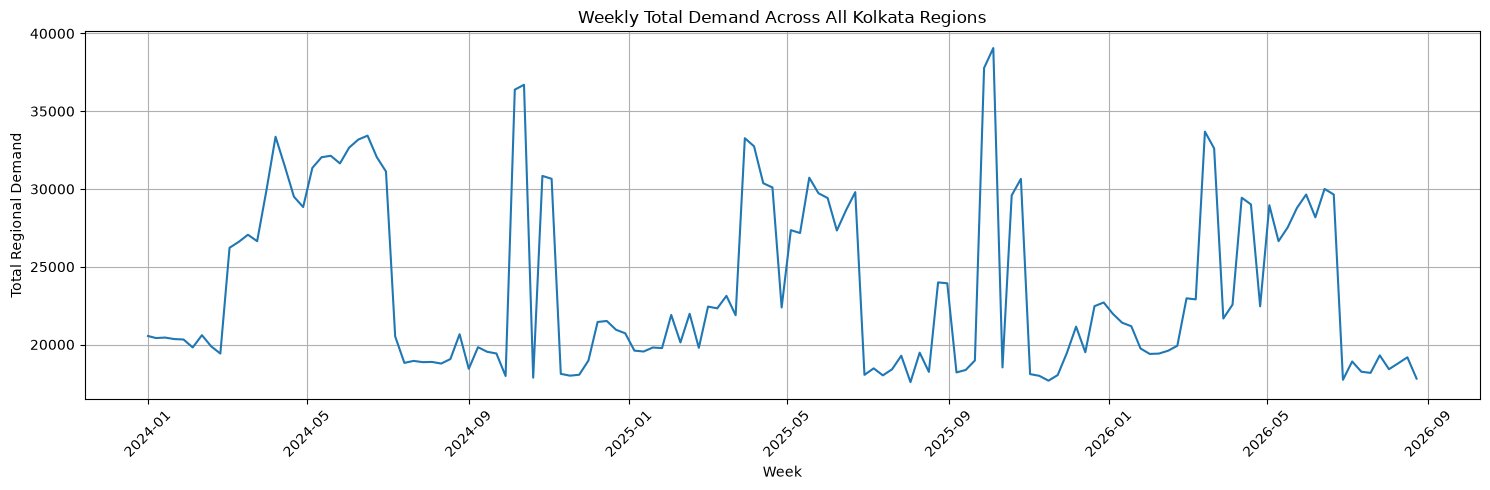

WEEKLY TREND DATA:


,time_idx,total_demand,week_start_date
0,0,20547,2024-01-01
1,1,20415,2024-01-07
2,2,20446,2024-01-14
3,3,20349,2024-01-21
4,4,20322,2024-01-28
5,5,19812,2024-02-04
6,6,20601,2024-02-11
7,7,19883,2024-02-18
8,8,19418,2024-02-25
9,9,26220,2024-03-03



TOTAL WEEKLY OBSERVATIONS:
139


In [92]:

# STEP 5.4 - CELL 74
# WEEKLY DEMAND TREND ANALYSIS

import matplotlib.pyplot as plt

# Calculate total demand across all regions for each week
weekly_trend = (
    model_df.groupby("time_idx", as_index=False)
    .agg(
        total_demand=("regional_demand", "sum"),
        week_start_date=("week_start_date", "first")
    )
)

# Plot weekly demand trend
plt.figure(figsize=(15, 5))

plt.plot(
    weekly_trend["week_start_date"],
    weekly_trend["total_demand"]
)

plt.title("Weekly Total Demand Across All Kolkata Regions")
plt.xlabel("Week")
plt.ylabel("Total Regional Demand")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

print("WEEKLY TREND DATA:")
display(weekly_trend.head(10))

print("\nTOTAL WEEKLY OBSERVATIONS:")
print(len(weekly_trend))


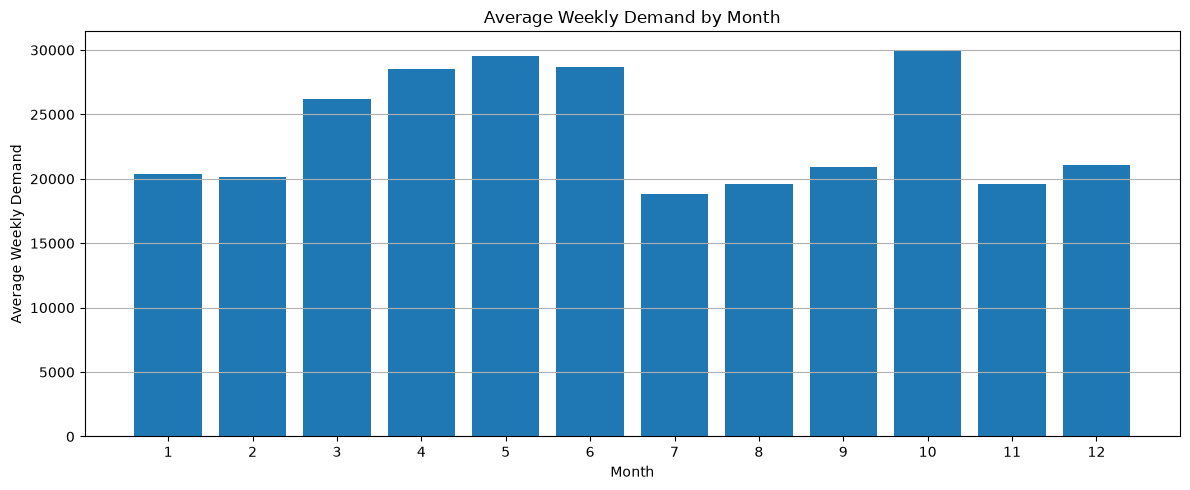

MONTHLY DEMAND SUMMARY:


,month,average_demand,minimum_demand,maximum_demand
0,1,20392.230769,19549,21969
1,2,20153.250000,19394,21978
2,3,26218.800000,21670,33687
3,4,28519.333333,22381,33359
4,5,29516.384615,26644,32135
5,6,28659.428571,17731,33430
6,7,18829.583333,18015,20523
7,8,19599.230769,17580,23993
8,9,20946.000000,17974,37781
9,10,29953.500000,17868,39063


In [93]:

# STEP 5.4 - CELL 75
# MONTHLY SEASONALITY ANALYSIS

# Extract month and year from weekly dates
weekly_trend["month"] = weekly_trend["week_start_date"].dt.month
weekly_trend["year"] = weekly_trend["week_start_date"].dt.year

# Calculate average demand for each month
monthly_demand = (
    weekly_trend.groupby("month", as_index=False)
    .agg(
        average_demand=("total_demand", "mean"),
        minimum_demand=("total_demand", "min"),
        maximum_demand=("total_demand", "max")
    )
)

# Plot monthly average demand
plt.figure(figsize=(12, 5))

plt.bar(
    monthly_demand["month"],
    monthly_demand["average_demand"]
)

plt.title("Average Weekly Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Weekly Demand")
plt.xticks(range(1, 13))
plt.grid(axis="y")
plt.tight_layout()
plt.show()

print("MONTHLY DEMAND SUMMARY:")
display(monthly_demand)


YEAR-WISE MONTHLY AVERAGE DEMAND:


year,2024,2025,2026
month,,,
1,20415.80,19682.75,21072.25
2,19928.50,20949.25,19582.00
3,27280.40,24608.00,26768.00
4,30792.50,28898.50,25867.00
5,31794.00,28743.75,28312.40
6,32489.00,26646.20,26389.00
7,19288.00,18541.75,18659.00
8,19345.00,20644.80,18546.50
9,19038.60,23330.25,NaN


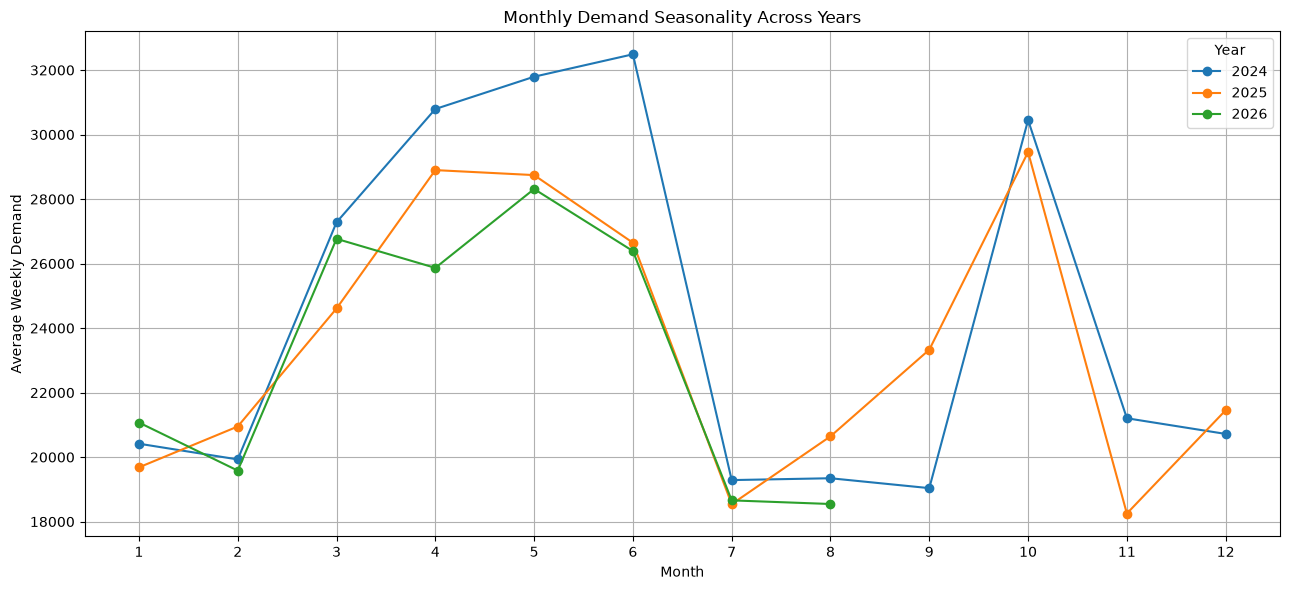

In [94]:

# STEP 5.5 - CELL 76
# YEAR-WISE MONTHLY DEMAND COMPARISON

yearly_monthly_demand = (
    weekly_trend.groupby(
        ["year", "month"], as_index=False
    )
    .agg(
        average_demand=("total_demand", "mean")
    )
)

# Convert data into a year vs month table
seasonality_table = yearly_monthly_demand.pivot(
    index="month",
    columns="year",
    values="average_demand"
)

print("YEAR-WISE MONTHLY AVERAGE DEMAND:")
display(seasonality_table.round(2))

# Plot comparison
seasonality_table.plot(
    kind="line",
    marker="o",
    figsize=(13, 6)
)

plt.title("Monthly Demand Seasonality Across Years")
plt.xlabel("Month")
plt.ylabel("Average Weekly Demand")
plt.xticks(range(1, 13))
plt.grid(True)
plt.legend(title="Year")
plt.tight_layout()
plt.show()


In [95]:

# STEP 5.5 - CELL 77
# FINAL FEATURE ENGINEERING VALIDATION

engineered_features = [
    "month",
    "quarter",
    "day_of_year",
    "month_sin",
    "month_cos",
    "year_sin",
    "year_cos",
    "lag_1",
    "lag_2",
    "lag_4",
    "lag_8",
    "rolling_mean_4",
    "rolling_mean_8",
    "rolling_std_4"
]

print("FINAL DATASET SHAPE:")
print(model_df.shape)

print("\nTOTAL UNIQUE REGIONS:")
print(model_df["region_of_kolkata"].nunique())

print("\nWEEKS PER REGION:")
display(
    model_df.groupby("region_of_kolkata")
    .size()
    .value_counts()
    .rename_axis("weeks_per_region")
    .reset_index(name="number_of_regions")
)

print("\nENGINEERED FEATURES:")
display(
    model_df[engineered_features].isnull().sum()
    .rename("missing_values")
    .reset_index()
    .rename(columns={"index": "feature"})
)

print("\nTARGET MISSING VALUES:")
print(model_df["regional_demand"].isnull().sum())

print("\nINFINITE VALUES:")
print(
    np.isinf(
        model_df.select_dtypes(include=np.number)
    ).sum().sum()
)

print("\nDUPLICATE REGION-WEEK RECORDS:")
print(
    model_df.duplicated(
        subset=["region_of_kolkata", "time_idx"]
    ).sum()
)


FINAL DATASET SHAPE:
(5560, 36)

TOTAL UNIQUE REGIONS:
40

WEEKS PER REGION:


,weeks_per_region,number_of_regions
0,139,40



ENGINEERED FEATURES:


,feature,missing_values
0,month,0
1,quarter,0
2,day_of_year,0
3,month_sin,0
4,month_cos,0
5,year_sin,0
6,year_cos,0
7,lag_1,40
8,lag_2,80
9,lag_4,160



TARGET MISSING VALUES:
0

INFINITE VALUES:
0

DUPLICATE REGION-WEEK RECORDS:
0


In [96]:

# STEP 6.1 - CELL 78
# DEFINE CHRONOLOGICAL SPLIT BOUNDARIES

TRAIN_END = 96
VALIDATION_END = 116
TEST_END = 138

print("TRAINING PERIOD:")
print(f"Time index: 0 to {TRAIN_END}")
print(f"Total weeks: {TRAIN_END + 1}")

print("\nVALIDATION PERIOD:")
print(f"Time index: {TRAIN_END + 1} to {VALIDATION_END}")
print(f"Total weeks: {VALIDATION_END - TRAIN_END}")

print("\nTESTING PERIOD:")
print(f"Time index: {VALIDATION_END + 1} to {TEST_END}")
print(f"Total weeks: {TEST_END - VALIDATION_END}")

print("\nTOTAL WEEKS:")
print(TEST_END + 1)


TRAINING PERIOD:
Time index: 0 to 96
Total weeks: 97

VALIDATION PERIOD:
Time index: 97 to 116
Total weeks: 20

TESTING PERIOD:
Time index: 117 to 138
Total weeks: 22

TOTAL WEEKS:
139


In [97]:

# STEP 6.2 - CELL 79
# CREATE TRAIN, VALIDATION AND TEST DATASETS

# Training data
train_df = model_df[
    model_df["time_idx"] <= TRAIN_END
].copy()

# Validation data
validation_df = model_df[
    (model_df["time_idx"] > TRAIN_END) &
    (model_df["time_idx"] <= VALIDATION_END)
].copy()

# Testing data
test_df = model_df[
    (model_df["time_idx"] > VALIDATION_END) &
    (model_df["time_idx"] <= TEST_END)
].copy()

# Display dataset shapes
print("TRAINING DATA SHAPE:")
print(train_df.shape)

print("\nVALIDATION DATA SHAPE:")
print(validation_df.shape)

print("\nTESTING DATA SHAPE:")
print(test_df.shape)

print("\nTOTAL SPLIT RECORDS:")
print(len(train_df) + len(validation_df) + len(test_df))


TRAINING DATA SHAPE:
(3880, 36)

VALIDATION DATA SHAPE:
(800, 36)

TESTING DATA SHAPE:
(880, 36)

TOTAL SPLIT RECORDS:
5560


In [98]:

# STEP 6.3 - CELL 80
# VERIFY CHRONOLOGICAL ORDER

print("TRAINING TIME INDEX:")
print(train_df["time_idx"].min(), "to", train_df["time_idx"].max())

print("\nVALIDATION TIME INDEX:")
print(validation_df["time_idx"].min(), "to", validation_df["time_idx"].max())

print("\nTESTING TIME INDEX:")
print(test_df["time_idx"].min(), "to", test_df["time_idx"].max())

# Verify chronological separation
print("\nCHRONOLOGICAL VALIDATION:")

print(
    "Training before validation:",
    train_df["time_idx"].max() < validation_df["time_idx"].min()
)

print(
    "Validation before testing:",
    validation_df["time_idx"].max() < test_df["time_idx"].min()
)

print(
    "Testing ends at final week:",
    test_df["time_idx"].max() == TEST_END
)


TRAINING TIME INDEX:
0 to 96

VALIDATION TIME INDEX:
97 to 116

TESTING TIME INDEX:
117 to 138

CHRONOLOGICAL VALIDATION:
Training before validation: True
Validation before testing: True
Testing ends at final week: True


In [99]:
# STEP 6.4 - CELL 81
# VERIFY REGION COVERAGE IN EACH DATASET

print("TRAINING REGIONS:", train_df["region_of_kolkata"].nunique())
print("VALIDATION REGIONS:", validation_df["region_of_kolkata"].nunique())
print("TESTING REGIONS:", test_df["region_of_kolkata"].nunique())

print("\nREGION COVERAGE CHECK:")

print(
    "All 40 regions in training:",
    train_df["region_of_kolkata"].nunique() == 40
)

print(
    "All 40 regions in validation:",
    validation_df["region_of_kolkata"].nunique() == 40
)

print(
    "All 40 regions in testing:",
    test_df["region_of_kolkata"].nunique() == 40
)

# Check rows per region in each dataset
print("\nROWS PER REGION:")

print("Training:")
print(train_df.groupby("region_of_kolkata").size().value_counts())

print("\nValidation:")
print(validation_df.groupby("region_of_kolkata").size().value_counts())

print("\nTesting:")
print(test_df.groupby("region_of_kolkata").size().value_counts())

TRAINING REGIONS: 40
VALIDATION REGIONS: 40
TESTING REGIONS: 40

REGION COVERAGE CHECK:
All 40 regions in training: True
All 40 regions in validation: True
All 40 regions in testing: True

ROWS PER REGION:
Training:
97    40
Name: count, dtype: int64

Validation:
20    40
Name: count, dtype: int64

Testing:
22    40
Name: count, dtype: int64


In [100]:
# STEP 6.5 - CELL 82
# CHECK FOR DATA LEAKAGE

# 1. Columns that must not be used as model input features
leakage_columns = [
    "next_week_demand_target_units",
    "demand_rank",
    "weekday_units_sold",
    "weekend_units_sold",
    "forecast_target_start",
    "forecast_target_end",
    "demand_id",
    "region_product_week_key",
    "recorded_at"
]

# Check whether any of these columns exist in model_df
present_leakage_columns = [
    col for col in leakage_columns
    if col in model_df.columns
]

print("POTENTIAL LEAKAGE COLUMNS:")
print(present_leakage_columns)

# 2. Check target column
print("\nTARGET COLUMN CHECK:")

for name, data in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Testing", test_df)
]:
    print(
        name,
        "- Missing target values:",
        data["regional_demand"].isnull().sum()
    )

# 3. Confirm that the target is not missing
print("\nTARGET VALIDATION:")

print(
    "Training target complete:",
    train_df["regional_demand"].notna().all()
)

print(
    "Validation target complete:",
    validation_df["regional_demand"].notna().all()
)

print(
    "Testing target complete:",
    test_df["regional_demand"].notna().all()
)

POTENTIAL LEAKAGE COLUMNS:
[]

TARGET COLUMN CHECK:
Training - Missing target values: 0
Validation - Missing target values: 0
Testing - Missing target values: 0

TARGET VALIDATION:
Training target complete: True
Validation target complete: True
Testing target complete: True


In [101]:
# STEP 6.6 - CELL 83
# FINAL VALIDATION OF TRAIN, VALIDATION AND TEST DATA

datasets = {
    "Training": train_df,
    "Validation": validation_df,
    "Testing": test_df
}

for name, data in datasets.items():

    print("\n", "=" * 45)
    print(name.upper())
    print("=" * 45)

    print("Shape:", data.shape)

    print(
        "Number of regions:",
        data["region_of_kolkata"].nunique()
    )

    print(
        "Time index:",
        data["time_idx"].min(),
        "to",
        data["time_idx"].max()
    )

    print(
        "Missing values:",
        data.isnull().sum().sum()
    )

    print(
        "Duplicate region-week rows:",
        data.duplicated(
            subset=["region_of_kolkata", "time_idx"]
        ).sum()
    )

print("\nTOTAL ROWS:")
print(len(train_df) + len(validation_df) + len(test_df))

print("\nORIGINAL MODEL DATA ROWS:")
print(len(model_df))


TRAINING
Shape: (3880, 36)
Number of regions: 40
Time index: 0 to 96
Missing values: 1240
Duplicate region-week rows: 0

VALIDATION
Shape: (800, 36)
Number of regions: 40
Time index: 97 to 116
Missing values: 0
Duplicate region-week rows: 0

TESTING
Shape: (880, 36)
Number of regions: 40
Time index: 117 to 138
Missing values: 0
Duplicate region-week rows: 0

TOTAL ROWS:
5560

ORIGINAL MODEL DATA ROWS:
5560


In [102]:
# STEP 6.6 - CELL 84
# IDENTIFY MISSING VALUES IN EACH DATASET

for name, data in {
    "Training": train_df,
    "Validation": validation_df,
    "Testing": test_df
}.items():

    print("\n", "=" * 40)
    print(name.upper(), "- MISSING VALUES")
    print("=" * 40)

    missing = data.isnull().sum()

    print(missing[missing > 0])

    print("\nTotal missing values:", missing.sum())


TRAINING - MISSING VALUES
lag_1              40
lag_2              80
lag_4             160
lag_8             320
rolling_mean_4    160
rolling_mean_8    320
rolling_std_4     160
dtype: int64

Total missing values: 1240

VALIDATION - MISSING VALUES
Series([], dtype: int64)

Total missing values: 0

TESTING - MISSING VALUES
Series([], dtype: int64)

Total missing values: 0


In [103]:
# STEP 7.1 - CELL 85
# DEFINE TFT INPUT FEATURES

# 1. Prediction target
target = "regional_demand"

# 2. Group identifier
group_ids = ["region_of_kolkata"]

# 3. Known future numerical features
known_reals = [
    "time_idx",
    "month",
    "quarter",
    "day_of_year",
    "month_sin",
    "month_cos",
    "year_sin",
    "year_cos",
    "holiday_flag"
]

# 4. Unknown future numerical features
unknown_reals = [
    "regional_demand",
    "temperature_c",
    "rainfall_mm",
    "humidity_pct",
    "promotion_product_count",
    "promotion_rate",
    "average_discount_pct",
    "average_selling_price_rs",
    "stockout_product_count",
    "stockout_rate"
]

# 5. Known future categorical features
known_categoricals = [
    "festival_event",
    "season"
]

# 6. Unknown future categorical features
unknown_categoricals = [
    "weather_condition"
]

# 7. Verify all selected columns exist
selected_features = (
    [target]
    + group_ids
    + known_reals
    + unknown_reals
    + known_categoricals
    + unknown_categoricals
)

missing_features = [
    col for col in selected_features
    if col not in model_df.columns
]

print("TOTAL SELECTED FEATURES:", len(selected_features))

print("\nMISSING FEATURES:")
print(missing_features)

print("\nFEATURE SELECTION VALIDATION:")
print("All features exist:", len(missing_features) == 0)

print("\nTARGET:")
print(target)

print("\nGROUP ID:")
print(group_ids)

print("\nKNOWN REAL FEATURES:", len(known_reals))
print(known_reals)

print("\nUNKNOWN REAL FEATURES:", len(unknown_reals))
print(unknown_reals)

print("\nKNOWN CATEGORICAL FEATURES:", len(known_categoricals))
print(known_categoricals)

print("\nUNKNOWN CATEGORICAL FEATURES:", len(unknown_categoricals))
print(unknown_categoricals)

TOTAL SELECTED FEATURES: 24

MISSING FEATURES:
[]

FEATURE SELECTION VALIDATION:
All features exist: True

TARGET:
regional_demand

GROUP ID:
['region_of_kolkata']

KNOWN REAL FEATURES: 9
['time_idx', 'month', 'quarter', 'day_of_year', 'month_sin', 'month_cos', 'year_sin', 'year_cos', 'holiday_flag']

UNKNOWN REAL FEATURES: 10
['regional_demand', 'temperature_c', 'rainfall_mm', 'humidity_pct', 'promotion_product_count', 'promotion_rate', 'average_discount_pct', 'average_selling_price_rs', 'stockout_product_count', 'stockout_rate']

KNOWN CATEGORICAL FEATURES: 2
['festival_event', 'season']

UNKNOWN CATEGORICAL FEATURES: 1
['weather_condition']


In [104]:
# STEP 7.2 - CELL 86
# DEFINE STATIC AND TIME-VARYING VARIABLES

# 1. Static categorical variables
static_categoricals = [
    "region_of_kolkata"
]

# 2. Time-varying known numerical variables
time_varying_known_reals = known_reals.copy()

# 3. Time-varying unknown numerical variables
time_varying_unknown_reals = unknown_reals.copy()

# 4. Time-varying known categorical variables
time_varying_known_categoricals = known_categoricals.copy()

# 5. Time-varying unknown categorical variables
time_varying_unknown_categoricals = unknown_categoricals.copy()

# 6. Display variable configuration
print("STATIC CATEGORICAL:")
print(static_categoricals)

print("\nTIME-VARYING KNOWN REALS:")
print(time_varying_known_reals)

print("\nTIME-VARYING UNKNOWN REALS:")
print(time_varying_unknown_reals)

print("\nTIME-VARYING KNOWN CATEGORICALS:")
print(time_varying_known_categoricals)

print("\nTIME-VARYING UNKNOWN CATEGORICALS:")
print(time_varying_unknown_categoricals)

# 7. Verify static region count
print("\nNUMBER OF REGIONS:")
print(model_df["region_of_kolkata"].nunique())

STATIC CATEGORICAL:
['region_of_kolkata']

TIME-VARYING KNOWN REALS:
['time_idx', 'month', 'quarter', 'day_of_year', 'month_sin', 'month_cos', 'year_sin', 'year_cos', 'holiday_flag']

TIME-VARYING UNKNOWN REALS:
['regional_demand', 'temperature_c', 'rainfall_mm', 'humidity_pct', 'promotion_product_count', 'promotion_rate', 'average_discount_pct', 'average_selling_price_rs', 'stockout_product_count', 'stockout_rate']

TIME-VARYING KNOWN CATEGORICALS:
['festival_event', 'season']

TIME-VARYING UNKNOWN CATEGORICALS:
['weather_condition']

NUMBER OF REGIONS:
40


In [105]:
# STEP 7.3 - CELL 87
# DEFINE ENCODER AND PREDICTION LENGTH

# Historical weeks used by TFT
max_encoder_length = 26

# Future weeks predicted by TFT
max_prediction_length = 1

# Minimum history required
min_encoder_length = 26

min_prediction_length = 1

print("TFT SEQUENCE CONFIGURATION")

print("Maximum encoder length:", max_encoder_length)
print("Minimum encoder length:", min_encoder_length)

print("Maximum prediction length:", max_prediction_length)
print("Minimum prediction length:", min_prediction_length)

# Check training history
print("\nTRAINING HISTORY CHECK")

print("Training weeks:", TRAIN_END + 1)

print(
    "Enough history for encoder:",
    (TRAIN_END + 1) >= max_encoder_length
)

TFT SEQUENCE CONFIGURATION
Maximum encoder length: 26
Minimum encoder length: 26
Maximum prediction length: 1
Minimum prediction length: 1

TRAINING HISTORY CHECK
Training weeks: 97
Enough history for encoder: True


In [106]:
# STEP 7.4 - CELL 88
# PREPARE DATA TYPES FOR PYTORCH FORECASTING

# 1. Categorical columns
categorical_columns = (
    static_categoricals
    + time_varying_known_categoricals
    + time_varying_unknown_categoricals
)

# 2. Numerical columns
numerical_columns = (
    [target]
    + time_varying_known_reals
    + time_varying_unknown_reals
)

# Remove duplicates while preserving order
categorical_columns = list(dict.fromkeys(categorical_columns))
numerical_columns = list(dict.fromkeys(numerical_columns))

# 3. Prepare all datasets
datasets_to_prepare = {
    "model_df": model_df,
    "train_df": train_df,
    "validation_df": validation_df,
    "test_df": test_df
}

for name, data in datasets_to_prepare.items():

    # Convert categorical features to strings
    for col in categorical_columns:
        data[col] = data[col].astype(str)

    # Convert numerical features to numeric values
    for col in numerical_columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

    # Keep time index as integer
    data["time_idx"] = data["time_idx"].astype(int)

    print(name, "prepared:", data.shape)

# 4. Verify data types
print("\nCATEGORICAL DATA TYPES:")
print(train_df[categorical_columns].dtypes)

print("\nNUMERICAL DATA TYPES:")
print(train_df[numerical_columns].dtypes)

# 5. Check missing values in selected TFT features
print("\nMISSING VALUES IN SELECTED FEATURES:")
print(train_df[selected_features].isnull().sum())

print("\nTOTAL MISSING SELECTED VALUES:")
print(train_df[selected_features].isnull().sum().sum())

model_df prepared: (5560, 36)
train_df prepared: (3880, 36)
validation_df prepared: (800, 36)
test_df prepared: (880, 36)

CATEGORICAL DATA TYPES:
region_of_kolkata    str
festival_event       str
season               str
weather_condition    str
dtype: object

NUMERICAL DATA TYPES:
regional_demand               int64
time_idx                      int64
month                         int32
quarter                       int32
day_of_year                   int32
month_sin                   float64
month_cos                   float64
year_sin                    float64
year_cos                    float64
holiday_flag                  int64
temperature_c               float64
rainfall_mm                 float64
humidity_pct                float64
promotion_product_count       int64
promotion_rate              float64
average_discount_pct        float64
average_selling_price_rs    float64
stockout_product_count        int64
stockout_rate               float64
dtype: object

MISSING VALUES IN

In [107]:
# STEP 7.5 - CELL 89
# IMPORT PYTORCH FORECASTING

import torch
import lightning.pytorch as pl

from pytorch_forecasting import TimeSeriesDataSet
from pytorch_forecasting.data import GroupNormalizer

print("PyTorch version:", torch.__version__)
print("Lightning version:", pl.__version__)

print("\nTimeSeriesDataSet imported successfully!")
print("GroupNormalizer imported successfully!")

print("\nCUDA available:", torch.cuda.is_available())

PyTorch version: 2.15.0+cpu
Lightning version: 2.6.6

TimeSeriesDataSet imported successfully!
GroupNormalizer imported successfully!

CUDA available: False


In [109]:
# STEP 7.5 - CELL 90
# CREATE TFT TRAINING DATASET

from pytorch_forecasting.data.encoders import NaNLabelEncoder

# Create the TFT training dataset
training = TimeSeriesDataSet(
    train_df,

    # Identify time and target
    time_idx="time_idx",
    target=target,
    group_ids=group_ids,

    # Encoder and prediction lengths
    min_encoder_length=min_encoder_length,
    max_encoder_length=max_encoder_length,
    min_prediction_length=min_prediction_length,
    max_prediction_length=max_prediction_length,

    # Static variables
    static_categoricals=static_categoricals,

    # Time-varying variables
    time_varying_known_reals=time_varying_known_reals,
    time_varying_unknown_reals=time_varying_unknown_reals,
    time_varying_known_categoricals=time_varying_known_categoricals,
    time_varying_unknown_categoricals=time_varying_unknown_categoricals,

    # Normalize target separately for each region
    target_normalizer=GroupNormalizer(
        groups=group_ids
    ),

    # Additional TFT time-series information
    add_relative_time_idx=True,
    add_target_scales=True,
    add_encoder_length=True,

    # Handle categorical labels
    categorical_encoders={
        col: NaNLabelEncoder(add_nan=True)
        for col in categorical_columns
    }
)

print("TFT TRAINING DATASET CREATED SUCCESSFULLY!")

print("\nTOTAL TRAINING SEQUENCES:", len(training))

print("\nNUMBER OF REGIONS:", train_df["region_of_kolkata"].nunique())

print("\nENCODER LENGTH:", max_encoder_length)

print("PREDICTION LENGTH:", max_prediction_length)

print("\nDATASET OBJECT TYPE:")
print(type(training))

TFT TRAINING DATASET CREATED SUCCESSFULLY!

TOTAL TRAINING SEQUENCES: 2840

NUMBER OF REGIONS: 40

ENCODER LENGTH: 26
PREDICTION LENGTH: 1

DATASET OBJECT TYPE:
<class 'pytorch_forecasting.data.timeseries._timeseries.TimeSeriesDataSet'>


In [110]:
# STEP 7.6 - CELL 91

print("TRAINING DATASET SUMMARY")
print("========================")

print("Total sequences:", len(training))
print("Number of regions:", train_df["region_of_kolkata"].nunique())

parameters = training.get_parameters()

print("\nDATASET PARAMETERS:")
print("Target:", parameters["target"])
print("Time index:", parameters["time_idx"])
print("Group IDs:", parameters["group_ids"])

print("\nENCODER AND PREDICTION LENGTH:")
print("Maximum encoder:", parameters["max_encoder_length"])
print("Maximum prediction:", parameters["max_prediction_length"])

print("\nFIRST TRAINING SAMPLE:")
print(training[0])

TRAINING DATASET SUMMARY
Total sequences: 2840
Number of regions: 40

DATASET PARAMETERS:
Target: regional_demand
Time index: time_idx
Group IDs: ['region_of_kolkata']

ENCODER AND PREDICTION LENGTH:
Maximum encoder: 26
Maximum prediction: 1

FIRST TRAINING SAMPLE:
({'x_cat': tensor([[ 1, 12,  5,  1],
        [ 1, 12,  5,  1],
        [ 1, 12,  5,  1],
        [ 1, 12,  5,  1],
        [ 1, 12,  5,  1],
        [ 1, 12,  5,  1],
        [ 1, 15,  5,  1],
        [ 1, 12,  5,  1],
        [ 1, 12,  5,  1],
        [ 1, 12,  3,  1],
        [ 1, 12,  3,  1],
        [ 1, 12,  3,  1],
        [ 1, 12,  3,  1],
        [ 1, 12,  3,  1],
        [ 1,  6,  3,  1],
        [ 1, 13,  3,  1],
        [ 1, 12,  3,  1],
        [ 1, 12,  3,  1],
        [ 1, 12,  4,  1],
        [ 1, 12,  4,  1],
        [ 1, 12,  4,  1],
        [ 1, 12,  4,  1],
        [ 1, 12,  4,  1],
        [ 1, 12,  4,  1],
        [ 1, 12,  4,  1],
        [ 1, 12,  4,  1],
        [ 1, 12,  4,  1]]), 'x_cont': tensor([[

In [112]:
# STEP 7.6 - CELL 92
# CREATE TFT VALIDATION DATASET

# Keep training history plus validation period
validation_data = model_df[
    model_df["time_idx"] <= VALIDATION_END
].copy()

# Create validation dataset using training configuration
validation = TimeSeriesDataSet.from_dataset(
    training,
    validation_data,
    min_prediction_idx=TRAIN_END + 1,
    stop_randomization=True
)

# Display validation dataset information
print("VALIDATION DATASET CREATED SUCCESSFULLY!")

print("\nVALIDATION SEQUENCES:", len(validation))

print(
    "NUMBER OF REGIONS:",
    validation_data["region_of_kolkata"].nunique()
)

print("\nVALIDATION PERIOD:")
print(
    validation_data[
        validation_data["time_idx"] > TRAIN_END
    ]["time_idx"].min(),
    "to",
    validation_data["time_idx"].max()
)

# INSPECT FIRST VALIDATION SAMPLE

sample_x, sample_y = validation[0]

print("\nFIRST VALIDATION SAMPLE")

print("\nAvailable input keys:")
print(sample_x.keys())

print("\nEncoder start:", sample_x["encoder_time_idx_start"])
print("Encoder length:", sample_x["encoder_length"])
print("Decoder length:", sample_x["decoder_length"])

print("\nDecoder target:")
print(sample_y[0])

print("\nVALIDATION DATASET CHECK:")
print("Total validation sequences:", len(validation))
print("Expected validation sequences:", 800)
print("Validation dataset correct:", len(validation) == 800)

VALIDATION DATASET CREATED SUCCESSFULLY!

VALIDATION SEQUENCES: 800
NUMBER OF REGIONS: 40

VALIDATION PERIOD:
97 to 116

FIRST VALIDATION SAMPLE

Available input keys:
dict_keys(['x_cat', 'x_cont', 'encoder_length', 'decoder_length', 'encoder_target', 'encoder_time_idx_start', 'groups', 'target_scale'])

Encoder start: tensor(71)
Encoder length: 26
Decoder length: 1

Decoder target:
tensor([483])

VALIDATION DATASET CHECK:
Total validation sequences: 800
Expected validation sequences: 800
Validation dataset correct: True


In [113]:
# STEP 7.6 - CELL 93
# CREATE TFT TEST DATASET

# Keep all historical data up to the end of the test period
test_data = model_df[
    model_df["time_idx"] <= TEST_END
].copy()

# Create test dataset using the training configuration
testing = TimeSeriesDataSet.from_dataset(
    training,
    test_data,
    min_prediction_idx=VALIDATION_END + 1,
    stop_randomization=True
)

# Display test dataset information
print("TEST DATASET CREATED SUCCESSFULLY!")

print("\nTEST SEQUENCES:", len(testing))

print(
    "NUMBER OF REGIONS:",
    test_data["region_of_kolkata"].nunique()
)

print("\nTEST PERIOD:")
print(
    test_data[
        test_data["time_idx"] > VALIDATION_END
    ]["time_idx"].min(),
    "to",
    test_data["time_idx"].max()
)

# Inspect first test sample
sample_x, sample_y = testing[0]

print("\nFIRST TEST SAMPLE:")
print("Encoder start:", sample_x["encoder_time_idx_start"])
print("Encoder length:", sample_x["encoder_length"])
print("Decoder length:", sample_x["decoder_length"])
print("Decoder target:", sample_y[0])

print("\nTEST DATASET CHECK:")
print("Expected test sequences: 880")
print("Actual test sequences:", len(testing))
print("Test dataset correct:", len(testing) == 880)

TEST DATASET CREATED SUCCESSFULLY!

TEST SEQUENCES: 880
NUMBER OF REGIONS: 40

TEST PERIOD:
117 to 138

FIRST TEST SAMPLE:
Encoder start: tensor(91)
Encoder length: 26
Decoder length: 1
Decoder target: tensor([541])

TEST DATASET CHECK:
Expected test sequences: 880
Actual test sequences: 880
Test dataset correct: True


In [114]:
# STEP 8.1 - CELL 94
# CONFIGURE TFT HYPERPARAMETERS

# Model architecture settings
hidden_size = 16
attention_head_size = 4
dropout = 0.1
hidden_continuous_size = 8

# Training settings
learning_rate = 0.001
max_epochs = 30
gradient_clip_val = 0.1

# Forecasting settings
output_size = 7

print("TFT HYPERPARAMETERS CONFIGURED")

print("\nMODEL SETTINGS:")
print("Hidden size:", hidden_size)
print("Attention heads:", attention_head_size)
print("Dropout:", dropout)
print("Hidden continuous size:", hidden_continuous_size)

print("\nTRAINING SETTINGS:")
print("Learning rate:", learning_rate)
print("Maximum epochs:", max_epochs)
print("Gradient clipping:", gradient_clip_val)

print("\nFORECASTING SETTINGS:")
print("Output size:", output_size)

TFT HYPERPARAMETERS CONFIGURED

MODEL SETTINGS:
Hidden size: 16
Attention heads: 4
Dropout: 0.1
Hidden continuous size: 8

TRAINING SETTINGS:
Learning rate: 0.001
Maximum epochs: 30
Gradient clipping: 0.1

FORECASTING SETTINGS:
Output size: 7


In [115]:
# STEP 8.2 - CELL 95
# CREATE TEMPORAL FUSION TRANSFORMER MODEL

from pytorch_forecasting import TemporalFusionTransformer
from pytorch_forecasting.metrics import QuantileLoss

# Create TFT model
tft = TemporalFusionTransformer.from_dataset(
    training,

    # Model architecture
    hidden_size=hidden_size,
    attention_head_size=attention_head_size,
    dropout=dropout,
    hidden_continuous_size=hidden_continuous_size,

    # Training configuration
    learning_rate=learning_rate,
    optimizer="adam",

    # Forecast output
    output_size=output_size,
    loss=QuantileLoss(),

    # Learning rate adjustment
    reduce_on_plateau_patience=4
)

print("TFT MODEL CREATED SUCCESSFULLY!")

print("\nMODEL TYPE:")
print(type(tft))

print("\nMODEL PARAMETERS:")
print(
    "Total trainable parameters:",
    sum(p.numel() for p in tft.parameters() if p.requires_grad)
)

print("\nMODEL CONFIGURATION:")
print("Hidden size:", hidden_size)
print("Attention heads:", attention_head_size)
print("Dropout:", dropout)
print("Output size:", output_size)
print("Learning rate:", learning_rate)

TFT MODEL CREATED SUCCESSFULLY!

MODEL TYPE:
<class 'pytorch_forecasting.models.temporal_fusion_transformer._tft.TemporalFusionTransformer'>

MODEL PARAMETERS:
Total trainable parameters: 38441

MODEL CONFIGURATION:
Hidden size: 16
Attention heads: 4
Dropout: 0.1
Output size: 7
Learning rate: 0.001


In [116]:
# STEP 8.3 - CELL 96
# INSPECT TFT MODEL ARCHITECTURE

# Display complete model architecture
print("TFT MODEL ARCHITECTURE:\n")
print(tft)

# Count trainable parameters
trainable_params = sum(
    p.numel()
    for p in tft.parameters()
    if p.requires_grad
)

# Count all parameters
total_params = sum(
    p.numel()
    for p in tft.parameters()
)

print("\nMODEL PARAMETER SUMMARY")
print("Trainable parameters:", trainable_params)
print("Total parameters:", total_params)

print("\nMODEL READY CHECK")
print("TFT model exists:", tft is not None)
print("Training dataset exists:", training is not None)
print("Validation dataset exists:", validation is not None)
print("Test dataset exists:", testing is not None)

TFT MODEL ARCHITECTURE:

TemporalFusionTransformer(
  	"attention_head_size":               4
  	"categorical_groups":                {}
  	"causal_attention":                  True
  	"dataset_parameters":                {'time_idx': 'time_idx', 'target': 'regional_demand', 'group_ids': ['region_of_kolkata'], 'weight': None, 'max_encoder_length': 26, 'min_encoder_length': 26, 'min_prediction_idx': np.int64(0), 'min_prediction_length': 1, 'max_prediction_length': 1, 'static_categoricals': ['region_of_kolkata'], 'static_reals': None, 'time_varying_known_categoricals': ['festival_event', 'season'], 'time_varying_known_reals': ['time_idx', 'month', 'quarter', 'day_of_year', 'month_sin', 'month_cos', 'year_sin', 'year_cos', 'holiday_flag'], 'time_varying_unknown_categoricals': ['weather_condition'], 'time_varying_unknown_reals': ['regional_demand', 'temperature_c', 'rainfall_mm', 'humidity_pct', 'promotion_product_count', 'promotion_rate', 'average_discount_pct', 'average_selling_price_rs'

In [117]:
# STEP 8.4 - CELL 97
# CONFIGURE TRAINING CALLBACKS

from lightning.pytorch.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    LearningRateMonitor
)

# 1. Early stopping
early_stop_callback = EarlyStopping(
    monitor="val_loss",
    min_delta=0.001,
    patience=5,
    verbose=True,
    mode="min"
)

# 2. Save the best model
checkpoint_callback = ModelCheckpoint(
    monitor="val_loss",
    dirpath="checkpoints",
    filename="best-tft-{epoch:02d}-{val_loss:.4f}",
    save_top_k=1,
    mode="min"
)

# 3. Monitor learning rate
lr_logger = LearningRateMonitor(
    logging_interval="epoch"
)

print("TRAINING CALLBACKS CONFIGURED!")

print("\nEARLY STOPPING:")
print("Monitor: val_loss")
print("Patience: 5 epochs")

print("\nMODEL CHECKPOINT:")
print("Save directory: checkpoints")
print("Save best model: Yes")

print("\nLEARNING RATE MONITOR:")
print("Monitoring interval: epoch")

TRAINING CALLBACKS CONFIGURED!

EARLY STOPPING:
Monitor: val_loss
Patience: 5 epochs

MODEL CHECKPOINT:
Save directory: checkpoints
Save best model: Yes

LEARNING RATE MONITOR:
Monitoring interval: epoch


In [118]:
# STEP 8.5 - CELL 98
# CONFIGURE LIGHTNING TRAINER

import lightning.pytorch as pl

# Configure trainer
trainer = pl.Trainer(
    max_epochs=max_epochs,
    accelerator="cpu",
    devices=1,

    # Prevent excessively large gradient updates
    gradient_clip_val=gradient_clip_val,

    # Training callbacks
    callbacks=[
        early_stop_callback,
        checkpoint_callback,
        lr_logger
    ],

    # Display training progress
    enable_progress_bar=True,

    # Model summary
    enable_model_summary=True,

    # Logging
    log_every_n_steps=10,

    # Save checkpoints
    enable_checkpointing=True
)

print("LIGHTNING TRAINER CONFIGURED!")

print("\nTRAINER SETTINGS:")
print("Maximum epochs:", max_epochs)
print("Accelerator: CPU")
print("Devices: 1")
print("Gradient clipping:", gradient_clip_val)

print("\nCALLBACKS:")
print("Early stopping:", early_stop_callback is not None)
print("Model checkpoint:", checkpoint_callback is not None)
print("Learning rate monitor:", lr_logger is not None)

print("\nTRAINER READY:", trainer is not None)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


LIGHTNING TRAINER CONFIGURED!

TRAINER SETTINGS:
Maximum epochs: 30
Accelerator: CPU
Devices: 1
Gradient clipping: 0.1

CALLBACKS:
Early stopping: True
Model checkpoint: True
Learning rate monitor: True

TRAINER READY: True


In [119]:
# STEP 8.6 - CELL 99
# START TFT MODEL TRAINING

print("STARTING TFT MODEL TRAINING...")

trainer.fit(
    tft,
    train_dataloaders=training.to_dataloader(
        train=True,
        batch_size=64,
        num_workers=0
    ),
    val_dataloaders=validation.to_dataloader(
        train=False,
        batch_size=64,
        num_workers=0
    )
)

print("\nTFT MODEL TRAINING COMPLETED!")

STARTING TFT MODEL TRAINING...



   | Name                               | Type                            | Params | Mode  | FLOPs
--------------------------------------------------------------------------------------------------------
0  | loss                               | QuantileLoss                    | 0      | train | 0    
1  | logging_metrics                    | ModuleList                      | 0      | train | 0    
2  | input_embeddings                   | MultiEmbedding                  | 713    | train | 0    
3  | prescalers                         | ModuleDict                      | 368    | train | 0    
4  | static_variable_selection          | VariableSelectionNetwork        | 1.9 K  | train | 0    
5  | encoder_variable_selection         | VariableSelectionNetwork        | 15.0 K | train | 0    
6  | decoder_variable_selection         | VariableSelectionNetwork        | 7.2 K  | train | 0    
7  | static_context_variable_selection  | GatedResidualNetwork            | 1.1 K  | train | 0    
8  

Epoch 0: 100%|██████████| 44/44 [00:10<00:00,  4.35it/s, v_num=10, train_loss_step=70.50, val_loss=51.30, train_loss_epoch=88.60]

Metric val_loss improved. New best score: 51.275


Epoch 1: 100%|██████████| 44/44 [00:08<00:00,  5.00it/s, v_num=10, train_loss_step=44.90, val_loss=41.80, train_loss_epoch=53.50]

Metric val_loss improved by 9.432 >= min_delta = 0.001. New best score: 41.842


... (19 outputs left out)

Metric val_loss improved by 1.238 >= min_delta = 0.001. New best score: 27.427


Epoch 20: 100%|██████████| 44/44 [00:07<00:00,  6.04it/s, v_num=10, train_loss_step=23.20, val_loss=27.80, train_loss_epoch=23.20]

Monitored metric val_loss did not improve in the last 5 records. Best score: 27.427. Signaling Trainer to stop.


Epoch 20: 100%|██████████| 44/44 [00:07<00:00,  6.04it/s, v_num=10, train_loss_step=23.20, val_loss=27.80, train_loss_epoch=23.20]

TFT MODEL TRAINING COMPLETED!


In [120]:
# STEP 8.7 - CELL 100
# EXTRACT TFT TRAINING METRICS

metrics = trainer.callback_metrics

print("TRAINING METRICS")

for metric_name, metric_value in metrics.items():
    if hasattr(metric_value, "item"):
        metric_value = metric_value.item()

    print(metric_name, ":", metric_value)

print("\nBEST VALIDATION LOSS:")
print(checkpoint_callback.best_model_score)

print("\nBEST MODEL CHECKPOINT:")
print(checkpoint_callback.best_model_path)

print("\nEPOCHS COMPLETED:")
print(trainer.current_epoch)

TRAINING METRICS
lr-Adam : 0.0010000000474974513
train_loss : 23.170486450195312
train_loss_step : 23.183300018310547
val_loss : 27.83538055419922
val_SMAPE : 0.09090734273195267
val_MAE : 50.08143997192383
val_RMSE : 66.97423553466797
val_MAPE : 0.09107832610607147
train_loss_epoch : 23.170486450195312

BEST VALIDATION LOSS:
tensor(27.4272)

BEST MODEL CHECKPOINT:
C:\Users\kaifa\ai-multi-agent-supply-chain\checkpoints\best-tft-epoch=15-val_loss=27.4272.ckpt

EPOCHS COMPLETED:
21


In [122]:
# STEP 8.7 - CELL 101
# INSPECT TRAINING LOGGER

print("NUMBER OF LOGGERS:", len(trainer.loggers))

for logger in trainer.loggers:

    print("\nLOGGER TYPE:", type(logger))

    print("LOGGER NAME:", logger.name)

    print("LOGGER VERSION:", logger.version)

    # Check if logged metrics are available
    if hasattr(logger, "experiment"):

        experiment = logger.experiment

        if hasattr(experiment, "metrics"):
            print("\nRECORDED METRICS:")
            print(experiment.metrics())

print("\nBEST VALIDATION LOSS:",
      checkpoint_callback.best_model_score)

print("\nBEST CHECKPOINT:")
print(checkpoint_callback.best_model_path)

NUMBER OF LOGGERS: 1

LOGGER TYPE: <class 'lightning.pytorch.loggers.tensorboard.TensorBoardLogger'>
LOGGER NAME: lightning_logs
LOGGER VERSION: 10

BEST VALIDATION LOSS: tensor(27.4272)

BEST CHECKPOINT:
C:\Users\kaifa\ai-multi-agent-supply-chain\checkpoints\best-tft-epoch=15-val_loss=27.4272.ckpt


In [123]:
# STEP 8.8 - CELL 102
# LOAD BEST TFT MODEL CHECKPOINT

best_checkpoint_path = checkpoint_callback.best_model_path

best_tft = TemporalFusionTransformer.load_from_checkpoint(
    best_checkpoint_path
)

print("BEST TFT MODEL LOADED SUCCESSFULLY!")

print("\nCHECKPOINT PATH:")
print(best_checkpoint_path)

print("\nMODEL VERIFICATION:")
print("Model loaded:", best_tft is not None)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in best_tft.parameters()
        if p.requires_grad
    )
)

print("\nBEST VALIDATION LOSS:")
print(float(checkpoint_callback.best_model_score))

BEST TFT MODEL LOADED SUCCESSFULLY!

CHECKPOINT PATH:
C:\Users\kaifa\ai-multi-agent-supply-chain\checkpoints\best-tft-epoch=15-val_loss=27.4272.ckpt

MODEL VERIFICATION:
Model loaded: True
Trainable parameters: 38441

BEST VALIDATION LOSS:
27.427169799804688


In [124]:
# STEP 9.1 - CELL 103
# CREATE TEST DATALOADER

test_dataloader = testing.to_dataloader(
    train=False,
    batch_size=64,
    num_workers=0
)

print("TEST DATALOADER CREATED SUCCESSFULLY!")

print("\nTEST DATASET SEQUENCES:", len(testing))
print("BATCH SIZE: 64")
print("NUMBER OF BATCHES:", len(test_dataloader))

print("\nMODEL USED:")
print(type(best_tft))

print("\nTEST DATALOADER READY:", test_dataloader is not None)

TEST DATALOADER CREATED SUCCESSFULLY!

TEST DATASET SEQUENCES: 880
BATCH SIZE: 64
NUMBER OF BATCHES: 14

MODEL USED:
<class 'pytorch_forecasting.models.temporal_fusion_transformer._tft.TemporalFusionTransformer'>

TEST DATALOADER READY: True


In [125]:
# STEP 9.2 - CELL 104
# GENERATE TFT TEST PREDICTIONS

best_tft.eval()

test_predictions = best_tft.predict(
    test_dataloader,
    mode="prediction"
)

print("TEST PREDICTIONS GENERATED SUCCESSFULLY!")

print("\nPREDICTION TYPE:")
print(type(test_predictions))

print("\nPREDICTION SHAPE:")
print(test_predictions.shape)

print("\nFIRST 10 PREDICTIONS:")
print(test_predictions[:10])

print("\nTOTAL PREDICTIONS:")
print(len(test_predictions))

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


TEST PREDICTIONS GENERATED SUCCESSFULLY!

PREDICTION TYPE:
<class 'torch.Tensor'>

PREDICTION SHAPE:
torch.Size([880, 1])

FIRST 10 PREDICTIONS:
tensor([[502.2033],
        [629.0571],
        [694.5649],
        [565.7526],
        [625.1684],
        [660.7832],
        [611.7065],
        [651.8874],
        [544.6043],
        [534.3254]])

TOTAL PREDICTIONS:
880


In [126]:
# STEP 9.3 - CELL 105
# EXTRACT ACTUAL AND PREDICTED VALUES

# Convert predictions into NumPy array
y_pred = test_predictions.cpu().numpy().reshape(-1)

# Extract actual target values from the test dataset
y_actual = np.concatenate([
    testing[i][1][0].cpu().numpy().reshape(-1)
    for i in range(len(testing))
])

print("ACTUAL AND PREDICTED VALUES EXTRACTED!")

print("\nPREDICTION COUNT:", len(y_pred))
print("ACTUAL VALUE COUNT:", len(y_actual))

print("\nFIRST 10 PREDICTIONS:")
print(y_pred[:10])

print("\nFIRST 10 ACTUAL VALUES:")
print(y_actual[:10])

print("\nSHAPE CHECK:")
print("Predictions:", y_pred.shape)
print("Actual values:", y_actual.shape)

print("\nLENGTH MATCH:", len(y_pred) == len(y_actual))

ACTUAL AND PREDICTED VALUES EXTRACTED!

PREDICTION COUNT: 880
ACTUAL VALUE COUNT: 880

FIRST 10 PREDICTIONS:
[502.2033  629.0571  694.5649  565.75256 625.1684  660.7832  611.7065
 651.8874  544.6043  534.3254 ]

FIRST 10 ACTUAL VALUES:
[541 444 811 732 544 799 654 654 756 700]

SHAPE CHECK:
Predictions: (880,)
Actual values: (880,)

LENGTH MATCH: True


In [127]:
# STEP 9.4 - CELL 106
# CALCULATE TFT MODEL PERFORMANCE

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

# 1. MAE
mae = mean_absolute_error(y_actual, y_pred)

# 2. RMSE
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

# 3. MAPE
mape = np.mean(
    np.abs((y_actual - y_pred) / y_actual)
) * 100

# 4. SMAPE
smape = np.mean(
    2 * np.abs(y_actual - y_pred) /
    (np.abs(y_actual) + np.abs(y_pred))
) * 100

print("TFT TEST PERFORMANCE")
print("=" * 40)

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"SMAPE: {smape:.2f}%")

TFT TEST PERFORMANCE
MAE  : 87.57
RMSE : 116.88
MAPE : 13.72%
SMAPE: 14.68%


In [128]:
# STEP 9.5 - CELL 107
# COMPARE ACTUAL AND PREDICTED DEMAND

comparison_df = pd.DataFrame({
    "Actual_Demand": y_actual,
    "Predicted_Demand": y_pred
})

comparison_df["Absolute_Error"] = np.abs(
    comparison_df["Actual_Demand"] -
    comparison_df["Predicted_Demand"]
)

comparison_df["Percentage_Error"] = (
    comparison_df["Absolute_Error"] /
    comparison_df["Actual_Demand"]
) * 100

print("ACTUAL VS PREDICTED DEMAND")
print("=" * 60)

print(comparison_df.head(15).round(2))

print("\nCOMPARISON SUMMARY")
print("=" * 60)

print(comparison_df.describe().round(2))

ACTUAL VS PREDICTED DEMAND
    Actual_Demand  Predicted_Demand  Absolute_Error  Percentage_Error
0             541        502.200012           38.80              7.17
1             444        629.059998          185.06             41.68
2             811        694.559998          116.44             14.36
3             732        565.750000          166.25             22.71
4             544        625.169983           81.17             14.92
5             799        660.780029          138.22             17.30
6             654        611.710022           42.29              6.47
7             654        651.890015            2.11              0.32
8             756        544.599976          211.40             27.96
9             700        534.330017          165.67             23.67
10            683        584.349976           98.65             14.44
11            628        522.140015          105.86             16.86
12            771        551.380005          219.62            

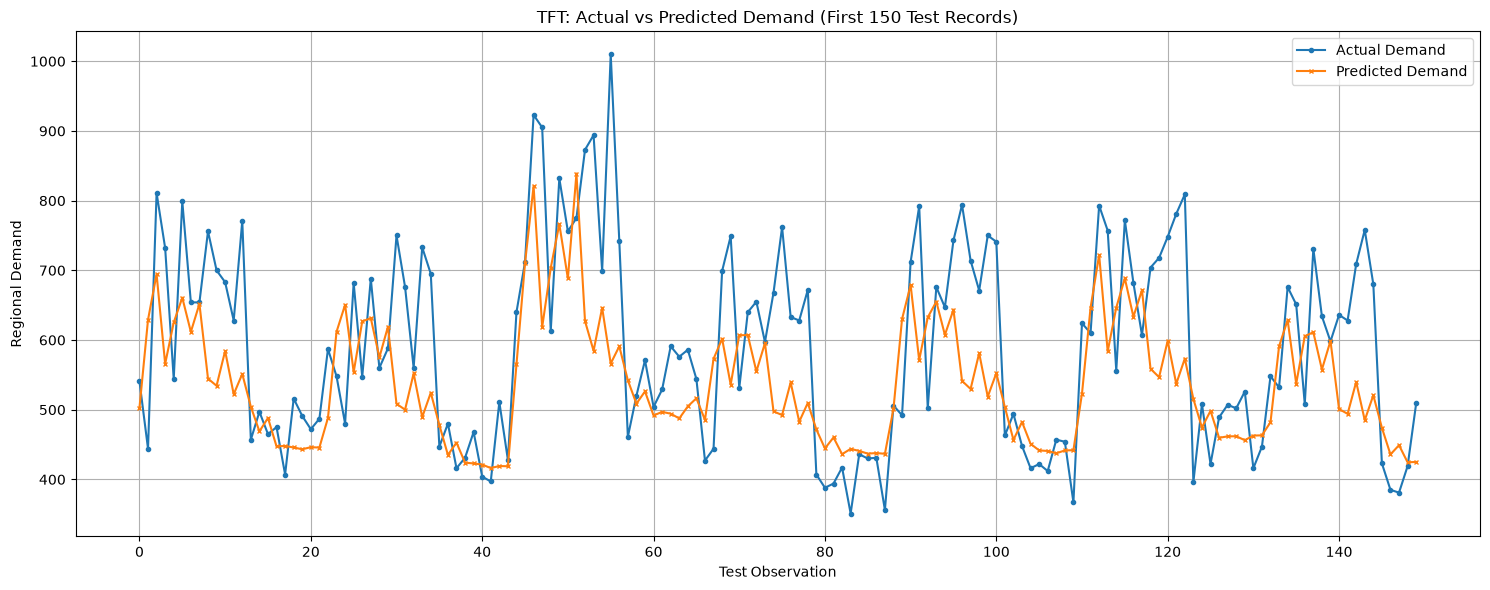

In [129]:
# STEP 9.6 - CELL 108
# VISUALIZE ACTUAL VS PREDICTED DEMAND

plt.figure(figsize=(15, 6))

plt.plot(
    y_actual[:150],
    label="Actual Demand",
    marker="o",
    markersize=3
)

plt.plot(
    y_pred[:150],
    label="Predicted Demand",
    marker="x",
    markersize=3
)

plt.title("TFT: Actual vs Predicted Demand (First 150 Test Records)")
plt.xlabel("Test Observation")
plt.ylabel("Regional Demand")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

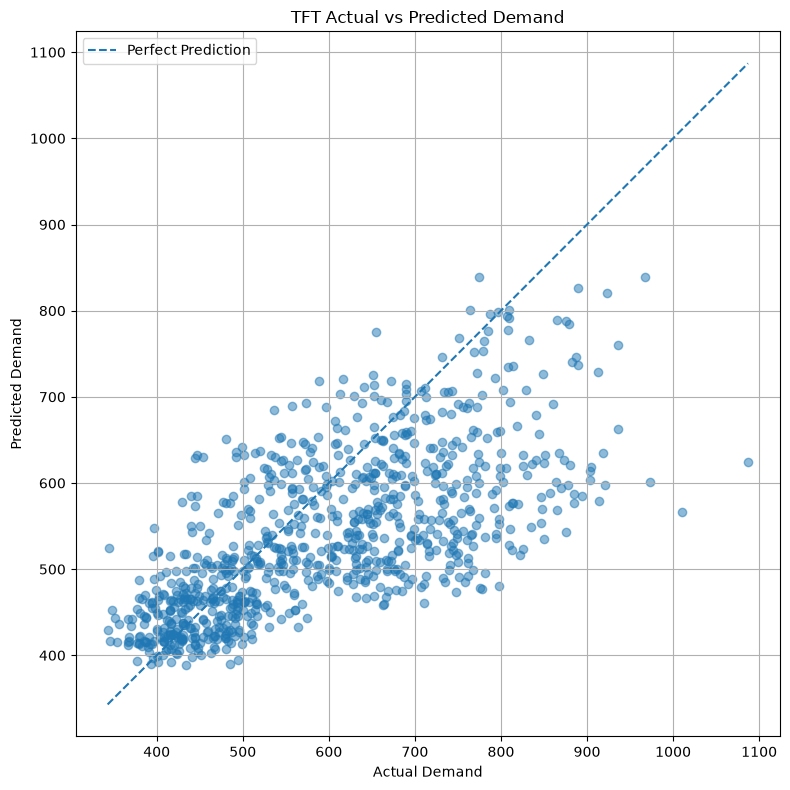

In [130]:
# STEP 9.6 - CELL 109
# ACTUAL VS PREDICTED SCATTER PLOT

plt.figure(figsize=(8, 8))

plt.scatter(
    y_actual,
    y_pred,
    alpha=0.5
)

# Ideal prediction reference line
min_value = min(y_actual.min(), y_pred.min())
max_value = max(y_actual.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("TFT Actual vs Predicted Demand")
plt.xlabel("Actual Demand")
plt.ylabel("Predicted Demand")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [132]:
# STEP 9.7 - CELL 110
# EVALUATE TFT PERFORMANCE FOR EACH REGION

# Extract decoded region names in prediction order
decoded_index = testing.decoded_index

test_region_names = decoded_index[
    "region_of_kolkata"
].values

# Check alignment
print("REGION COUNT:", len(test_region_names))
print("PREDICTION COUNT:", len(y_pred))
print("ACTUAL COUNT:", len(y_actual))

# Create comparison dataframe
region_results = pd.DataFrame({
    "Region": test_region_names,
    "Actual": y_actual,
    "Predicted": y_pred
})

# Calculate errors
region_results["Absolute_Error"] = np.abs(
    region_results["Actual"] - region_results["Predicted"]
)

region_results["Error"] = (
    region_results["Predicted"] - region_results["Actual"]
)

# Calculate region-wise metrics
region_metrics = (
    region_results.groupby("Region")
    .agg(
        Actual_Mean=("Actual", "mean"),
        Predicted_Mean=("Predicted", "mean"),
        MAE=("Absolute_Error", "mean"),
        RMSE=("Error", lambda x: np.sqrt(np.mean(x**2))),
        Average_Bias=("Error", "mean")
    )
    .reset_index()
)

region_metrics = region_metrics.sort_values(
    "MAE"
).reset_index(drop=True)

print("\nREGION-WISE TFT PERFORMANCE")
print("=" * 70)

print(region_metrics.round(2).to_string(index=False))

print("\nNUMBER OF REGIONS:", len(region_metrics))

REGION COUNT: 880
PREDICTION COUNT: 880
ACTUAL COUNT: 880

REGION-WISE TFT PERFORMANCE
      Region  Actual_Mean  Predicted_Mean    MAE   RMSE  Average_Bias
      Tangra       554.05      547.520020  58.97  79.61         -6.53
Lake Gardens       538.55      500.809998  65.71  87.87        -37.73
      Topsia       566.82      525.049988  68.03  92.88        -41.77
      Chetla       533.45      504.179993  69.24  87.97        -29.28
  Mukundapur       557.18      498.309998  75.28 100.59        -58.88
     Dum Dum       594.86      559.030029  75.53 101.72        -35.83
    Kalighat       547.36      495.179993  76.84 105.53        -52.19
  Golf Green       545.59      503.209991  78.66 101.56        -42.38
  Santoshpur       543.68      499.519989  80.85 103.62        -44.16
   Maniktala       542.45      542.799988  81.09 102.23          0.35
   Anandapur       548.91      509.959991  81.17 109.45        -38.95
  Chak Garia       552.32      502.250000  81.26 103.94        -50.06
   

In [133]:
# STEP 9.7 - CELL 111
# ANALYSE UNDERPREDICTION AND OVERPREDICTION

underpredicted_regions = (
    region_metrics["Average_Bias"] < 0
).sum()

overpredicted_regions = (
    region_metrics["Average_Bias"] > 0
).sum()

balanced_regions = (
    region_metrics["Average_Bias"] == 0
).sum()

print("REGIONAL BIAS ANALYSIS")
print("=" * 45)

print("Total regions:", len(region_metrics))
print("Underpredicted regions:", underpredicted_regions)
print("Overpredicted regions:", overpredicted_regions)
print("Exactly balanced regions:", balanced_regions)

print("\nHIGHEST UNDERPREDICTION:")
print(
    region_metrics.nsmallest(5, "Average_Bias")[
        ["Region", "Actual_Mean", "Predicted_Mean", "Average_Bias"]
    ].round(2)
)

print("\nHIGHEST OVERPREDICTION:")
print(
    region_metrics.nlargest(5, "Average_Bias")[
        ["Region", "Actual_Mean", "Predicted_Mean", "Average_Bias"]
    ].round(2)
)

REGIONAL BIAS ANALYSIS
Total regions: 40
Underpredicted regions: 39
Overpredicted regions: 1
Exactly balanced regions: 0

HIGHEST UNDERPREDICTION:
        Region  Actual_Mean  Predicted_Mean  Average_Bias
36       Garia       626.41      534.890015        -91.52
38  Ballygunge       693.45      604.359985        -89.09
32     Sealdah       571.09      489.500000        -81.60
28   Salt Lake       689.82      609.520020        -80.30
17    Sector V       677.36      599.000000        -78.36

HIGHEST OVERPREDICTION:
       Region  Actual_Mean  Predicted_Mean  Average_Bias
9   Maniktala       542.45      542.799988          0.35
0      Tangra       554.05      547.520020         -6.53
23     Behala       532.50      504.119995        -28.38
25    Entally       578.86      550.440002        -28.43
19   Rajarhat       598.36      569.890015        -28.47


In [134]:
# STEP 9.8 - CELL 112
# FINAL TFT MODEL EVALUATION SUMMARY

print("=" * 60)
print("TEMPORAL FUSION TRANSFORMER - TEST EVALUATION")
print("=" * 60)

print("\n1. DATASET INFORMATION")
print("Total test observations:", len(y_actual))
print("Total regions:", region_metrics.shape[0])
print("Forecast horizon: 1 week")

print("\n2. OVERALL TEST PERFORMANCE")
print(f"MAE:   {mae:.2f}")
print(f"RMSE:  {rmse:.2f}")
print(f"MAPE:  {mape:.2f}%")
print(f"SMAPE: {smape:.2f}%")

print("\n3. ACTUAL VS PREDICTED DEMAND")
print(f"Actual average:    {np.mean(y_actual):.2f}")
print(f"Predicted average: {np.mean(y_pred):.2f}")
print(f"Average difference: {np.mean(y_pred-y_actual):.2f}")

print("\n4. REGIONAL BIAS")
print("Underpredicted regions:", underpredicted_regions)
print("Overpredicted regions:", overpredicted_regions)

print("\n5. BEST REGION BY MAE")
print(region_metrics.iloc[0][["Region", "MAE"]])

print("\n6. WORST REGION BY MAE")
print(region_metrics.iloc[-1][["Region", "MAE"]])

print("\n" + "=" * 60)
print("EVALUATION REPORT GENERATED")
print("=" * 60)

TEMPORAL FUSION TRANSFORMER - TEST EVALUATION

1. DATASET INFORMATION
Total test observations: 880
Total regions: 40
Forecast horizon: 1 week

2. OVERALL TEST PERFORMANCE
MAE:   87.57
RMSE:  116.88
MAPE:  13.72%
SMAPE: 14.68%

3. ACTUAL VS PREDICTED DEMAND
Actual average:    592.13
Predicted average: 538.33
Average difference: -53.81

4. REGIONAL BIAS
Underpredicted regions: 39
Overpredicted regions: 1

5. BEST REGION BY MAE
Region       Tangra
MAE       58.973099
Name: 0, dtype: object

6. WORST REGION BY MAE
Region     Esplanade
MAE       114.026122
Name: 39, dtype: object

EVALUATION REPORT GENERATED


In [135]:
# STEP 10.1 - CELL 113
# COMPARE TRAINING, VALIDATION AND TEST DEMAND

demand_comparison = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Mean_Demand": [
        train_df["regional_demand"].mean(),
        validation_df["regional_demand"].mean(),
        test_df["regional_demand"].mean()
    ],
    "Median_Demand": [
        train_df["regional_demand"].median(),
        validation_df["regional_demand"].median(),
        test_df["regional_demand"].median()
    ],
    "Minimum_Demand": [
        train_df["regional_demand"].min(),
        validation_df["regional_demand"].min(),
        test_df["regional_demand"].min()
    ],
    "Maximum_Demand": [
        train_df["regional_demand"].max(),
        validation_df["regional_demand"].max(),
        test_df["regional_demand"].max()
    ],
    "Standard_Deviation": [
        train_df["regional_demand"].std(),
        validation_df["regional_demand"].std(),
        test_df["regional_demand"].std()
    ]
})

print("DEMAND DISTRIBUTION COMPARISON")
print("=" * 70)

print(demand_comparison.round(2).to_string(index=False))

DEMAND DISTRIBUTION COMPARISON
   Dataset  Mean_Demand  Median_Demand  Minimum_Demand  Maximum_Demand  Standard_Deviation
  Training       604.88          557.0             312            1320              163.67
Validation       542.20          513.5             340            1069              122.72
   Testing       592.13          579.5             343            1087              142.41


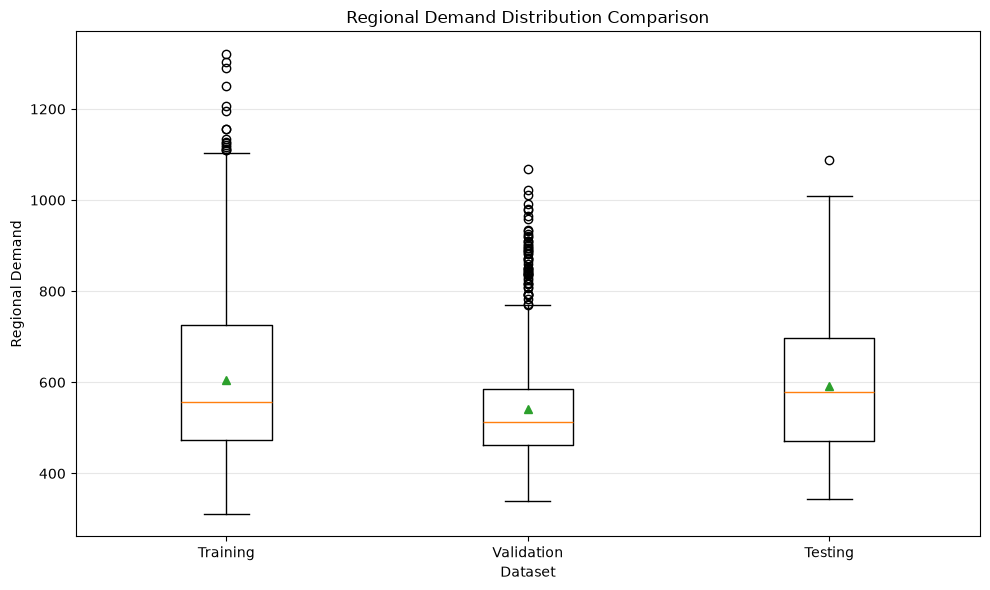

In [136]:
# STEP 10.1 - CELL 114
# VISUALIZE TRAINING, VALIDATION AND TEST DEMAND

plt.figure(figsize=(10, 6))

plt.boxplot(
    [
        train_df["regional_demand"],
        validation_df["regional_demand"],
        test_df["regional_demand"]
    ],
    tick_labels=["Training", "Validation", "Testing"],
    showmeans=True
)

plt.title("Regional Demand Distribution Comparison")
plt.xlabel("Dataset")
plt.ylabel("Regional Demand")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [137]:
# STEP 10.1 - CELL 115
# CHECK UNDERPREDICTION AT DIFFERENT DEMAND LEVELS

error_analysis = pd.DataFrame({
    "Actual": y_actual,
    "Predicted": y_pred
})

# Divide actual demand into four equal-sized groups
error_analysis["Demand_Level"] = pd.qcut(
    error_analysis["Actual"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"]
)

# Calculate prediction errors
error_analysis["Error"] = (
    error_analysis["Predicted"] -
    error_analysis["Actual"]
)

error_analysis["Absolute_Error"] = np.abs(
    error_analysis["Error"]
)

# Summarize each demand group
demand_level_analysis = (
    error_analysis.groupby("Demand_Level", observed=False)
    .agg(
        Observation_Count=("Actual", "count"),
        Actual_Mean=("Actual", "mean"),
        Predicted_Mean=("Predicted", "mean"),
        Average_Bias=("Error", "mean"),
        MAE=("Absolute_Error", "mean")
    )
    .reset_index()
)

print("DEMAND LEVEL VS PREDICTION ERROR")
print("=" * 75)

print(demand_level_analysis.round(2).to_string(index=False))

DEMAND LEVEL VS PREDICTION ERROR
Demand_Level  Observation_Count  Actual_Mean  Predicted_Mean  Average_Bias    MAE
         Low                220       421.85      452.290009         30.44  42.47
      Medium                220       519.57      514.200012         -5.37  50.99
        High                221       643.06      572.789978        -70.27  85.43
   Very High                219       784.70      614.229980       -170.48 171.78


In [138]:
# STEP 10.1 - CELL 116
# CHECK TFT PREDICTION CALIBRATION

# Correlation between actual and predicted demand
correlation = np.corrcoef(y_actual, y_pred)[0, 1]

# Calibration line: Actual = slope * Predicted + intercept
slope, intercept = np.polyfit(
    y_pred,
    y_actual,
    1
)

print("TFT PREDICTION CALIBRATION")
print("=" * 50)

print(f"Correlation: {correlation:.4f}")
print(f"Calibration slope: {slope:.4f}")
print(f"Calibration intercept: {intercept:.2f}")

print("\nINTERPRETATION")

if slope > 1:
    print("Predictions may be too compressed.")
elif slope < 1:
    print("Predictions may be too spread out.")
else:
    print("Calibration slope is close to 1.")

print("\nIdeal calibration:")
print("Correlation close to 1")
print("Slope close to 1")
print("Intercept close to 0")

TFT PREDICTION CALIBRATION
Correlation: 0.6857
Calibration slope: 1.0621
Calibration intercept: 20.39

INTERPRETATION
Predictions may be too compressed.

Ideal calibration:
Correlation close to 1
Slope close to 1
Intercept close to 0


In [139]:
# STEP 10.1 - CELL 117
# COMPARE ACTUAL AND PREDICTED VARIABILITY

variability_comparison = pd.DataFrame({
    "Metric": [
        "Mean",
        "Standard Deviation",
        "Minimum",
        "Maximum",
        "Range"
    ],
    "Actual": [
        np.mean(y_actual),
        np.std(y_actual),
        np.min(y_actual),
        np.max(y_actual),
        np.max(y_actual) - np.min(y_actual)
    ],
    "Predicted": [
        np.mean(y_pred),
        np.std(y_pred),
        np.min(y_pred),
        np.max(y_pred),
        np.max(y_pred) - np.min(y_pred)
    ]
})

print("ACTUAL VS PREDICTED VARIABILITY")
print("=" * 65)

print(variability_comparison.round(2).to_string(index=False))

print("\nVARIABILITY RATIO:")
print(
    "Predicted / Actual:",
    round(np.std(y_pred) / np.std(y_actual), 4)
)

ACTUAL VS PREDICTED VARIABILITY
            Metric  Actual  Predicted
              Mean  592.13 538.330017
Standard Deviation  142.33  91.889999
           Minimum  343.00 388.260010
           Maximum 1087.00 838.929993
             Range  744.00 450.670013

VARIABILITY RATIO:
Predicted / Actual: 0.6456


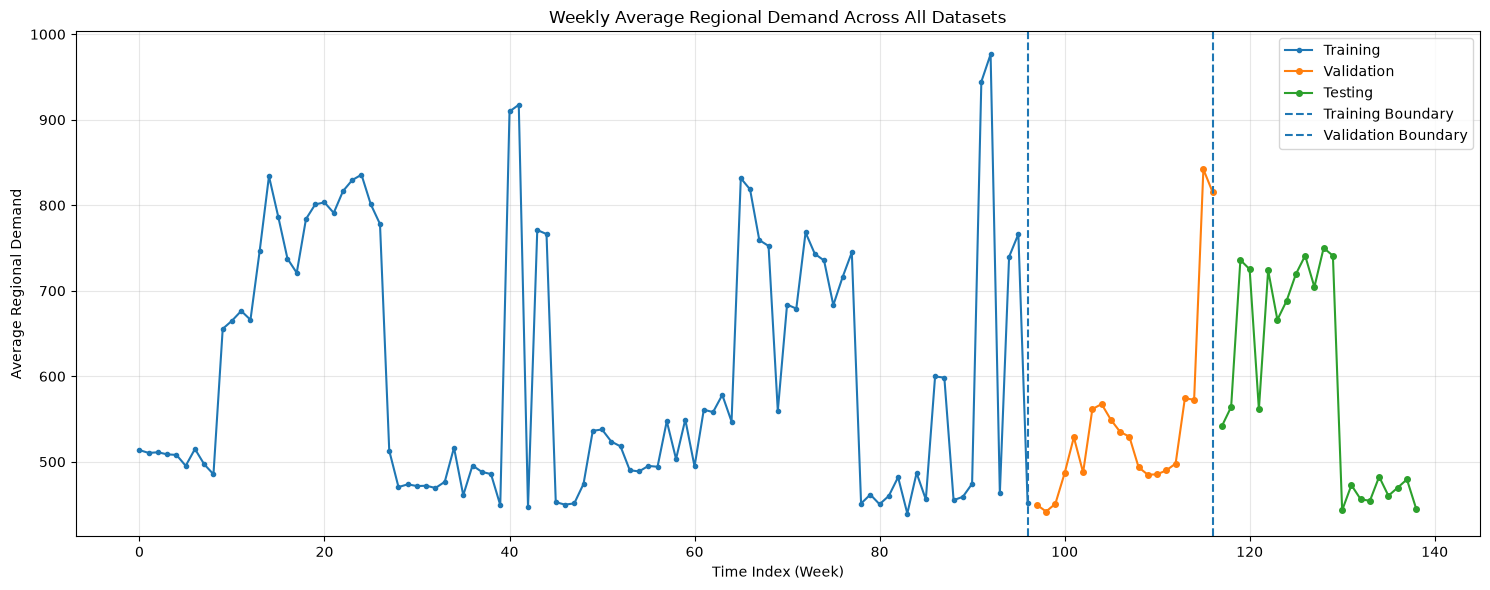

In [140]:
# STEP 10.2 - CELL 118
# COMPARE WEEKLY DEMAND TRENDS

train_trend = (
    train_df.groupby("time_idx")["regional_demand"]
    .mean()
)

validation_trend = (
    validation_df.groupby("time_idx")["regional_demand"]
    .mean()
)

test_trend = (
    test_df.groupby("time_idx")["regional_demand"]
    .mean()
)

plt.figure(figsize=(15, 6))

plt.plot(
    train_trend.index,
    train_trend.values,
    label="Training",
    marker="o",
    markersize=3
)

plt.plot(
    validation_trend.index,
    validation_trend.values,
    label="Validation",
    marker="o",
    markersize=4
)

plt.plot(
    test_trend.index,
    test_trend.values,
    label="Testing",
    marker="o",
    markersize=4
)

plt.axvline(
    x=96,
    linestyle="--",
    label="Training Boundary"
)

plt.axvline(
    x=116,
    linestyle="--",
    label="Validation Boundary"
)

plt.title("Weekly Average Regional Demand Across All Datasets")
plt.xlabel("Time Index (Week)")
plt.ylabel("Average Regional Demand")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [141]:
# STEP 10.2 - CELL 119
# INSPECT TEST PREDICTION TIME INDEX

test_index = testing.decoded_index.copy()

print("TEST INDEX COLUMNS:")
print(test_index.columns.tolist())

print("\nFIRST 10 TEST INDEX RECORDS:")
print(test_index.head(10))

print("\nTOTAL TEST INDEX RECORDS:")
print(len(test_index))

TEST INDEX COLUMNS:
['region_of_kolkata', 'time_idx_first', 'time_idx_last', 'time_idx_first_prediction']

FIRST 10 TEST INDEX RECORDS:
  region_of_kolkata  time_idx_first  time_idx_last  time_idx_first_prediction
0           Alipore              91            117                        117
1           Alipore              92            118                        118
2           Alipore              93            119                        119
3           Alipore              94            120                        120
4           Alipore              95            121                        121
5           Alipore              96            122                        122
6           Alipore              97            123                        123
7           Alipore              98            124                        124
8           Alipore              99            125                        125
9           Alipore             100            126                        126

TOTAL

In [142]:
# STEP 10.2 - CELL 120
# ALIGN ACTUAL AND PREDICTED VALUES BY FORECAST WEEK

weekly_comparison = pd.DataFrame({
    "Region": test_index["region_of_kolkata"].values,
    "time_idx": test_index["time_idx_first_prediction"].values,
    "Actual_Demand": y_actual,
    "Predicted_Demand": y_pred
})

# Calculate weekly average across all 40 regions
weekly_prediction_summary = (
    weekly_comparison
    .groupby("time_idx")
    .agg(
        Actual_Mean=("Actual_Demand", "mean"),
        Predicted_Mean=("Predicted_Demand", "mean")
    )
    .reset_index()
)

weekly_prediction_summary["Bias"] = (
    weekly_prediction_summary["Predicted_Mean"] -
    weekly_prediction_summary["Actual_Mean"]
)

print("WEEKLY ACTUAL VS PREDICTED DEMAND")
print("=" * 75)

print(weekly_prediction_summary.round(2).to_string(index=False))

print("\nTOTAL FORECAST WEEKS:")
print(len(weekly_prediction_summary))

print("\nREGION-WEEK RECORDS:")
print(len(weekly_comparison))

WEEKLY ACTUAL VS PREDICTED DEMAND
 time_idx  Actual_Mean  Predicted_Mean    Bias
      117       541.75      506.760010  -34.99
      118       564.12      628.840027   64.72
      119       735.98      696.880005  -39.09
      120       725.20      568.429993 -156.77
      121       561.40      634.340027   72.94
      122       723.95      667.539978  -56.41
      123       666.10      610.119995  -55.98
      124       688.38      655.869995  -32.51
      125       719.55      542.049988 -177.50
      126       741.08      530.640015 -210.44
      127       704.45      580.510010 -123.94
      128       750.10      518.679993 -231.42
      129       741.08      550.340027 -190.74
      130       443.28      503.339996   60.07
      131       472.72      462.720001  -10.00
      132       456.22      483.299988   27.08
      133       454.38      450.429993   -3.94
      134       482.58      451.380005  -31.19
      135       460.30      448.989990  -11.31
      136       469.75    

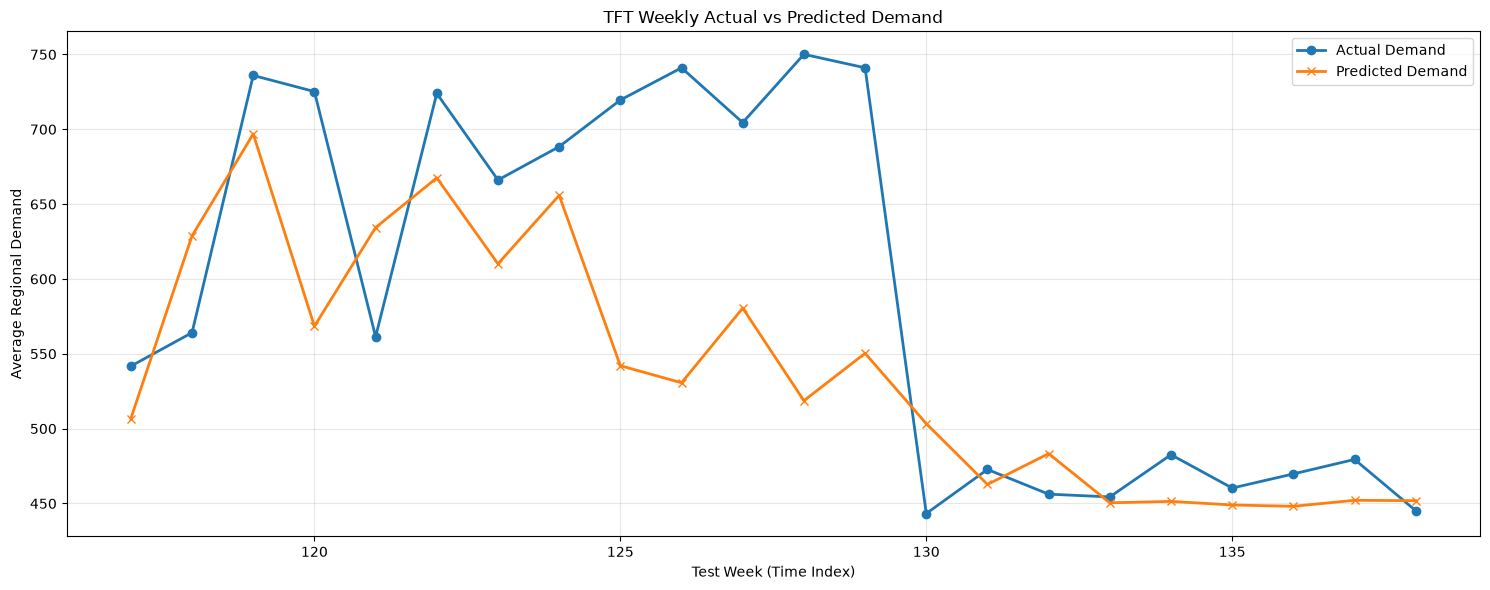

In [143]:
# STEP 10.2 - CELL 121
# VISUALIZE WEEKLY ACTUAL VS PREDICTED DEMAND

plt.figure(figsize=(15, 6))

plt.plot(
    weekly_prediction_summary["time_idx"],
    weekly_prediction_summary["Actual_Mean"],
    marker="o",
    linewidth=2,
    label="Actual Demand"
)

plt.plot(
    weekly_prediction_summary["time_idx"],
    weekly_prediction_summary["Predicted_Mean"],
    marker="x",
    linewidth=2,
    label="Predicted Demand"
)

plt.title("TFT Weekly Actual vs Predicted Demand")
plt.xlabel("Test Week (Time Index)")
plt.ylabel("Average Regional Demand")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [144]:
# STEP 10.2 - CELL 122
# INVESTIGATE FEATURES ASSOCIATED WITH TEST DEMAND

weekly_feature_analysis = (
    test_df.groupby("time_idx")
    .agg(
        Week_Start=("week_start_date", "first"),
        Actual_Demand=("regional_demand", "mean"),
        Holiday_Rate=("holiday_flag", "mean"),
        Promotion_Rate=("promotion_rate", "mean"),
        Average_Discount=("average_discount_pct", "mean"),
        Temperature=("temperature_c", "mean"),
        Rainfall=("rainfall_mm", "mean"),
        Humidity=("humidity_pct", "mean"),
        Stockout_Rate=("stockout_rate", "mean"),
        Festival=("festival_event", "first"),
        Season=("season", "first")
    )
    .reset_index()
)

print("WEEKLY DEMAND DRIVER ANALYSIS")
print("=" * 110)

print(
    weekly_feature_analysis.round(2).to_string(index=False)
)

print("\nTOTAL WEEKS ANALYSED:")
print(len(weekly_feature_analysis))

WEEKLY DEMAND DRIVER ANALYSIS
 time_idx Week_Start  Actual_Demand  Holiday_Rate  Promotion_Rate  Average_Discount  Temperature  Rainfall  Humidity  Stockout_Rate                          Festival  Season
      117 2026-03-29         541.75           0.0            0.13              1.30         27.0      14.6      63.7           0.04                       No Festival  Spring
      118 2026-04-05         564.12           0.0            0.18              2.10         29.2      18.9      59.3           0.02                       No Festival  Spring
      119 2026-04-12         735.98           1.0            0.19              2.28         27.8      14.6      61.0           0.02 Poila Boishakh / Bengali New Year  Spring
      120 2026-04-19         725.20           0.0            0.24              2.47         25.9       8.4      72.1           0.02                       No Festival  Spring
      121 2026-04-26         561.40           0.0            0.16              1.72         30.2    

In [145]:
# STEP 10.2 - CELL 123
# CHECK CORRELATION BETWEEN DEMAND AND FEATURES

correlation_columns = [
    "Actual_Demand",
    "Holiday_Rate",
    "Promotion_Rate",
    "Average_Discount",
    "Temperature",
    "Rainfall",
    "Humidity",
    "Stockout_Rate"
]

correlation_matrix = weekly_feature_analysis[
    correlation_columns
].corr(method="pearson")

print("WEEKLY DEMAND FEATURE CORRELATION")
print("=" * 65)

print(
    correlation_matrix["Actual_Demand"]
    .sort_values(ascending=False)
    .round(3)
    .to_string()
)

print("\nCORRELATION MATRIX:")
print(correlation_matrix.round(3))

WEEKLY DEMAND FEATURE CORRELATION
Actual_Demand       1.000
Average_Discount    0.441
Promotion_Rate      0.422
Temperature         0.404
Stockout_Rate       0.049
Holiday_Rate        0.010
Rainfall           -0.617
Humidity           -0.747

CORRELATION MATRIX:
                  Actual_Demand  Holiday_Rate  Promotion_Rate  Average_Discount  Temperature  Rainfall  Humidity  Stockout_Rate
Actual_Demand             1.000         0.010           0.422             0.441        0.404    -0.617    -0.747          0.049
Holiday_Rate              0.010         1.000           0.071             0.096       -0.282    -0.124     0.051         -0.249
Promotion_Rate            0.422         0.071           1.000             0.928       -0.009    -0.305    -0.326         -0.079
Average_Discount          0.441         0.096           0.928             1.000        0.180    -0.324    -0.289         -0.147
Temperature               0.404        -0.282          -0.009             0.180        1.000    -

In [146]:
# STEP 10.2 - CELL 124
# CHECK WHICH FEATURES ARE ASSOCIATED WITH PREDICTION BIAS

bias_feature_analysis = weekly_feature_analysis.merge(
    weekly_prediction_summary[["time_idx", "Bias"]],
    on="time_idx",
    how="inner"
)

bias_correlation_columns = [
    "Bias",
    "Promotion_Rate",
    "Average_Discount",
    "Temperature",
    "Rainfall",
    "Humidity",
    "Holiday_Rate",
    "Stockout_Rate"
]

bias_correlations = bias_feature_analysis[
    bias_correlation_columns
].corr()["Bias"].sort_values(ascending=False)

print("PREDICTION BIAS VS FEATURE CORRELATION")
print("=" * 65)

print(bias_correlations.round(3).to_string())

print("\nINTERPRETATION:")
print("Negative bias = Underprediction")
print("Positive bias = Overprediction")

PREDICTION BIAS VS FEATURE CORRELATION
Bias                1.000
Humidity            0.405
Rainfall            0.294
Holiday_Rate        0.173
Stockout_Rate      -0.033
Promotion_Rate     -0.336
Average_Discount   -0.411
Temperature        -0.508

INTERPRETATION:
Negative bias = Underprediction
Positive bias = Overprediction


In [147]:
# STEP 10.2 - CELL 125
# IDENTIFY WEEKS WITH THE LARGEST FORECAST ERRORS

worst_weeks = weekly_feature_analysis.merge(
    weekly_prediction_summary[
        ["time_idx", "Predicted_Mean", "Bias"]
    ],
    on="time_idx",
    how="inner"
)

# Calculate the absolute prediction bias
worst_weeks["Absolute_Bias"] = np.abs(
    worst_weeks["Bias"]
)

# Sort weeks from largest error to smallest
worst_weeks = worst_weeks.sort_values(
    "Absolute_Bias",
    ascending=False
)

# Select the columns to display
columns_to_display = [
    "time_idx",
    "Actual_Demand",
    "Predicted_Mean",
    "Bias",
    "Temperature",
    "Rainfall",
    "Humidity",
    "Promotion_Rate",
    "Average_Discount",
    "Season"
]

print("10 WEEKS WITH THE LARGEST FORECAST ERRORS")
print("=" * 110)

print(
    worst_weeks[columns_to_display]
    .head(10)
    .round(2)
    .to_string(index=False)
)

10 WEEKS WITH THE LARGEST FORECAST ERRORS
 time_idx  Actual_Demand  Predicted_Mean    Bias  Temperature  Rainfall  Humidity  Promotion_Rate  Average_Discount Season
      128         750.10      518.679993 -231.42         36.1       9.9      74.5            0.16              2.06 Summer
      126         741.08      530.640015 -210.44         35.5      13.0      74.0            0.18              2.16 Summer
      129         741.08      550.340027 -190.74         37.0      15.8      60.0            0.16              2.08 Summer
      125         719.55      542.049988 -177.50         33.2      16.0      59.1            0.19              2.33 Summer
      120         725.20      568.429993 -156.77         25.9       8.4      72.1            0.24              2.47 Spring
      127         704.45      580.510010 -123.94         33.8      15.4      59.5            0.18              2.04 Summer
      121         561.40      634.340027   72.94         30.2      23.2      77.4            0.16

In [148]:
# STEP 10.3 - CELL 126
# COMPARE TFT WITH SIMPLE BASELINE MODELS

# Create a copy of the test prediction results
baseline_comparison = weekly_comparison.copy()

# Prepare previous week's actual demand
previous_week = model_df[
    ["region_of_kolkata", "time_idx", "regional_demand"]
].copy()

previous_week["time_idx"] += 1

previous_week = previous_week.rename(
    columns={
        "region_of_kolkata": "Region",
        "regional_demand": "Naive_Prediction"
    }
)

# Prepare demand from four weeks earlier
four_week_previous = model_df[
    ["region_of_kolkata", "time_idx", "regional_demand"]
].copy()

four_week_previous["time_idx"] += 4

four_week_previous = four_week_previous.rename(
    columns={
        "region_of_kolkata": "Region",
        "regional_demand": "Seasonal_Naive_Prediction"
    }
)

# Merge both baseline predictions
baseline_comparison = baseline_comparison.merge(
    previous_week,
    on=["Region", "time_idx"],
    how="left",
    validate="one_to_one"
)

baseline_comparison = baseline_comparison.merge(
    four_week_previous,
    on=["Region", "time_idx"],
    how="left",
    validate="one_to_one"
)

# Calculate evaluation metrics
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))
    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    return mae, rmse, mape

# Compare all three models
models = {
    "TFT": baseline_comparison["Predicted_Demand"],
    "Naive": baseline_comparison["Naive_Prediction"],
    "Seasonal Naive (4 weeks)": baseline_comparison[
        "Seasonal_Naive_Prediction"
    ]
}

results = []

for model_name, predictions in models.items():

    mae, rmse, mape = calculate_metrics(
        baseline_comparison["Actual_Demand"],
        predictions
    )

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE_Percent": mape
    })

baseline_results = pd.DataFrame(results)

print("BASELINE MODEL COMPARISON")
print("=" * 75)

print(
    baseline_results
    .round(2)
    .to_string(index=False)
)

BASELINE MODEL COMPARISON
                   Model    MAE   RMSE  MAPE_Percent
                     TFT  87.57 116.88         13.72
                   Naive  96.62 132.64         17.09
Seasonal Naive (4 weeks) 115.97 154.37         21.78


In [149]:
# STEP 10.4 - CELL 127
# CHECK LAG AND ROLLING FEATURES

history_features = [
    "lag_1",
    "lag_2",
    "lag_4",
    "lag_8",
    "rolling_mean_4",
    "rolling_mean_8",
    "rolling_std_4"
]

print("LAG AND ROLLING FEATURE SUMMARY")
print("=" * 75)

print(
    model_df[history_features]
    .describe()
    .round(2)
)

print("\nMISSING VALUES IN HISTORY FEATURES")
print("=" * 75)

print(
    model_df[history_features]
    .isnull()
    .sum()
)

print("\nFEATURE AVAILABILITY IN TRAINING DATA")
print("=" * 75)

print(
    train_df[history_features]
    .isnull()
    .sum()
)

LAG AND ROLLING FEATURE SUMMARY
         lag_1    lag_2    lag_4    lag_8  rolling_mean_4  rolling_mean_8  rolling_std_4
count  5520.00  5480.00  5400.00  5240.00         5400.00         5240.00        5400.00
mean    594.92   595.76   597.70   601.71          597.20          600.53          87.44
std     156.60   156.76   156.94   157.27          124.32          107.04          68.93
min     312.00   312.00   312.00   312.00          383.50          392.75           0.96
25%     472.00   472.00   474.00   476.75          491.12          509.97          38.19
50%     551.00   552.00   555.00   560.00          576.38          591.88          62.62
75%     704.00   705.00   707.00   713.00          688.12          672.00         120.05
max    1320.00  1320.00  1320.00  1320.00          983.75          962.50         391.38

MISSING VALUES IN HISTORY FEATURES
lag_1              40
lag_2              80
lag_4             160
lag_8             320
rolling_mean_4    160
rolling_mean_8    320

In [151]:
# STEP 10.4 - CELL 128
# CHECK HISTORICAL FEATURE AVAILABILITY

history_features = [
    "lag_1",
    "lag_2",
    "lag_4",
    "lag_8",
    "rolling_mean_4",
    "rolling_mean_8",
    "rolling_std_4"
]

# Use the correct dataframe variable names
datasets = {
    "Training": train_df,
    "Validation": validation_df,
    "Testing": test_df
}

availability_results = []

for dataset_name, dataset in datasets.items():

    for feature in history_features:

        availability_results.append({
            "Dataset": dataset_name,
            "Feature": feature,
            "Total_Rows": len(dataset),
            "Missing_Values": dataset[feature].isnull().sum(),
            "Available_Values": dataset[feature].notnull().sum()
        })

availability_df = pd.DataFrame(availability_results)

print("HISTORICAL FEATURE AVAILABILITY")
print("=" * 85)

print(availability_df.to_string(index=False))

HISTORICAL FEATURE AVAILABILITY
   Dataset        Feature  Total_Rows  Missing_Values  Available_Values
  Training          lag_1        3880              40              3840
  Training          lag_2        3880              80              3800
  Training          lag_4        3880             160              3720
  Training          lag_8        3880             320              3560
  Training rolling_mean_4        3880             160              3720
  Training rolling_mean_8        3880             320              3560
  Training  rolling_std_4        3880             160              3720
Validation          lag_1         800               0               800
Validation          lag_2         800               0               800
Validation          lag_4         800               0               800
Validation          lag_8         800               0               800
Validation rolling_mean_4         800               0               800
Validation rolling_mean_8       

In [152]:
# STEP 10.4 - CELL 129
# PREPARE IMPROVED TFT FEATURE CONFIGURATION

# Copy the original feature configuration
improved_known_reals = known_reals.copy()
improved_unknown_reals = unknown_reals.copy()

# Add historical demand features
history_features = [
    "lag_1",
    "lag_2",
    "lag_4",
    "lag_8",
    "rolling_mean_4",
    "rolling_mean_8",
    "rolling_std_4"
]

for feature in history_features:
    if feature not in improved_unknown_reals:
        improved_unknown_reals.append(feature)

# Display the improved configuration
print("IMPROVED TFT FEATURE CONFIGURATION")
print("=" * 70)

print("\nKnown numerical features:")
print(improved_known_reals)

print("\nUnknown numerical features:")
print(improved_unknown_reals)

print("\nTotal known numerical features:",
      len(improved_known_reals))

print("Total unknown numerical features:",
      len(improved_unknown_reals))

print("\nNew historical features added:",
      len(history_features))

IMPROVED TFT FEATURE CONFIGURATION

Known numerical features:
['time_idx', 'month', 'quarter', 'day_of_year', 'month_sin', 'month_cos', 'year_sin', 'year_cos', 'holiday_flag']

Unknown numerical features:
['regional_demand', 'temperature_c', 'rainfall_mm', 'humidity_pct', 'promotion_product_count', 'promotion_rate', 'average_discount_pct', 'average_selling_price_rs', 'stockout_product_count', 'stockout_rate', 'lag_1', 'lag_2', 'lag_4', 'lag_8', 'rolling_mean_4', 'rolling_mean_8', 'rolling_std_4']

Total known numerical features: 9
Total unknown numerical features: 17

New historical features added: 7


In [153]:
# STEP 10.4 - CELL 130
# VALIDATE IMPROVED TFT FEATURES

improved_features = (
    improved_known_reals
    + improved_unknown_reals
    + known_categoricals
    + unknown_categoricals
)

# Check whether all selected features exist
missing_columns = [
    col for col in improved_features
    if col not in model_df.columns
]

print("IMPROVED FEATURE VALIDATION")
print("=" * 70)

print("Total selected features:", len(improved_features))
print("Missing columns:", missing_columns)

# Check missing values in validation and testing
print("\nVALIDATION MISSING VALUES")
print(
    validation_df[improved_features]
    .isnull()
    .sum()
)

print("\nTESTING MISSING VALUES")
print(
    test_df[improved_features]
    .isnull()
    .sum()
)

# Check duplicate feature names
print("\nDuplicate feature names:",
      len(improved_features) - len(set(improved_features)))

# Final validation result
if (
    len(missing_columns) == 0
    and validation_df[improved_features].isnull().sum().sum() == 0
    and test_df[improved_features].isnull().sum().sum() == 0
    and len(improved_features) == len(set(improved_features))
):
    print("\nSUCCESS: Improved features passed validation.")
else:
    print("\nWARNING: Please investigate the validation results.")

IMPROVED FEATURE VALIDATION
Total selected features: 29
Missing columns: []

VALIDATION MISSING VALUES
time_idx                    0
month                       0
quarter                     0
day_of_year                 0
month_sin                   0
month_cos                   0
year_sin                    0
year_cos                    0
holiday_flag                0
regional_demand             0
temperature_c               0
rainfall_mm                 0
humidity_pct                0
promotion_product_count     0
promotion_rate              0
average_discount_pct        0
average_selling_price_rs    0
stockout_product_count      0
stockout_rate               0
lag_1                       0
lag_2                       0
lag_4                       0
lag_8                       0
rolling_mean_4              0
rolling_mean_8              0
rolling_std_4               0
festival_event              0
season                      0
weather_condition           0
dtype: int64

TESTING MISSI

In [156]:
# STEP 10.4 - CELL 131
# HANDLE MISSING HISTORY FEATURES AND CREATE TFT DATASET

from pytorch_forecasting import TimeSeriesDataSet
from pytorch_forecasting.data import GroupNormalizer, NaNLabelEncoder

# Define sequence lengths
encoder_length = 26
prediction_length = 1

# Historical features
history_features = [
    "lag_1",
    "lag_2",
    "lag_4",
    "lag_8",
    "rolling_mean_4",
    "rolling_mean_8",
    "rolling_std_4"
]

# Keep only rows where all historical features are available
improved_train_df = train_df.dropna(
    subset=history_features
).copy()

# Sort the data correctly
improved_train_df = improved_train_df.sort_values(
    ["region_of_kolkata", "time_idx"]
).reset_index(drop=True)

# Create improved TFT training dataset
improved_training = TimeSeriesDataSet(
    improved_train_df,
    time_idx="time_idx",
    target=target,
    group_ids=group_ids,

    min_encoder_length=encoder_length,
    max_encoder_length=encoder_length,

    min_prediction_length=prediction_length,
    max_prediction_length=prediction_length,

    static_categoricals=static_categoricals,

    time_varying_known_reals=improved_known_reals,
    time_varying_unknown_reals=improved_unknown_reals,

    time_varying_known_categoricals=known_categoricals,
    time_varying_unknown_categoricals=unknown_categoricals,

    target_normalizer=GroupNormalizer(
        groups=group_ids
    ),

    categorical_encoders={
        "region_of_kolkata": NaNLabelEncoder(add_nan=True),
        "festival_event": NaNLabelEncoder(add_nan=True),
        "season": NaNLabelEncoder(add_nan=True),
        "weather_condition": NaNLabelEncoder(add_nan=True)
    },

    add_relative_time_idx=True,
    add_target_scales=True,
    add_encoder_length=True
)

# Display results
print("IMPROVED TFT TRAINING DATASET CREATED")
print("=" * 70)

print("Original training rows:", len(train_df))
print("Rows after removing missing history:", len(improved_train_df))
print("Rows removed:", len(train_df) - len(improved_train_df))

print("Number of regions:",
      improved_train_df["region_of_kolkata"].nunique())

print("Training sequences:", len(improved_training))
print("Encoder length:", encoder_length)
print("Prediction length:", prediction_length)

print("\nMissing historical values:")
print(improved_train_df[history_features].isnull().sum())

IMPROVED TFT TRAINING DATASET CREATED
Original training rows: 3880
Rows after removing missing history: 3560
Rows removed: 320
Number of regions: 40
Training sequences: 2520
Encoder length: 26
Prediction length: 1

Missing historical values:
lag_1             0
lag_2             0
lag_4             0
lag_8             0
rolling_mean_4    0
rolling_mean_8    0
rolling_std_4     0
dtype: int64


In [157]:
# STEP 10.4 - CELL 132
# CREATE IMPROVED TFT VALIDATION DATASET

# Include training and validation history up to week 116
improved_validation_data = model_df[
    model_df["time_idx"] <= 116
].copy()

# Create validation dataset using improved training configuration
improved_validation = TimeSeriesDataSet.from_dataset(
    improved_training,
    improved_validation_data,
    min_prediction_idx=97,
    stop_randomization=True
)

print("IMPROVED TFT VALIDATION DATASET CREATED")
print("=" * 70)

print("Validation sequences:", len(improved_validation))
print("Validation period: weeks 97 to 116")
print("Number of regions:",
      improved_validation_data["region_of_kolkata"].nunique())

print("Missing historical features:")
print(
    improved_validation_data[
        history_features
    ].isnull().sum()
)

IMPROVED TFT VALIDATION DATASET CREATED
Validation sequences: 800
Validation period: weeks 97 to 116
Number of regions: 40
Missing historical features:
lag_1              40
lag_2              80
lag_4             160
lag_8             320
rolling_mean_4    160
rolling_mean_8    320
rolling_std_4     160
dtype: int64


In [158]:
# STEP 10.4 - CELL 133
# CREATE IMPROVED TFT TESTING DATASET

# Include historical data up to the final test week
improved_test_data = model_df[
    model_df["time_idx"] <= 138
].copy()

# Create testing dataset from improved training configuration
improved_testing = TimeSeriesDataSet.from_dataset(
    improved_training,
    improved_test_data,
    min_prediction_idx=117,
    stop_randomization=True
)

print("IMPROVED TFT TESTING DATASET CREATED")
print("=" * 70)

print("Testing sequences:", len(improved_testing))
print("Testing period: weeks 117 to 138")
print("Number of regions:",
      improved_test_data["region_of_kolkata"].nunique())

print("Missing historical features in test prediction rows:")

test_prediction_rows = improved_test_data[
    improved_test_data["time_idx"] >= 117
]

print(
    test_prediction_rows[history_features].isnull().sum()
)

IMPROVED TFT TESTING DATASET CREATED
Testing sequences: 880
Testing period: weeks 117 to 138
Number of regions: 40
Missing historical features in test prediction rows:
lag_1             0
lag_2             0
lag_4             0
lag_8             0
rolling_mean_4    0
rolling_mean_8    0
rolling_std_4     0
dtype: int64


In [159]:
# STEP 10.4 - CELL 134
# CREATE IMPROVED TFT DATALOADERS

batch_size = 64

# Training DataLoader
improved_train_dataloader = improved_training.to_dataloader(
    train=True,
    batch_size=batch_size,
    num_workers=0
)

# Validation DataLoader
improved_val_dataloader = improved_validation.to_dataloader(
    train=False,
    batch_size=batch_size,
    num_workers=0
)

# Testing DataLoader
improved_test_dataloader = improved_testing.to_dataloader(
    train=False,
    batch_size=batch_size,
    num_workers=0
)

print("IMPROVED TFT DATALOADERS CREATED")
print("=" * 65)

print("Training batches:", len(improved_train_dataloader))
print("Validation batches:", len(improved_val_dataloader))
print("Testing batches:", len(improved_test_dataloader))

print("Batch size:", batch_size)
print("Workers: 0")

IMPROVED TFT DATALOADERS CREATED
Training batches: 39
Validation batches: 13
Testing batches: 14
Batch size: 64
Workers: 0


In [160]:
# STEP 10.4 - CELL 135
# CREATE IMPROVED TFT MODEL

improved_tft = TemporalFusionTransformer.from_dataset(
    improved_training,

    learning_rate=0.001,
    hidden_size=16,
    attention_head_size=4,
    dropout=0.1,
    hidden_continuous_size=8,

    output_size=7,
    loss=QuantileLoss(),

    optimizer="adam",
    reduce_on_plateau_patience=4
)

print("IMPROVED TFT MODEL CREATED")
print("=" * 65)

print("Trainable parameters:",
      sum(p.numel() for p in improved_tft.parameters()
          if p.requires_grad))

print("Hidden size: 16")
print("Attention heads: 4")
print("Dropout: 0.1")
print("Learning rate: 0.001")
print("Output size: 7")

IMPROVED TFT MODEL CREATED
Trainable parameters: 43306
Hidden size: 16
Attention heads: 4
Dropout: 0.1
Learning rate: 0.001
Output size: 7


In [161]:
# STEP 10.4 - CELL 136
# CONFIGURE IMPROVED TFT TRAINING CALLBACKS

from lightning.pytorch.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    LearningRateMonitor
)

improved_early_stop = EarlyStopping(
    monitor="val_loss",
    min_delta=0.001,
    patience=5,
    mode="min",
    verbose=True
)

improved_checkpoint = ModelCheckpoint(
    monitor="val_loss",
    dirpath="improved_tft_checkpoints",
    filename="improved-tft-{epoch:02d}-{val_loss:.2f}",
    save_top_k=1,
    mode="min"
)

improved_lr_monitor = LearningRateMonitor(
    logging_interval="epoch"
)

improved_callbacks = [
    improved_early_stop,
    improved_checkpoint,
    improved_lr_monitor
]

print("IMPROVED TFT CALLBACKS CREATED")
print("=" * 65)

print("Early stopping patience:", 5)
print("Checkpoint saves:", "Best validation-loss model")
print("Learning-rate monitoring:", "Enabled")
print("Checkpoint folder:", "improved_tft_checkpoints")

IMPROVED TFT CALLBACKS CREATED
Early stopping patience: 5
Checkpoint saves: Best validation-loss model
Learning-rate monitoring: Enabled
Checkpoint folder: improved_tft_checkpoints


In [163]:
# STEP 10.4 - CELL 137
# IMPORT TRAINER AND CONFIGURE IMPROVED TFT TRAINER

from lightning.pytorch import Trainer

improved_trainer = Trainer(
    max_epochs=30,
    accelerator="cpu",
    devices=1,
    gradient_clip_val=0.1,
    callbacks=improved_callbacks,
    logger=True,
    enable_model_summary=True,
    enable_progress_bar=True
)

print("IMPROVED TFT TRAINER CONFIGURED")
print("=" * 65)

print("Maximum epochs:", 30)
print("Accelerator: CPU")
print("Devices: 1")
print("Gradient clipping: 0.1")
print("Early stopping: Enabled")
print("Best checkpoint saving: Enabled")

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


IMPROVED TFT TRAINER CONFIGURED
Maximum epochs: 30
Accelerator: CPU
Devices: 1
Gradient clipping: 0.1
Early stopping: Enabled
Best checkpoint saving: Enabled


In [164]:
# STEP 10.4 - CELL 138
# TRAIN THE IMPROVED TFT MODEL

print("STARTING IMPROVED TFT MODEL TRAINING")
print("=" * 70)

improved_trainer.fit(
    improved_tft,
    train_dataloaders=improved_train_dataloader,
    val_dataloaders=improved_val_dataloader
)

print("\nIMPROVED TFT TRAINING COMPLETED")
print("=" * 70)

print("Completed epochs:", improved_trainer.current_epoch)
print("Best validation loss:", improved_checkpoint.best_model_score)
print("Best checkpoint path:", improved_checkpoint.best_model_path)

STARTING IMPROVED TFT MODEL TRAINING



   | Name                               | Type                            | Params | Mode  | FLOPs
--------------------------------------------------------------------------------------------------------
0  | loss                               | QuantileLoss                    | 0      | train | 0    
1  | logging_metrics                    | ModuleList                      | 0      | train | 0    
2  | input_embeddings                   | MultiEmbedding                  | 713    | train | 0    
3  | prescalers                         | ModuleDict                      | 480    | train | 0    
4  | static_variable_selection          | VariableSelectionNetwork        | 1.9 K  | train | 0    
5  | encoder_variable_selection         | VariableSelectionNetwork        | 19.8 K | train | 0    
6  | decoder_variable_selection         | VariableSelectionNetwork        | 7.2 K  | train | 0    
7  | static_context_variable_selection  | GatedResidualNetwork            | 1.1 K  | train | 0    
8  

Epoch 0: 100%|██████████| 39/39 [00:11<00:00,  3.49it/s, v_num=12, train_loss_step=92.70, val_loss=56.80, train_loss_epoch=116.0]

Metric val_loss improved. New best score: 56.845


Epoch 1: 100%|██████████| 39/39 [00:10<00:00,  3.55it/s, v_num=12, train_loss_step=52.60, val_loss=43.80, train_loss_epoch=64.50]

Metric val_loss improved by 12.999 >= min_delta = 0.001. New best score: 43.846


... (11 outputs left out)

Metric val_loss improved by 1.540 >= min_delta = 0.001. New best score: 28.967


Epoch 16: 100%|██████████| 39/39 [00:07<00:00,  5.49it/s, v_num=12, train_loss_step=24.80, val_loss=30.20, train_loss_epoch=26.90]

Monitored metric val_loss did not improve in the last 5 records. Best score: 28.967. Signaling Trainer to stop.


Epoch 16: 100%|██████████| 39/39 [00:07<00:00,  5.49it/s, v_num=12, train_loss_step=24.80, val_loss=30.20, train_loss_epoch=26.90]

IMPROVED TFT TRAINING COMPLETED
Completed epochs: 17
Best validation loss: tensor(28.9667)
Best checkpoint path: C:\Users\kaifa\ai-multi-agent-supply-chain\improved_tft_checkpoints\improved-tft-epoch=11-val_loss=28.97.ckpt


In [165]:
# STEP 10.5 - CELL 139
# LOAD BEST IMPROVED TFT CHECKPOINT

best_improved_checkpoint_path = improved_checkpoint.best_model_path

best_improved_tft = TemporalFusionTransformer.load_from_checkpoint(
    best_improved_checkpoint_path
)

print("BEST IMPROVED TFT CHECKPOINT LOADED")
print("=" * 65)

print("Checkpoint path:", best_improved_checkpoint_path)
print("Best validation loss:",
      float(improved_checkpoint.best_model_score))

print("Model parameters:",
      sum(
          p.numel()
          for p in best_improved_tft.parameters()
          if p.requires_grad
      ))

BEST IMPROVED TFT CHECKPOINT LOADED
Checkpoint path: C:\Users\kaifa\ai-multi-agent-supply-chain\improved_tft_checkpoints\improved-tft-epoch=11-val_loss=28.97.ckpt
Best validation loss: 28.966737747192383
Model parameters: 43306


In [166]:
# STEP 10.5 - CELL 140
# GENERATE IMPROVED TFT TEST PREDICTIONS

improved_test_predictions = best_improved_tft.predict(
    improved_test_dataloader,
    mode="prediction"
)

improved_y_pred = (
    improved_test_predictions
    .cpu()
    .numpy()
    .reshape(-1)
)

print("IMPROVED TFT PREDICTIONS GENERATED")
print("=" * 65)

print("Prediction shape:", improved_test_predictions.shape)
print("Total predictions:", len(improved_y_pred))
print("Expected predictions:", len(y_actual))

print("\nFirst 10 improved predictions:")
print(improved_y_pred[:10])

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


IMPROVED TFT PREDICTIONS GENERATED
Prediction shape: torch.Size([880, 1])
Total predictions: 880
Expected predictions: 880

First 10 improved predictions:
[751.0792  799.7252  855.376   773.4867  766.3495  789.5108  785.29785
 784.619   805.6641  806.3197 ]


In [167]:
# STEP 10.5 - CELL 141
# CALCULATE IMPROVED TFT TEST METRICS

import numpy as np

improved_mae = np.mean(
    np.abs(y_actual - improved_y_pred)
)

improved_rmse = np.sqrt(
    np.mean((y_actual - improved_y_pred) ** 2)
)

improved_mape = np.mean(
    np.abs((y_actual - improved_y_pred) / y_actual)
) * 100

improved_smape = np.mean(
    2 * np.abs(y_actual - improved_y_pred) /
    (np.abs(y_actual) + np.abs(improved_y_pred))
) * 100

print("IMPROVED TFT TEST PERFORMANCE")
print("=" * 65)

print(f"MAE:   {improved_mae:.2f}")
print(f"RMSE:  {improved_rmse:.2f}")
print(f"MAPE:  {improved_mape:.2f}%")
print(f"SMAPE: {improved_smape:.2f}%")

print("\nPrediction count:", len(improved_y_pred))
print("Actual count:", len(y_actual))

IMPROVED TFT TEST PERFORMANCE
MAE:   90.02
RMSE:  120.29
MAPE:  16.87%
SMAPE: 14.60%

Prediction count: 880
Actual count: 880


In [168]:
# STEP 10.5 - CELL 142
# COMPARE ALL FORECASTING MODELS

comparison_df = pd.DataFrame({
    "Model": [
        "Original TFT",
        "Improved TFT",
        "Naive Forecast",
        "Seasonal Naive (4 weeks)"
    ],
    "MAE": [
        87.57,
        improved_mae,
        96.62,
        115.97
    ],
    "RMSE": [
        116.88,
        improved_rmse,
        132.64,
        154.37
    ],
    "MAPE (%)": [
        13.72,
        improved_mape,
        17.09,
        21.78
    ],
    "SMAPE (%)": [
        14.68,
        improved_smape,
        np.nan,
        np.nan
    ]
})

print("FINAL MODEL COMPARISON")
print("=" * 75)

display(
    comparison_df.sort_values("MAE").reset_index(drop=True)
)

best_mae_model = comparison_df.loc[
    comparison_df["MAE"].idxmin(), "Model"
]

print("\nBest model based on MAE:", best_mae_model)

FINAL MODEL COMPARISON


,Model,MAE,RMSE,MAPE (%),SMAPE (%)
0,Original TFT,87.570000,116.880000,13.720000,14.680000
1,Improved TFT,90.021731,120.294957,16.873606,14.600327
2,Naive Forecast,96.620000,132.640000,17.090000,NaN
3,Seasonal Naive (4 weeks),115.970000,154.370000,21.780000,NaN



Best model based on MAE: Original TFT


In [169]:
# STEP 10.5 - CELL 143
# ANALYZE ORIGINAL VS IMPROVED TFT

mae_change = (
    (improved_mae - 87.57) / 87.57
) * 100

rmse_change = (
    (improved_rmse - 116.88) / 116.88
) * 100

mape_change = (
    (improved_mape - 13.72) / 13.72
) * 100

smape_change = (
    (improved_smape - 14.68) / 14.68
) * 100

print("ORIGINAL VS IMPROVED TFT ANALYSIS")
print("=" * 65)

print(f"MAE change: {mae_change:+.2f}%")
print(f"RMSE change: {rmse_change:+.2f}%")
print(f"MAPE change: {mape_change:+.2f}%")
print(f"SMAPE change: {smape_change:+.2f}%")

print("\nFINAL DECISION:")

if improved_mae < 87.57:
    print("Improved TFT performed better based on MAE.")
else:
    print("Original TFT performed better based on MAE.")

ORIGINAL VS IMPROVED TFT ANALYSIS
MAE change: +2.80%
RMSE change: +2.92%
MAPE change: +22.99%
SMAPE change: -0.54%

FINAL DECISION:
Original TFT performed better based on MAE.


In [170]:
# STEP 10.5 - CELL 144
# FINAL TFT MODEL EVALUATION SUMMARY

print("=" * 75)
print("FINAL TFT DEMAND FORECASTING MODEL REPORT")
print("=" * 75)

print("\n1. DATASET INFORMATION")
print("-" * 65)
print("Forecasting approach: Regional demand forecasting")
print("Number of regions: 40")
print("Total weekly periods: 139")
print("Training sequences (original):", len(training))
print("Validation sequences (original):", len(validation))
print("Testing sequences (original):", len(testing))
print("Forecast horizon: 1 week")

print("\n2. SELECTED MODEL")
print("-" * 65)
print("Selected model: Original TFT")
print("Trainable parameters: 38,441")
print("Best validation loss: 27.4272")

print("\n3. ORIGINAL TFT TEST PERFORMANCE")
print("-" * 65)
print(f"MAE:   {87.57:.2f}")
print(f"RMSE:  {116.88:.2f}")
print(f"MAPE:  {13.72:.2f}%")
print(f"SMAPE: {14.68:.2f}%")

print("\n4. BASELINE COMPARISON")
print("-" * 65)
print("Original TFT MAE:", 87.57)
print("Naive Forecast MAE:", 96.62)
print("Seasonal Naive MAE:", 115.97)

print("\n5. IMPROVED TFT RESULT")
print("-" * 65)
print(f"Improved TFT MAE: {improved_mae:.2f}")
print(f"Improved TFT RMSE: {improved_rmse:.2f}")
print(f"Improved TFT MAPE: {improved_mape:.2f}%")
print(f"Improved TFT SMAPE: {improved_smape:.2f}%")

print("\n6. FINAL CONCLUSION")
print("-" * 65)
print("The original TFT achieved the lowest MAE among the")
print("four forecasting models evaluated.")
print("The original TFT is selected as the best candidate.")
print("The additional historical features did not improve")
print("overall test performance.")

print("\n" + "=" * 75)
print("STEP 10 - MODEL IMPROVEMENT AND COMPARISON COMPLETED")
print("=" * 75)

FINAL TFT DEMAND FORECASTING MODEL REPORT

1. DATASET INFORMATION
-----------------------------------------------------------------
Forecasting approach: Regional demand forecasting
Number of regions: 40
Total weekly periods: 139
Training sequences (original): 2840
Validation sequences (original): 800
Testing sequences (original): 880
Forecast horizon: 1 week

2. SELECTED MODEL
-----------------------------------------------------------------
Selected model: Original TFT
Trainable parameters: 38,441
Best validation loss: 27.4272

3. ORIGINAL TFT TEST PERFORMANCE
-----------------------------------------------------------------
MAE:   87.57
RMSE:  116.88
MAPE:  13.72%
SMAPE: 14.68%

4. BASELINE COMPARISON
-----------------------------------------------------------------
Original TFT MAE: 87.57
Naive Forecast MAE: 96.62
Seasonal Naive MAE: 115.97

5. IMPROVED TFT RESULT
-----------------------------------------------------------------
Improved TFT MAE: 90.02
Improved TFT RMSE: 120.29
Imp

In [171]:
# STEP 11 - CELL 145
# IDENTIFY THE NEXT FORECAST PERIOD

print("FUTURE FORECAST PERIOD INSPECTION")
print("=" * 70)

# Find the last observed time index
last_week = model_df["time_idx"].max()

print("Last observed time index:", last_week)

# Find the last observed week start date
last_date = model_df["week_start_date"].max()

print("Last observed week start:", last_date)

# Calculate next forecast index
future_time_idx = last_week + 1

print("Next forecast time index:", future_time_idx)

# Get the latest record for each region
last_region_data = (
    model_df[model_df["time_idx"] == last_week]
    .sort_values("region_of_kolkata")
    .reset_index(drop=True)
)

print("\nNumber of regions:", len(last_region_data))

print("\nLatest regional demand:")
display(
    last_region_data[
        [
            "region_of_kolkata",
            "week_start_date",
            "regional_demand",
            "holiday_flag",
            "festival_event",
            "season"
        ]
    ].head(10)
)

# Inspect the latest forecast target dates
print("\nLatest forecast target date information:")

display(
    df_clean[
        [
            "week_start_date",
            "forecast_target_start",
            "forecast_target_end"
        ]
    ]
    .drop_duplicates()
    .sort_values("week_start_date")
    .tail(3)
)

FUTURE FORECAST PERIOD INSPECTION
Last observed time index: 138
Last observed week start: 2026-08-23 00:00:00
Next forecast time index: 139

Number of regions: 40

Latest regional demand:


,region_of_kolkata,week_start_date,regional_demand,holiday_flag,festival_event,season
0,Alipore,2026-08-23,487,0,No Festival,Monsoon
1,Anandapur,2026-08-23,428,0,No Festival,Monsoon
2,Ballygunge,2026-08-23,544,0,No Festival,Monsoon
3,Behala,2026-08-23,356,0,No Festival,Monsoon
4,Beliaghata,2026-08-23,367,0,No Festival,Monsoon
5,Bhawanipore,2026-08-23,447,0,No Festival,Monsoon
6,Chak Garia,2026-08-23,428,0,No Festival,Monsoon
7,Chetla,2026-08-23,368,0,No Festival,Monsoon
8,Dhakuria,2026-08-23,396,0,No Festival,Monsoon
9,Dum Dum,2026-08-23,386,0,No Festival,Monsoon



Latest forecast target date information:


,week_start_date,forecast_target_start,forecast_target_end
27200,2026-08-09,2026-08-16,2026-08-22
27400,2026-08-16,2026-08-23,2026-08-29
27600,2026-08-23,2026-08-30,2026-09-05


In [172]:
# STEP 11 - CELL 146
# INSPECT RECENT CALENDAR FEATURES

print("RECENT CALENDAR FEATURE INSPECTION")
print("=" * 70)

calendar_features = [
    "time_idx",
    "week_start_date",
    "holiday_flag",
    "festival_event",
    "season",
    "month",
    "quarter",
    "day_of_year"
]

# Show the latest 10 weekly periods
recent_calendar = (
    model_df[
        model_df["region_of_kolkata"] == "Alipore"
    ][calendar_features]
    .sort_values("time_idx")
    .tail(10)
    .reset_index(drop=True)
)

display(recent_calendar)

print("\nFORECAST WEEK")
print("=" * 70)

forecast_start = last_date + pd.Timedelta(days=7)
forecast_end = forecast_start + pd.Timedelta(days=6)

print("Forecast start:", forecast_start.date())
print("Forecast end:", forecast_end.date())

print("\nCalendar feature columns:")
print(calendar_features)

RECENT CALENDAR FEATURE INSPECTION


,time_idx,week_start_date,holiday_flag,festival_event,season,month,quarter,day_of_year
0,129,2026-06-21,0,No Festival,Summer,6,2,172
1,130,2026-06-28,0,No Festival,Summer,6,2,179
2,131,2026-07-05,0,No Festival,Monsoon,7,3,186
3,132,2026-07-12,1,Rath Yatra,Monsoon,7,3,193
4,133,2026-07-19,0,No Festival,Monsoon,7,3,200
5,134,2026-07-26,0,No Festival,Monsoon,7,3,207
6,135,2026-08-02,0,No Festival,Monsoon,8,3,214
7,136,2026-08-09,0,No Festival,Monsoon,8,3,221
8,137,2026-08-16,0,No Festival,Monsoon,8,3,228
9,138,2026-08-23,0,No Festival,Monsoon,8,3,235



FORECAST WEEK
Forecast start: 2026-08-30
Forecast end: 2026-09-05

Calendar feature columns:
['time_idx', 'week_start_date', 'holiday_flag', 'festival_event', 'season', 'month', 'quarter', 'day_of_year']


In [173]:
# STEP 11 - CELL 147
# INSPECT CALENDAR PATTERNS AND FEATURE VALUES

print("MONTH AND SEASON MAPPING")
print("=" * 70)

display(
    model_df[
        ["month", "season"]
    ]
    .drop_duplicates()
    .sort_values(["month", "season"])
    .reset_index(drop=True)
)

print("\nFESTIVAL EVENTS IN THE DATASET")
print("=" * 70)

display(
    model_df[
        ["month", "festival_event"]
    ]
    .drop_duplicates()
    .sort_values(["month", "festival_event"])
    .reset_index(drop=True)
)

print("\nHOLIDAY COUNTS BY MONTH")
print("=" * 70)

display(
    model_df.groupby("month")["holiday_flag"]
    .agg(["count", "sum"])
    .reset_index()
)

print("\nLAST OBSERVED CYCLICAL FEATURE VALUES")
print("=" * 70)

display(
    last_region_data[
        [
            "month",
            "quarter",
            "day_of_year",
            "month_sin",
            "month_cos",
            "year_sin",
            "year_cos"
        ]
    ].head(1)
)

MONTH AND SEASON MAPPING


,month,season
0,1,Winter
1,2,Winter
2,3,Spring
3,4,Spring
4,5,Summer
5,6,Summer
6,7,Monsoon
7,8,Monsoon
8,9,Monsoon
9,10,Autumn



FESTIVAL EVENTS IN THE DATASET


,month,festival_event
0,1,No Festival
1,1,Saraswati Puja
2,2,No Festival
3,2,Saraswati Puja
4,3,Doljatra / Holi
5,3,Eid-Ul-Fitr
6,3,No Festival
7,4,Eid-Ul-Fitr
8,4,No Festival
9,4,Poila Boishakh / Bengali New Year



HOLIDAY COUNTS BY MONTH


,month,count,sum
0,1,520,40
1,2,480,80
2,3,600,160
3,4,480,160
4,5,520,0
5,6,560,40
6,7,480,80
7,8,520,120
8,9,360,160
9,10,320,240



LAST OBSERVED CYCLICAL FEATURE VALUES


,month,quarter,day_of_year,month_sin,month_cos,year_sin,year_cos
0,8,3,235,-0.866025,-0.5,-0.783934,-0.620844


In [174]:
# STEP 11 - CELL 148
# VERIFY CYCLICAL CALENDAR FEATURE FORMULAS

sample = model_df[
    model_df["region_of_kolkata"] == "Alipore"
].sort_values("time_idx").tail(3).copy()

expected_month_sin = np.sin(2 * np.pi * sample["month"] / 12)
expected_month_cos = np.cos(2 * np.pi * sample["month"] / 12)

expected_year_sin = np.sin(2 * np.pi * sample["day_of_year"] / 365.25)
expected_year_cos = np.cos(2 * np.pi * sample["day_of_year"] / 365.25)

verification = pd.DataFrame({
    "month": sample["month"].values,
    "day_of_year": sample["day_of_year"].values,
    "month_sin_actual": sample["month_sin"].values,
    "month_sin_expected": expected_month_sin.values,
    "month_cos_actual": sample["month_cos"].values,
    "month_cos_expected": expected_month_cos.values,
    "year_sin_actual": sample["year_sin"].values,
    "year_sin_expected": expected_year_sin.values,
    "year_cos_actual": sample["year_cos"].values,
    "year_cos_expected": expected_year_cos.values
})

display(verification.round(6))

print("\nFormula verification:")
print(
    "Month features match:",
    np.allclose(sample["month_sin"], expected_month_sin)
    and np.allclose(sample["month_cos"], expected_month_cos)
)
print(
    "Year features match:",
    np.allclose(sample["year_sin"], expected_year_sin)
    and np.allclose(sample["year_cos"], expected_year_cos)
)

,month,day_of_year,month_sin_actual,month_sin_expected,month_cos_actual,month_cos_expected,year_sin_actual,year_sin_expected,year_cos_actual,year_cos_expected
0,8,221,-0.866025,-0.866025,-0.5,-0.5,-0.613230,-0.613230,-0.789905,-0.789905
1,8,228,-0.866025,-0.866025,-0.5,-0.5,-0.703677,-0.703677,-0.710520,-0.710520
2,8,235,-0.866025,-0.866025,-0.5,-0.5,-0.783934,-0.783934,-0.620844,-0.620844



Formula verification:
Month features match: True
Year features match: True


In [175]:
# STEP 11 - CELL 149
# CREATE FUTURE CALENDAR DATA FOR ALL 40 REGIONS

forecast_start = pd.Timestamp("2026-08-30")
forecast_end = pd.Timestamp("2026-09-05")

future_time_idx = 139

# Provisional calendar assumptions: change if you have verified information.
future_holiday_flag = 0
future_festival_event = "No Festival"
future_season = "Monsoon"

future_calendar = last_region_data[
    ["region_of_kolkata", "location_id"]
].copy()

future_calendar["time_idx"] = future_time_idx
future_calendar["week_start_date"] = forecast_start
future_calendar["week_end_date"] = forecast_end

future_calendar["year"] = forecast_start.year
future_calendar["week_number"] = future_time_idx + 1

future_calendar["month"] = forecast_start.month
future_calendar["quarter"] = forecast_start.quarter
future_calendar["day_of_year"] = forecast_start.dayofyear

future_calendar["month_sin"] = np.sin(
    2 * np.pi * future_calendar["month"] / 12
)
future_calendar["month_cos"] = np.cos(
    2 * np.pi * future_calendar["month"] / 12
)

future_calendar["year_sin"] = np.sin(
    2 * np.pi * future_calendar["day_of_year"] / 365.25
)
future_calendar["year_cos"] = np.cos(
    2 * np.pi * future_calendar["day_of_year"] / 365.25
)

future_calendar["holiday_flag"] = future_holiday_flag
future_calendar["festival_event"] = future_festival_event
future_calendar["season"] = future_season

print("FUTURE CALENDAR DATA CREATED")
print("=" * 70)
print("Forecast period:", forecast_start.date(), "to", forecast_end.date())
print("Future time index:", future_time_idx)
print("Number of regions:", future_calendar["region_of_kolkata"].nunique())
print("Number of rows:", len(future_calendar))

display(future_calendar.head(10))

FUTURE CALENDAR DATA CREATED
Forecast period: 2026-08-30 to 2026-09-05
Future time index: 139
Number of regions: 40
Number of rows: 40


,region_of_kolkata,location_id,time_idx,week_start_date,week_end_date,year,week_number,month,quarter,day_of_year,month_sin,month_cos,year_sin,year_cos,holiday_flag,festival_event,season
0,Alipore,KOL-LOC-016,139,2026-08-30,2026-09-05,2026,140,8,3,242,-0.866025,-0.5,-0.852837,-0.522178,0,No Festival,Monsoon
1,Anandapur,KOL-LOC-037,139,2026-08-30,2026-09-05,2026,140,8,3,242,-0.866025,-0.5,-0.852837,-0.522178,0,No Festival,Monsoon
2,Ballygunge,KOL-LOC-005,139,2026-08-30,2026-09-05,2026,140,8,3,242,-0.866025,-0.5,-0.852837,-0.522178,0,No Festival,Monsoon
3,Behala,KOL-LOC-014,139,2026-08-30,2026-09-05,2026,140,8,3,242,-0.866025,-0.5,-0.852837,-0.522178,0,No Festival,Monsoon
4,Beliaghata,KOL-LOC-025,139,2026-08-30,2026-09-05,2026,140,8,3,242,-0.866025,-0.5,-0.852837,-0.522178,0,No Festival,Monsoon
5,Bhawanipore,KOL-LOC-018,139,2026-08-30,2026-09-05,2026,140,8,3,242,-0.866025,-0.5,-0.852837,-0.522178,0,No Festival,Monsoon
6,Chak Garia,KOL-LOC-040,139,2026-08-30,2026-09-05,2026,140,8,3,242,-0.866025,-0.5,-0.852837,-0.522178,0,No Festival,Monsoon
7,Chetla,KOL-LOC-015,139,2026-08-30,2026-09-05,2026,140,8,3,242,-0.866025,-0.5,-0.852837,-0.522178,0,No Festival,Monsoon
8,Dhakuria,KOL-LOC-003,139,2026-08-30,2026-09-05,2026,140,8,3,242,-0.866025,-0.5,-0.852837,-0.522178,0,No Festival,Monsoon
9,Dum Dum,KOL-LOC-030,139,2026-08-30,2026-09-05,2026,140,8,3,242,-0.866025,-0.5,-0.852837,-0.522178,0,No Festival,Monsoon


In [176]:
# STEP 11 - CELL 150
# VALIDATE FUTURE CALENDAR DATA

print("FUTURE CALENDAR VALIDATION")
print("=" * 70)

print("Expected regions:", model_df["region_of_kolkata"].nunique())
print("Actual future rows:", len(future_calendar))
print("Unique future regions:", future_calendar["region_of_kolkata"].nunique())

print("\nTime index values:")
print(future_calendar["time_idx"].value_counts())

print("\nDate values:")
print("Start:", future_calendar["week_start_date"].min().date())
print("End:", future_calendar["week_end_date"].max().date())

print("\nMissing values:")
display(future_calendar.isna().sum().to_frame("missing_count"))

assert len(future_calendar) == 40
assert future_calendar["region_of_kolkata"].nunique() == 40
assert future_calendar["time_idx"].eq(139).all()
assert future_calendar["week_start_date"].eq(forecast_start).all()
assert future_calendar["week_end_date"].eq(forecast_end).all()

print("\nAll future calendar validation checks passed.")

FUTURE CALENDAR VALIDATION
Expected regions: 40
Actual future rows: 40
Unique future regions: 40

Time index values:
time_idx
139    40
Name: count, dtype: int64

Date values:
Start: 2026-08-30
End: 2026-09-05

Missing values:


,missing_count
region_of_kolkata,0
location_id,0
time_idx,0
week_start_date,0
week_end_date,0
year,0
week_number,0
month,0
quarter,0
day_of_year,0



All future calendar validation checks passed.


In [177]:
# STEP 11 - CELL 151
# PREPARE FUTURE DATA WITH ALL ORIGINAL TFT FEATURES

future_data = future_calendar.copy()

# Target: unknown future regional demand
future_data["regional_demand"] = np.nan

# Unknown future numerical features
unknown_future_columns = [
    "temperature_c",
    "rainfall_mm",
    "humidity_pct",
    "promotion_product_count",
    "promotion_rate",
    "average_discount_pct",
    "average_selling_price_rs",
    "stockout_product_count",
    "stockout_rate"
]

for col in unknown_future_columns:
    future_data[col] = np.nan

# Unknown future categorical feature
future_data["weather_condition"] = None

# Confirm all original TFT input columns are present
required_columns = (
    group_ids
    + static_categoricals
    + known_reals
    + unknown_reals
    + known_categoricals
    + unknown_categoricals
)

required_columns = list(dict.fromkeys(required_columns))

missing_columns = [
    col for col in required_columns
    if col not in future_data.columns
]

print("MISSING REQUIRED COLUMNS:", missing_columns)

print("\nFUTURE DATA SHAPE:", future_data.shape)

print("\nFUTURE DATA PREVIEW:")
display(future_data[required_columns].head())

print("\nUNKNOWN FUTURE VALUES:")
display(future_data[unknown_future_columns + ["regional_demand", "weather_condition"]].isna().sum())

MISSING REQUIRED COLUMNS: []

FUTURE DATA SHAPE: (40, 28)

FUTURE DATA PREVIEW:


,region_of_kolkata,time_idx,month,quarter,day_of_year,month_sin,month_cos,year_sin,year_cos,holiday_flag,regional_demand,temperature_c,rainfall_mm,humidity_pct,promotion_product_count,promotion_rate,average_discount_pct,average_selling_price_rs,stockout_product_count,stockout_rate,festival_event,season,weather_condition
0,Alipore,139,8,3,242,-0.866025,-0.5,-0.852837,-0.522178,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No Festival,Monsoon,None
1,Anandapur,139,8,3,242,-0.866025,-0.5,-0.852837,-0.522178,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No Festival,Monsoon,None
2,Ballygunge,139,8,3,242,-0.866025,-0.5,-0.852837,-0.522178,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No Festival,Monsoon,None
3,Behala,139,8,3,242,-0.866025,-0.5,-0.852837,-0.522178,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No Festival,Monsoon,None
4,Beliaghata,139,8,3,242,-0.866025,-0.5,-0.852837,-0.522178,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No Festival,Monsoon,None



UNKNOWN FUTURE VALUES:


temperature_c               40
rainfall_mm                 40
humidity_pct                40
promotion_product_count     40
promotion_rate              40
average_discount_pct        40
average_selling_price_rs    40
stockout_product_count      40
stockout_rate               40
regional_demand             40
weather_condition           40
dtype: int64

In [178]:
# STEP 11 - CELL 152
# COMBINE HISTORICAL DATA WITH FUTURE PREDICTION ROWS

# Keep only the columns used by the original TFT
prediction_columns = list(dict.fromkeys(required_columns))

historical_prediction_data = model_df[
    prediction_columns
].copy()

future_prediction_data = future_data[
    prediction_columns
].copy()

# Combine historical and future rows
prediction_data = pd.concat(
    [
        historical_prediction_data,
        future_prediction_data
    ],
    ignore_index=True
)

# Sort by region and time
prediction_data = prediction_data.sort_values(
    ["region_of_kolkata", "time_idx"]
).reset_index(drop=True)

print("COMBINED PREDICTION DATA")
print("=" * 70)

print("Total rows:", len(prediction_data))
print("Unique regions:", prediction_data["region_of_kolkata"].nunique())

print("\nRows by time index:")
print(
    prediction_data.groupby("time_idx").size().tail(5)
)

print("\nFuture records:")
display(
    prediction_data[
        prediction_data["time_idx"] == future_time_idx
    ][
        ["region_of_kolkata", "time_idx", "regional_demand"]
    ].head(10)
)

# Validation
assert len(prediction_data) == 5600
assert prediction_data["region_of_kolkata"].nunique() == 40
assert (
    prediction_data.groupby("region_of_kolkata")["time_idx"].max() == 139
).all()

print("\nHistorical and future data combined successfully.")

COMBINED PREDICTION DATA
Total rows: 5600
Unique regions: 40

Rows by time index:
time_idx
135    40
136    40
137    40
138    40
139    40
dtype: int64

Future records:


,region_of_kolkata,time_idx,regional_demand
139,Alipore,139,NaN
279,Anandapur,139,NaN
419,Ballygunge,139,NaN
559,Behala,139,NaN
699,Beliaghata,139,NaN
839,Bhawanipore,139,NaN
979,Chak Garia,139,NaN
1119,Chetla,139,NaN
1259,Dhakuria,139,NaN
1399,Dum Dum,139,NaN



Historical and future data combined successfully.


In [180]:
# STEP 11 - CELL 153 (CORRECTED)
# INSPECT WEATHER CATEGORY ENCODER

weather_encoder = training.get_parameters()["categorical_encoders"]["weather_condition"]

print("WEATHER ENCODER TYPE:")
print(type(weather_encoder))

print("\nAVAILABLE WEATHER CATEGORIES:")
print(weather_encoder.classes_)

print("\nUNKNOWN CATEGORY SUPPORT:")
print("Add NaN:", getattr(weather_encoder, "add_nan", "Not available"))

WEATHER ENCODER TYPE:
<class 'pytorch_forecasting.data.encoders.NaNLabelEncoder'>

AVAILABLE WEATHER CATEGORIES:
{'nan': 0, 'Clear/Partly Cloudy': 1, 'Cloudy': 2, 'Heavy Rain': 3, 'Rain': 4}

UNKNOWN CATEGORY SUPPORT:
Add NaN: True


In [182]:
# STEP 11 - CELL 153 (CORRECTED)
# PREPARE FINITE VALUES FOR THE FUTURE DECODER

# Identify future rows
future_mask = prediction_data["time_idx"] == future_time_idx

# Target placeholder: actual future demand is unknown
prediction_data.loc[future_mask, "regional_demand"] = 0.0

# Fill unknown future numerical features using each region's
# most recent historical observation.
unknown_numeric_columns = [
    "temperature_c",
    "rainfall_mm",
    "humidity_pct",
    "promotion_product_count",
    "promotion_rate",
    "average_discount_pct",
    "average_selling_price_rs",
    "stockout_product_count",
    "stockout_rate"
]

for col in unknown_numeric_columns:
    last_values = (
        prediction_data.loc[~future_mask]
        .groupby("region_of_kolkata")[col]
        .last()
    )

    prediction_data.loc[future_mask, col] = (
        prediction_data.loc[future_mask, "region_of_kolkata"]
        .map(last_values)
    )

# Keep unknown weather as missing; encoder supports NaN
prediction_data["weather_condition"] = (
    prediction_data["weather_condition"].replace({None: np.nan})
)

print("FUTURE PLACEHOLDER VALIDATION")
print("=" * 70)

print("Future rows:", future_mask.sum())
print("Future target placeholder values:")
print(prediction_data.loc[future_mask, "regional_demand"].unique())

print("\nMissing numerical values in future rows:")
display(
    prediction_data.loc[
        future_mask,
        ["regional_demand"] + unknown_numeric_columns
    ].isna().sum()
)

# Create prediction dataset
prediction_dataset = TimeSeriesDataSet.from_dataset(
    training,
    prediction_data,
    predict=True,
    stop_randomization=True
)

print("\nPREDICTION DATASET CREATED")
print("Prediction sequences:", len(prediction_dataset))
display(prediction_dataset.decoded_index.head(10))

FUTURE PLACEHOLDER VALIDATION
Future rows: 40
Future target placeholder values:
[0.]

Missing numerical values in future rows:


regional_demand             0
temperature_c               0
rainfall_mm                 0
humidity_pct                0
promotion_product_count     0
promotion_rate              0
average_discount_pct        0
average_selling_price_rs    0
stockout_product_count      0
stockout_rate               0
dtype: int64


PREDICTION DATASET CREATED
Prediction sequences: 40


,region_of_kolkata,time_idx_first,time_idx_last,time_idx_first_prediction
0,Alipore,113,139,139
1,Anandapur,113,139,139
2,Ballygunge,113,139,139
3,Behala,113,139,139
4,Beliaghata,113,139,139
5,Bhawanipore,113,139,139
6,Chak Garia,113,139,139
7,Chetla,113,139,139
8,Dhakuria,113,139,139
9,Dum Dum,113,139,139


In [183]:
# STEP 11 - CELL 154
# CREATE FUTURE PREDICTION DATALOADER

prediction_dataloader = prediction_dataset.to_dataloader(
    train=False,
    batch_size=64,
    num_workers=0
)

print("PREDICTION DATALOADER CREATED")
print("=" * 70)

print("Total prediction sequences:", len(prediction_dataset))
print("Total batches:", len(prediction_dataloader))
print("Batch size:", 64)

# Inspect one batch
x, y = next(iter(prediction_dataloader))

print("\nBATCH INPUT DETAILS:")
for key, value in x.items():
    if hasattr(value, "shape"):
        print(key, value.shape)

PREDICTION DATALOADER CREATED
Total prediction sequences: 40
Total batches: 1
Batch size: 64

BATCH INPUT DETAILS:
encoder_cat torch.Size([40, 26, 4])
encoder_cont torch.Size([40, 26, 23])
encoder_target torch.Size([40, 26])
encoder_lengths torch.Size([40])
decoder_cat torch.Size([40, 1, 4])
decoder_cont torch.Size([40, 1, 23])
decoder_target torch.Size([40, 1])
decoder_lengths torch.Size([40])
decoder_time_idx torch.Size([40, 1])
groups torch.Size([40, 1])
target_scale torch.Size([40, 2])


In [184]:
# STEP 11 - CELL 155
# GENERATE FUTURE REGIONAL DEMAND FORECASTS

best_tft.eval()

with torch.no_grad():
    future_predictions = best_tft.predict(
        prediction_dataloader,
        mode="prediction"
    )

print("FUTURE PREDICTIONS GENERATED")
print("=" * 70)

print("Prediction tensor shape:", future_predictions.shape)

# Convert predictions into NumPy array
future_prediction_values = (
    future_predictions.detach().cpu().numpy().reshape(-1)
)

print("\nNumber of regional predictions:",
      len(future_prediction_values))

print("\nFirst 10 predictions:")
print(future_prediction_values[:10])

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


FUTURE PREDICTIONS GENERATED
Prediction tensor shape: torch.Size([40, 1])

Number of regional predictions: 40

First 10 predictions:
[438.2049  413.0318  490.78577 429.51608 435.19086 452.70343 414.34204
 410.78265 391.07672 456.04443]


In [185]:
# STEP 11 - CELL 156
# MATCH PREDICTIONS WITH REGION NAMES

prediction_index = prediction_dataset.decoded_index.reset_index(drop=True)

forecast_results = prediction_index[
    ["region_of_kolkata"]
].copy()

forecast_results["forecast_time_idx"] = future_time_idx
forecast_results["forecast_start"] = forecast_start
forecast_results["forecast_end"] = forecast_end

forecast_results["predicted_regional_demand"] = (
    future_prediction_values
)

# Round predictions for presentation
forecast_results["predicted_regional_demand"] = (
    forecast_results["predicted_regional_demand"].round(2)
)

forecast_results = forecast_results.sort_values(
    "predicted_regional_demand",
    ascending=False
).reset_index(drop=True)

print("FINAL REGIONAL DEMAND FORECAST")
print("=" * 70)

display(forecast_results)

print("\nFORECAST SUMMARY")
print("=" * 70)

print("Total regions:", len(forecast_results))
print(
    "Total predicted regional demand:",
    round(forecast_results["predicted_regional_demand"].sum(), 2)
)
print(
    "Average predicted regional demand:",
    round(forecast_results["predicted_regional_demand"].mean(), 2)
)
print(
    "Highest predicted region:",
    forecast_results.iloc[0]["region_of_kolkata"]
)
print(
    "Lowest predicted region:",
    forecast_results.iloc[-1]["region_of_kolkata"]
)

FINAL REGIONAL DEMAND FORECAST


,region_of_kolkata,forecast_time_idx,forecast_start,forecast_end,predicted_regional_demand
0,Park Street,139,2026-08-30,2026-09-05,516.929993
1,New Town,139,2026-08-30,2026-09-05,500.760010
2,Salt Lake,139,2026-08-30,2026-09-05,500.450012
3,Gariahat,139,2026-08-30,2026-09-05,497.489990
4,Jadavpur,139,2026-08-30,2026-09-05,496.299988
5,Sector V,139,2026-08-30,2026-09-05,494.820007
6,Esplanade,139,2026-08-30,2026-09-05,491.750000
7,Ballygunge,139,2026-08-30,2026-09-05,490.790009
8,Shyambazar,139,2026-08-30,2026-09-05,488.179993
9,Rajarhat,139,2026-08-30,2026-09-05,471.790009



FORECAST SUMMARY
Total regions: 40
Total predicted regional demand: 17682.78
Average predicted regional demand: 442.07
Highest predicted region: Park Street
Lowest predicted region: Kankurgachi


In [186]:
# STEP 11 - CELL 157
# SAVE FINAL TFT FORECAST RESULTS

import os

output_folder = "forecast_outputs"
os.makedirs(output_folder, exist_ok=True)

excel_path = os.path.join(
    output_folder,
    "TFT_Regional_Demand_Forecast.xlsx"
)

csv_path = os.path.join(
    output_folder,
    "TFT_Regional_Demand_Forecast.csv"
)

# Save Excel
forecast_results.to_excel(
    excel_path,
    index=False
)

# Save CSV
forecast_results.to_csv(
    csv_path,
    index=False
)

print("FORECAST FILES SAVED SUCCESSFULLY")
print("=" * 70)

print("Excel file:", os.path.abspath(excel_path))
print("CSV file:", os.path.abspath(csv_path))

print("\nSaved records:", len(forecast_results))

FORECAST FILES SAVED SUCCESSFULLY
Excel file: c:\Users\kaifa\ai-multi-agent-supply-chain\forecast_outputs\TFT_Regional_Demand_Forecast.xlsx
CSV file: c:\Users\kaifa\ai-multi-agent-supply-chain\forecast_outputs\TFT_Regional_Demand_Forecast.csv

Saved records: 40
